In [226]:
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import hashlib

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [8]:
# Localizar la carpeta principal del proyecto 

ruta_actual = Path.cwd().resolve()

if (ruta_actual / "data").exists() and (ruta_actual / "notebooks").exists():
    raiz_proyecto = ruta_actual
    
elif ruta_actual.name == "notebooks" and (ruta_actual.parent / "data").exists():
    raiz_proyecto = ruta_actual.parent
    
else:
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto. Abre VS Code desde la carpeta Investigacion.")

print("Ubicación acutal: ", ruta_actual)
print("Raíz del proyecto: ", raiz_proyecto)

Ubicación acutal:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/notebooks
Raíz del proyecto:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion


In [9]:
# Definir la ruta del Parquet integrado y comporbar que el archivo existe

ruta_parquet = raiz_proyecto / "data" / "interim" / "gmn_diciembre_2019_2025.parquet"

if not ruta_parquet.exists():
    raise FileNotFoundError(f"No se encontró la base integrada en: {ruta_parquet}")

tamano_parquet_mb = ruta_parquet.stat().st_size / 1024 ** 2

print("Archivo encontrado correctamente.")
print("Ruta: ", ruta_parquet)
print("Tamaño: ", round(tamano_parquet_mb, 2), "MB")

Archivo encontrado correctamente.
Ruta:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/data/interim/gmn_diciembre_2019_2025.parquet
Tamaño:  142.17 MB


In [10]:
# Cargar la base integrada desde el Parquet sin modificar el archivo guardado

print("Cargando la base integrada...")

df_base = pd.read_parquet(ruta_parquet, engine = "pyarrow")

memoria_df_mb = df_base.memory_usage(deep = True).sum() / 1024 ** 2

print("Carga completada.")
print("Filas: ", df_base.shape[0])
print("Columnas: ", df_base.shape[1])
print("Memoria utilizada por el DataFrame: ", round(memoria_df_mb, 2), "MB")


Cargando la base integrada...
Carga completada.
Filas:  382746
Columnas:  102
Memoria utilizada por el DataFrame:  292.41 MB


In [14]:
# Verificar correctamente que la base cargada coincide con la integración multianual

es_geminida = df_base["IAU (code)"].eq("GEM")

es_geminida_estandar = (
    es_geminida
    & df_base["calidad_estandar_provisional"].eq(True)
)

es_geminida_estricta = (
    es_geminida
    & df_base["calidad_estricta_provisional"].eq(True)
)

anios_obtenidos = sorted(
    int(anio)
    for anio in df_base["source_year"].dropna().unique()
)

anios_esperados = list(range(2019, 2026))

valores_obtenidos = [
    len(df_base),
    df_base.shape[1],
    df_base.columns.is_unique,
    df_base[
        "Unique trajectory (identifier)"
    ].duplicated().sum(),
    anios_obtenidos,
    int(es_geminida.sum()),
    int(es_geminida_estandar.sum()),
    int(es_geminida_estricta.sum()),
]

valores_esperados = [
    382746,
    102,
    True,
    0,
    anios_esperados,
    104678,
    19758,
    7268,
]

coincidencias = [
    len(df_base) == 382746,
    df_base.shape[1] == 102,
    df_base.columns.is_unique is True,
    (
        df_base[
            "Unique trajectory (identifier)"
        ].duplicated().sum()
        == 0
    ),
    anios_obtenidos == anios_esperados,
    int(es_geminida.sum()) == 104678,
    int(es_geminida_estandar.sum()) == 19758,
    int(es_geminida_estricta.sum()) == 7268,
]

comprobaciones = pd.DataFrame(
    {
        "comprobacion": [
            "Número de filas",
            "Número de columnas",
            "Nombres de columnas únicos",
            "Identificadores duplicados",
            "Años disponibles",
            "Gemínidas etiquetadas",
            "Gemínidas estándar",
            "Gemínidas estrictas",
        ],
        "valor_obtenido": valores_obtenidos,
        "valor_esperado": valores_esperados,
        "coincide": coincidencias,
    }
)

display(comprobaciones)

if not comprobaciones["coincide"].all():
    raise ValueError(
        "La base cargada no coincide con el resultado previamente validado."
    )

print("\nTodas las comprobaciones fueron superadas.")

,comprobacion,valor_obtenido,valor_esperado,coincide
0,Número de filas,382746,382746,True
1,Número de columnas,102,102,True
2,Nombres de columnas únicos,True,True,True
3,Identificadores duplicados,0,0,True
4,Años disponibles,"[2019, 2020, 2021, 2022, 2023, 2024, 2025]","[2019, 2020, 2021, 2022, 2023, 2024, 2025]",True
5,Gemínidas etiquetadas,104678,104678,True
6,Gemínidas estándar,19758,19758,True
7,Gemínidas estrictas,7268,7268,True



Todas las comprobaciones fueron superadas.


In [16]:
# Revisar los tipos y valores faltantes de las variables esenciales para el análisis físico

columnas_esenciales = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "IAU (code)",
    "Sol lon (deg)",
    "RAgeo (deg)",
    "RAgeo_sigma",
    "DECgeo (deg)",
    "DECgeo_sigma",
    "LAMgeo (deg)",
    "BETgeo (deg)",
    "Vgeo (km/s)",
    "Vgeo_sigma",
    "Vavg (km/s)",
    "Vavg_sigma",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "source_year",
    "calidad_estandar_provisional",
    "calidad_estricta_provisional",
]

columnas_no_encontradas = [columna for columna in columnas_esenciales if columna not in df_base.columns]

if columnas_no_encontradas:
    raise ValueError(f"Faltan columnas esenciales: {columnas_no_encontradas}")

resumen_columnas_esenciales = pd.DataFrame(
    {
        "tipo": df_base[columnas_esenciales].dtypes.astype(str),
        "valores_disponibles": df_base[columnas_esenciales].notna().sum(),
        "valores_faltantes": df_base[columnas_esenciales].isna().sum(),
    }
)

resumen_columnas_esenciales["porcentaje_faltante"] = (100 * resumen_columnas_esenciales["valores_faltantes"] / len(df_base)).round(4)

display(resumen_columnas_esenciales)

,tipo,valores_disponibles,valores_faltantes,porcentaje_faltante
Unique trajectory (identifier),string,382746,0,0.0000
Beginning (UTC Time),"datetime64[us, UTC]",382746,0,0.0000
IAU (code),string,382746,0,0.0000
Sol lon (deg),float64,382746,0,0.0000
RAgeo (deg),float64,382746,0,0.0000
RAgeo_sigma,float64,382071,675,0.1764
DECgeo (deg),float64,382746,0,0.0000
DECgeo_sigma,float64,382071,675,0.1764
LAMgeo (deg),float64,382746,0,0.0000
BETgeo (deg),float64,382746,0,0.0000


In [18]:
tabla_muestras = pd.DataFrame(
    {
        "anio": df_base["source_year"].astype(int),
        "trayectoria": np.ones(len(df_base), dtype=int),
        "geminida": es_geminida.astype(int),
        "geminida_estandar": es_geminida_estandar.astype(int),
        "geminida_estricta": es_geminida_estricta.astype(int),
    }
)

resumen_anual_muestras = tabla_muestras.groupby("anio", as_index = False).sum()

resumen_anual_muestras["retencion_estandar_porcentaje"] = (100 * resumen_anual_muestras["geminida_estandar"] / resumen_anual_muestras["geminida"]).round(2)
resumen_anual_muestras["retencion_estricta_porcentaje"] = (100 * resumen_anual_muestras["geminida_estricta"] / resumen_anual_muestras["geminida"]).round(2)

display(resumen_anual_muestras)

,anio,trayectoria,geminida,geminida_estandar,geminida_estricta,retencion_estandar_porcentaje,retencion_estricta_porcentaje
0,2019,11143,2117,443,99,20.93,4.68
1,2020,17829,5959,1051,191,17.64,3.21
2,2021,33059,9968,2023,322,20.29,3.23
3,2022,45785,15800,3769,1776,23.85,11.24
4,2023,67520,19655,3538,1335,18.00,6.79
5,2024,89364,13814,2622,621,18.98,4.50
6,2025,118046,37365,6312,2924,16.89,7.83


In [19]:
# Crear copias independientes de las Gemínidas de catálogo, estándar y estrictas

mascara_gem_catalogo = df_base["IAU (code)"].eq("GEM")
mascara_gem_estandar = mascara_gem_catalogo & df_base["calidad_estandar_provisional"].eq(True)
mascara_gem_estricta = mascara_gem_catalogo & df_base["calidad_estricta_provisional"].eq(True)

df_gem_catalogo = df_base.loc[mascara_gem_catalogo].copy()
df_gem_estandar = df_base.loc[mascara_gem_estandar].copy()
df_gem_estricta = df_base.loc[mascara_gem_estricta].copy()

print("Gemínidas de catálogo:", len(df_gem_catalogo))
print("Gemínidas estándar:", len(df_gem_estandar))
print("Gemínidas estrictas:", len(df_gem_estricta))
print("Filas conservadas en df_base:", len(df_base))

Gemínidas de catálogo: 104678
Gemínidas estándar: 19758
Gemínidas estrictas: 7268
Filas conservadas en df_base: 382746


In [21]:
# Comprobar que las tres muestras cumplen correctamente sus condiciones de selección

comprobaciones_seleccion = pd.DataFrame(
    {
        "comprobacion": [
            "Todas las filas de catálogo tienen código GEM",
            "Todas las estándar tienen código GEM",
            "Todas las estándar superan calidad estándar",
            "Todas las estrictas tienen código GEM",
            "Todas las estrictas superan calidad estándar",
            "Todas las estrictas superan calidad estricta",
            "La muestra estricta está contenida en la estándar",
            "No hay IDs duplicados en catálogo",
            "No hay IDs duplicados en estándar",
            "No hay IDs duplicados en estricta",
            "df_base conserva todas sus filas",
        ],
        "resultado": [
            df_gem_catalogo["IAU (code)"].eq("GEM").all(),
            df_gem_estandar["IAU (code)"].eq("GEM").all(),
            df_gem_estandar["calidad_estandar_provisional"].eq(True).all(),
            df_gem_estricta["IAU (code)"].eq("GEM").all(),
            df_gem_estricta["calidad_estandar_provisional"].eq(True).all(),
            df_gem_estricta["calidad_estricta_provisional"].eq(True).all(),
            df_gem_estricta.index.isin(df_gem_estandar.index).all(),
            df_gem_catalogo["Unique trajectory (identifier)"].duplicated().sum() == 0,
            df_gem_estandar["Unique trajectory (identifier)"].duplicated().sum() == 0,
            df_gem_estricta["Unique trajectory (identifier)"].duplicated().sum() == 0,
            len(df_base) == 382746,
        ],
    }
)

display(comprobaciones_seleccion)

if not comprobaciones_seleccion["resultado"].all():
    raise ValueError("Alguna muestra no cumple las condiciones de selección.")

print("\nLa jerarquía de las muestras es correcta.")

,comprobacion,resultado
0,Todas las filas de catálogo tienen código GEM,True
1,Todas las estándar tienen código GEM,True
2,Todas las estándar superan calidad estándar,True
3,Todas las estrictas tienen código GEM,True
4,Todas las estrictas superan calidad estándar,True
5,Todas las estrictas superan calidad estricta,True
6,La muestra estricta está contenida en la estándar,True
7,No hay IDs duplicados en catálogo,True
8,No hay IDs duplicados en estándar,True
9,No hay IDs duplicados en estricta,True



La jerarquía de las muestras es correcta.


In [23]:
# Comprobar que la muestra estándar tiene completas las variables necesarias para el análisis físico

columnas_analisis_fisico = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "Sol lon (deg)",
    "RAgeo (deg)",
    "DECgeo (deg)",
    "LAMgeo (deg)",
    "BETgeo (deg)",
    "Vgeo (km/s)",
    "Vavg (km/s)",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "RAgeo_sigma",
    "DECgeo_sigma",
    "Vgeo_sigma",
    "Vavg_sigma",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "source_year",
]

resumen_faltantes_estandar = pd.DataFrame(
    {
        "valores_disponibles": df_gem_estandar[columnas_analisis_fisico].notna().sum(),
        "valores_faltantes": df_gem_estandar[columnas_analisis_fisico].isna().sum(),
    }
)

resumen_faltantes_estandar["porcentaje_faltante"] = (100 * resumen_faltantes_estandar["valores_faltantes"] / len(df_gem_estandar)).round(4)

display(resumen_faltantes_estandar)

if resumen_faltantes_estandar["valores_faltantes"].sum() != 0:
    raise ValueError(
        "La muestra estándar contiene valores faltantes "
        "en variables necesarias para el análisis."
    )

print("\nLa muestra estándar tiene completas todas las variables necesarias.")

,valores_disponibles,valores_faltantes,porcentaje_faltante
Unique trajectory (identifier),19758,0,0.0
Beginning (UTC Time),19758,0,0.0
Sol lon (deg),19758,0,0.0
RAgeo (deg),19758,0,0.0
DECgeo (deg),19758,0,0.0
LAMgeo (deg),19758,0,0.0
BETgeo (deg),19758,0,0.0
Vgeo (km/s),19758,0,0.0
Vavg (km/s),19758,0,0.0
Peak (AbsMag),19758,0,0.0



La muestra estándar tiene completas todas las variables necesarias.


In [25]:
# Comparar el tamaño de las tres meustras de Gemínidas en cada año

conteo_catalogo = df_gem_catalogo.groupby("source_year").size().rename("geminidas_catalogo")
conteo_estandar = df_gem_estandar.groupby("source_year").size().rename("geminidas_estandar")
conteo_estricta = df_gem_estricta.groupby("source_year").size().rename("geminidas_estrictas")

resumen_muestras_anual = pd.concat([conteo_catalogo, conteo_estandar, conteo_estricta], axis = 1).fillna(0).astype(int)

resumen_muestras_anual["retencion_estandar_porcentaje"] = (100 * resumen_muestras_anual["geminidas_estandar"] / resumen_muestras_anual["geminidas_catalogo"]).round(2)
resumen_muestras_anual["retencion_estricta_porcentaje"] = (100 * resumen_muestras_anual["geminidas_estrictas"] / resumen_muestras_anual["geminidas_catalogo"]).round(2)

resumen_muestras_anual.index.name = "anio"

display(resumen_muestras_anual.reset_index())

,anio,geminidas_catalogo,geminidas_estandar,geminidas_estrictas,retencion_estandar_porcentaje,retencion_estricta_porcentaje
0,2019,2117,443,99,20.93,4.68
1,2020,5959,1051,191,17.64,3.21
2,2021,9968,2023,322,20.29,3.23
3,2022,15800,3769,1776,23.85,11.24
4,2023,19655,3538,1335,18.00,6.79
5,2024,13814,2622,621,18.98,4.50
6,2025,37365,6312,2924,16.89,7.83


In [29]:
# Definir y comprobar las funciones para representar direcciones y calcular distancias angulares

def angulos_a_vectores_unitarios(longitud_deg, latitud_deg):
    longitud_rad = np.deg2rad(np.asarray(longitud_deg, dtype = float))
    latitud_rad = np.deg2rad(np.asarray(latitud_deg, dtype = float))
    
    vectores = np.column_stack(
        (
            np.cos(latitud_rad) * np.cos(longitud_rad),
            np.cos(latitud_rad) * np.sin(longitud_rad),
            np.sin(latitud_rad),
        )
    )
    
    return vectores

def distancia_angular_grados(vectores_1, vectores_2):
    vectores_1 = np.asarray(vectores_1, dtype = float)
    vectores_2 = np.asarray(vectores_2, dtype = float)
    
    productos_punto = np.sum(vectores_1 * vectores_2, axis = -1)
    
    productos_punto_acotados = np.clip(productos_punto, -1.0, 1.0)
    
    angulos_rad = np.arccos(productos_punto_acotados)
    
    return np.rad2deg(angulos_rad)

longitudes_prueba = np.array([0.0, 90.0, 0.0])
latitudes_prueba = np.array([0.0, 0.0, 90.0])

vectores_prueba = angulos_a_vectores_unitarios(longitudes_prueba, latitudes_prueba)

vectores_esperados = np.array(
    [
        [1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0],
    ]
)

if not np.allclose(vectores_prueba, vectores_esperados, atol = 1e-12):
    raise ValueError("La conversión de ángulos a vectores no superó las pruebas.")

vector_359 = angulos_a_vectores_unitarios([359,0], [0,0])


vector_1 = angulos_a_vectores_unitarios([1.0], [0.0])

distancia_prueba = distancia_angular_grados(vector_359, vector_1)[0]

if not np.isclose(distancia_prueba, 2.0, atol = 1e-10):
    raise ValueError("La función de distancia angular no superó la prueba 359º - 1º.")

print("Vectores de prueba: ")
display(
    pd.DataFrame(
        vectores_prueba,
        columns=["u_x", "u_y", "u_z"],
        index=[
            "(longitud 0°, latitud 0°)",
            "(longitud 90°, latitud 0°)",
            "(longitud 0°, latitud 90°)",
        ],
    )
)

print("Distancia angular entre 359º y  1º: ", round(distancia_prueba, 10), "grados.")
print("\nLas funciones geométricas superaron las pruebas.")

Vectores de prueba: 


,u_x,u_y,u_z
"(longitud 0°, latitud 0°)",1.000000e+00,0.0,0.0
"(longitud 90°, latitud 0°)",6.123234e-17,1.0,0.0
"(longitud 0°, latitud 90°)",6.123234e-17,0.0,1.0


Distancia angular entre 359º y  1º:  2.0 grados.

Las funciones geométricas superaron las pruebas.


In [31]:
# Definir una función que añada la longitud centrada en el Sol y el vector unitario del radiante

def agregar_representacion_sce(df_entrada):
    columnas_requeridas = [
        "Sol lon (deg)",
        "LAMgeo (deg)",
        "BETgeo (deg)",
    ]
    
    columnas_faltantes = [columna for columna in columnas_requeridas if columna not in df_entrada.columns]
    
    if columnas_faltantes:
        raise ValueError(f"Faltan columnas necesarias: {columnas_faltantes}")
    
    if df_entrada[columnas_requeridas].isna().any().any():
        raise ValueError("Existen valores faltantes en las coordenadas necesarias.")
    
    df_salida = df_entrada.copy()
    
    df_salida["lambda_sce_deg"] = np.mod(df_salida["LAMgeo (deg)"] - df_salida["Sol lon (deg)"], 360)
    
    vectores_sce = angulos_a_vectores_unitarios(df_salida["lambda_sce_deg"], df_salida["BETgeo (deg)"])
    
    df_salida[["u_sce_x", "u_sce_y", "u_sce_z"]] = vectores_sce
    
    return df_salida

In [32]:
# Añadir la representación eclíptica centrada en el Sol a las tres muestras de Gemínidas

print("Transformando la muestra de catálogo...")

df_gem_catalogo = agregar_representacion_sce(df_gem_catalogo)

print("Transformando la muestra estándar...")

df_gem_estandar = agregar_representacion_sce(df_gem_estandar)

print("Transformando la muestra estricta...")

df_gem_estricta = agregar_representacion_sce(df_gem_estricta)

print("\nTransformación completada.")
print("Filas de catálogo:", len(df_gem_catalogo))
print("Filas estándar:", len(df_gem_estandar))
print("Filas estrictas:", len(df_gem_estricta))

print("\nVariables nuevas:")
print("lambda_sce_deg")
print("u_sce_x")
print("u_sce_y")
print("u_sce_z")

Transformando la muestra de catálogo...
Transformando la muestra estándar...
Transformando la muestra estricta...

Transformación completada.
Filas de catálogo: 104678
Filas estándar: 19758
Filas estrictas: 7268

Variables nuevas:
lambda_sce_deg
u_sce_x
u_sce_y
u_sce_z


In [33]:
# Comprobar rangos, valores finitos y normas de los vectores creados

def auditar_representacion_sce(df_muestra, nombre_muestra):
    columnas_nuevas = [
        "lambda_sce_deg",
        "u_sce_x",
        "u_sce_y",
        "u_sce_z",
    ]
    
    valores_nuevos = df_muestra[columnas_nuevas].to_numpy(dtype = float)
    
    normas = np.sqrt(df_muestra["u_sce_x"] ** 2 + df_muestra["u_sce_y"] ** 2 + df_muestra["u_sce_z"] ** 2)
    
    fuera_rango_longitud = ((df_muestra["lambda_sce_deg"] < 0.0) | (df_muestra["lambda_sce_deg"] >= 360)).sum()
    
    componentes_fuera_rango = (df_muestra[["u_sce_x", "u_sce_y", "u_sce_z"]].abs() > 1.0 + 1e-12).any(axis = 1).sum()
    
    return {
        "muestra": nombre_muestra,
        "filas": len(df_muestra),
        "valores_faltantes": (
            df_muestra[columnas_nuevas]
            .isna()
            .sum()
            .sum()
        ),
        "valores_no_finitos": (
            (~np.isfinite(valores_nuevos))
            .sum()
        ),
        "longitudes_fuera_de_rango": (
            fuera_rango_longitud
        ),
        "componentes_fuera_de_rango": (
            componentes_fuera_rango
        ),
        "error_maximo_norma": (
            np.max(np.abs(normas - 1.0))
        ),
        "lambda_sce_mediana": (
            df_muestra["lambda_sce_deg"].median()
        ),
        "beta_mediana": (
            df_muestra["BETgeo (deg)"].median()
        ),
    }
    
auditoria_sce = pd.DataFrame(
    [
        auditar_representacion_sce(df_gem_catalogo, "Catalogo"),
        auditar_representacion_sce(df_gem_estandar, "Estándar"),
        auditar_representacion_sce(df_gem_estricta, "Estricta"),
    ]
)

display(auditoria_sce.round(10))

fallo_sce = (
    auditoria_sce["valores_faltantes"].ne(0)
    | auditoria_sce["valores_no_finitos"].ne(0)
    | auditoria_sce["longitudes_fuera_de_rango"].ne(0)
    | auditoria_sce["componentes_fuera_de_rango"].ne(0)
    | auditoria_sce["error_maximo_norma"].gt(1e-10)
)

if fallo_sce.any():
    raise ValueError("Alguna muestra no superó la auditoria de coordenadas.")

print("\nLas tres muestras superaron la auditoria geométrica.")

,muestra,filas,valores_faltantes,valores_no_finitos,longitudes_fuera_de_rango,componentes_fuera_de_rango,error_maximo_norma,lambda_sce_mediana,beta_mediana
0,Catalogo,104678,0,0,0,0,0.0,208.059370,10.547590
1,Estándar,19758,0,0,0,0,0.0,208.070349,10.536840
2,Estricta,7268,0,0,0,0,0.0,208.069402,10.540835



Las tres muestras superaron la auditoria geométrica.


In [34]:
# Resumir la posición central preliminar de las Gemínidas estándar en cada año

resumen_sce_anual = (
    df_gem_estandar.groupby("source_year").agg(
        geminidas=(
            "Unique trajectory (identifier)",
            "size",
        ),
        lambda_sce_mediana=(
            "lambda_sce_deg",
            "median",
        ),
        beta_mediana=(
            "BETgeo (deg)",
            "median",
        ),
        lambda_sce_minima=(
            "lambda_sce_deg",
            "min",
        ),
        lambda_sce_maxima=(
            "lambda_sce_deg",
            "max",
        ),
        beta_minima=(
            "BETgeo (deg)",
            "min",
        ),
        beta_maxima=(
            "BETgeo (deg)",
            "max",
        ),
    )
    .reset_index()
)

columnas_redondear = [
    "lambda_sce_mediana",
    "beta_mediana",
    "lambda_sce_minima",
    "lambda_sce_maxima",
    "beta_minima",
    "beta_maxima",
]

resumen_sce_anual[columnas_redondear] = resumen_sce_anual[columnas_redondear].round(4)

display(resumen_sce_anual)

,source_year,geminidas,lambda_sce_mediana,beta_mediana,lambda_sce_minima,lambda_sce_maxima,beta_minima,beta_maxima
0,2019,443,207.9966,10.4843,206.4786,210.0363,8.8058,11.9030
1,2020,1051,208.0683,10.5095,206.3687,209.8412,8.9740,12.3058
2,2021,2023,208.0804,10.5564,206.0377,210.2394,8.6893,12.2917
3,2022,3769,208.0154,10.5097,206.2780,209.9919,8.5825,12.4200
4,2023,3538,208.1188,10.5357,206.2508,210.3049,8.7270,12.2359
5,2024,2622,208.0761,10.5458,206.4371,210.0668,8.7633,12.2931
6,2025,6312,208.0830,10.5520,206.3102,210.1168,8.7535,12.4250


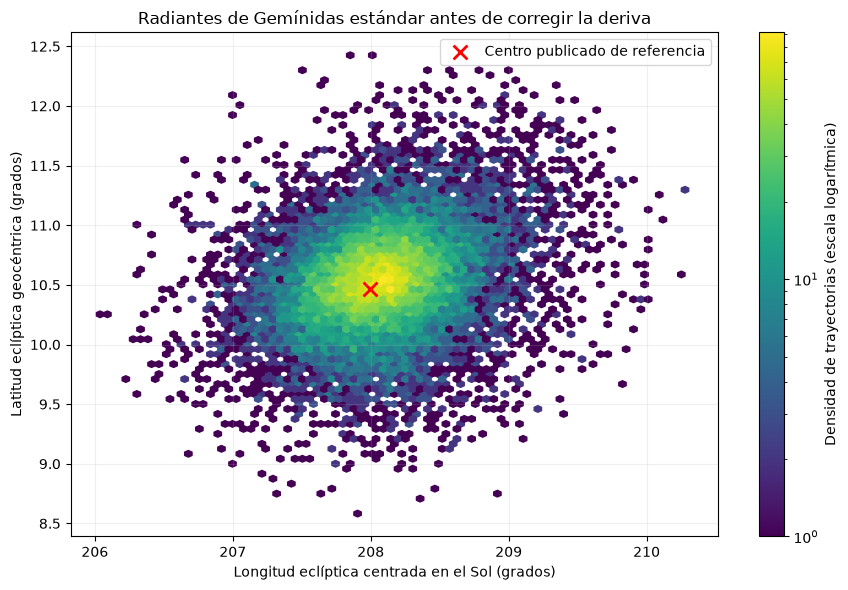

In [35]:
# Visualizar la distribución preliminar de radiantes estándar en coordenadas eclípticas centradas en el Sol

fig, ax = plt.subplots(figsize = (9, 6))

grafico_densidad = ax.hexbin(
    df_gem_estandar["lambda_sce_deg"],
    df_gem_estandar["BETgeo (deg)"],
    gridsize=80,
    mincnt=1,
    bins="log",
    cmap="viridis",
)

ax.scatter(
    207.995,
    10.466,
    color="red",
    marker="x",
    s=100,
    linewidths=2,
    label="Centro publicado de referencia",
)

barra_color = fig.colorbar(
    grafico_densidad,
    ax = ax
)

barra_color.set_label("Densidad de trayectorias (escala logarítmica)")

ax.set_xlabel("Longitud eclíptica centrada en el Sol (grados)")
ax.set_ylabel("Latitud eclíptica geocéntrica (grados)")
ax.set_title("Radiantes de Gemínidas estándar antes de corregir la deriva")
ax.legend()
ax.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

In [36]:
# Calcular la separación agnular firmada respecto de la longitud solar de referencia

LONGITUD_SOLAR_REFERENCIA = 262.2

def diferencia_angular_firmada(angulo_deg, referencia_deg):
    angulo_deg = np.asarray(angulo_deg, dtype = float)
    
    diferencia = ((angulo_deg - referencia_deg + 180.0) % 360) - 180
    
    return diferencia

def agregar_delta_longitud_solar(df_entrada, referencia_deg = LONGITUD_SOLAR_REFERENCIA):
    df_salida = df_entrada.copy()
    
    df_salida["delta_sol_lon_deg"] = diferencia_angular_firmada(df_salida["Sol lon (deg)"], referencia_deg)
    
    return df_salida

df_gem_catalogo = agregar_delta_longitud_solar(df_gem_catalogo)
df_gem_estandar = agregar_delta_longitud_solar(df_gem_estandar)
df_gem_estricta = agregar_delta_longitud_solar(df_gem_estricta)

print("Longitud solar de referencia: ", LONGITUD_SOLAR_REFERENCIA, "grados")
print("Variable añadida: delta_sol_lon_deg")

Longitud solar de referencia:  262.2 grados
Variable añadida: delta_sol_lon_deg


In [46]:
# Resumir la cobertura en longitud solar de la muestra estándar para cada año

resumen_cobertura_anual = df_gem_estandar.groupby("source_year")["delta_sol_lon_deg"].agg(
    geminidas="size",
    minimo="min",
    percentil_5=lambda serie: serie.quantile(0.05),
    percentil_25=lambda serie: serie.quantile(0.25),
    mediana="median",
    percentil_75=lambda serie: serie.quantile(0.75),
    percentil_95=lambda serie: serie.quantile(0.95),
    maximo="max",
).reset_index()

columnas_cobertura = [
    "minimo",
    "percentil_5",
    "percentil_25",
    "mediana",
    "percentil_75",
    "percentil_95",
    "maximo",
]

resumen_cobertura_anual[columnas_cobertura] = resumen_cobertura_anual[columnas_cobertura].round(4)

resumen_cobertura_anual["observaciones_antes_referencia"] = (
    df_gem_estandar
    .assign(antes = df_gem_estandar["delta_sol_lon_deg"].lt(0))
    .groupby("source_year")["antes"].sum().to_numpy()
)

resumen_cobertura_anual["observaciones_despues_referencia"] = (
    df_gem_estandar
    .assign(despues = df_gem_estandar["delta_sol_lon_deg"].ge(0))
    .groupby("source_year")["despues"].sum().to_numpy()
)

display(resumen_cobertura_anual)

,source_year,geminidas,minimo,percentil_5,percentil_25,mediana,percentil_75,percentil_95,maximo,observaciones_antes_referencia,observaciones_despues_referencia
0,2019,443,-10.1547,-3.9994,-0.6711,-0.0289,0.1562,0.6360,2.3133,233,210
1,2020,1051,-9.0653,-3.7244,-0.8289,-0.2018,0.1127,0.9381,3.9338,681,370
2,2021,2023,-11.0272,-5.2140,-1.3890,-0.7835,-0.1098,0.6392,2.9112,1687,336
3,2022,3769,-10.8847,-2.9098,-0.7137,-0.1832,0.3145,0.6983,4.5274,2302,1467
4,2023,3538,-10.5667,-4.4691,-1.0428,-0.4901,0.1056,0.6360,4.2150,2501,1037
5,2024,2622,-11.1483,-5.3405,-1.0310,-0.2936,0.1877,0.5276,3.5328,1619,1003
6,2025,6312,-10.6368,-3.4445,-1.2155,-0.4243,-0.0572,0.6081,4.3023,4878,1434


In [47]:
# Agrupar las Gemínidas estándar en intervalos de un grado de longitud solar

ANCHO_INTERVALO_SOLAR = 1.0

limite_inferior = np.floor(df_gem_estandar["delta_sol_lon_deg"].min())
limite_superior = np.ceil(df_gem_estandar["delta_sol_lon_deg"].max())

bordes_solares = np.arange(
    limite_inferior,
    limite_superior
    + ANCHO_INTERVALO_SOLAR,
    ANCHO_INTERVALO_SOLAR,
)

datos_binning = df_gem_estandar[
    [
        "delta_sol_lon_deg",
        "lambda_sce_deg",
        "BETgeo (deg)",
        "Vgeo (km/s)",
    ]
].copy()

datos_binning["intervalo_solar"] = pd.cut(
    datos_binning["delta_sol_lon_deg"],
    bins = bordes_solares,
    right = False,
    include_lowest = True,
)

resumen_intervalos = datos_binning.groupby("intervalo_solar", observed = True).agg(
    geminidas=(
            "delta_sol_lon_deg",
            "size",
    ),
    delta_sol_mediana=(
        "delta_sol_lon_deg",
        "median",
    ),
    lambda_sce_mediana=(
        "lambda_sce_deg",
        "median",
    ),
    beta_mediana=(
        "BETgeo (deg)",
        "median",
    ),
    vgeo_mediana=(
        "Vgeo (km/s)",
        "median",
    ),
).reset_index()

resumen_intervalos["centro_intervalo"] = resumen_intervalos["intervalo_solar"].apply(lambda intervalo: intervalo.mid).astype(float)
resumen_intervalos["usar_en_grafica"] = resumen_intervalos["geminidas"].ge(30)

columnas_redondear = [
    "delta_sol_mediana",
    "lambda_sce_mediana",
    "beta_mediana",
    "vgeo_mediana",
    "centro_intervalo",
]

resumen_intervalos[columnas_redondear] = resumen_intervalos[columnas_redondear].round(4)

display(resumen_intervalos)

,intervalo_solar,geminidas,delta_sol_mediana,lambda_sce_mediana,beta_mediana,vgeo_mediana,centro_intervalo,usar_en_grafica
0,"[-12.0, -11.0)",2,-11.0877,208.3430,10.1854,33.6816,-11.5,False
1,"[-11.0, -10.0)",25,-10.3925,209.1015,10.4492,33.4196,-10.5,False
2,"[-10.0, -9.0)",37,-9.3294,208.8157,10.5295,33.1722,-9.5,True
3,"[-9.0, -8.0)",58,-8.4552,208.6694,10.6331,33.2026,-8.5,True
4,"[-8.0, -7.0)",89,-7.5549,208.8495,10.9099,33.1006,-7.5,True
5,"[-7.0, -6.0)",151,-6.4664,208.6684,10.6829,33.2587,-6.5,True
6,"[-6.0, -5.0)",237,-5.4370,208.5890,10.7278,33.4002,-5.5,True
7,"[-5.0, -4.0)",397,-4.4458,208.4373,10.6415,33.4912,-4.5,True
8,"[-4.0, -3.0)",620,-3.3882,208.3228,10.6644,33.5641,-3.5,True
9,"[-3.0, -2.0)",971,-2.3740,208.2569,10.6886,33.6995,-2.5,True


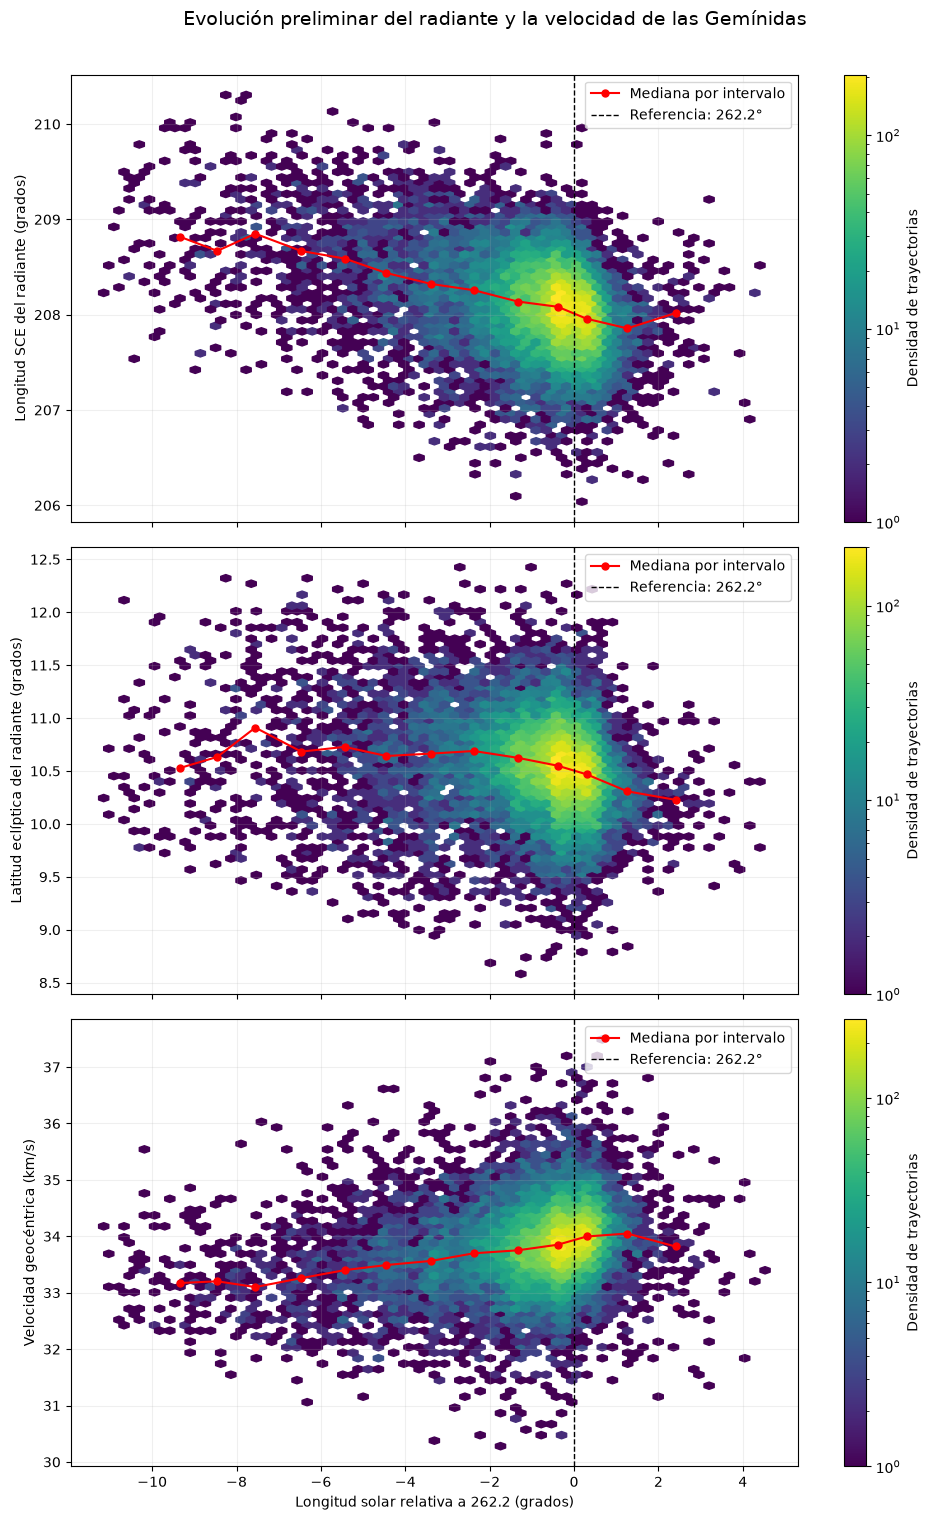

In [51]:
# Visualizar las tendencias del radiante y la velocidad respecto de la longitud solar

intervalos_estables = resumen_intervalos.loc[resumen_intervalos["usar_en_grafica"]].copy()

fig, ejes = plt.subplots(
    nrows = 3,
    ncols = 1,
    figsize = (10, 15),
    sharex = True
)

variables_grafica = [
    (
        "lambda_sce_deg",
        "lambda_sce_mediana",
        "Longitud SCE del radiante (grados)",
    ),
    (
        "BETgeo (deg)",
        "beta_mediana",
        "Latitud eclíptica del radiante (grados)",
    ),
    (
        "Vgeo (km/s)",
        "vgeo_mediana",
        "Velocidad geocéntrica (km/s)",
    )
]

for eje, (columna_datos, columna_mediana, etiqueta_y) in zip(ejes, variables_grafica):
    densidad = eje.hexbin(
        df_gem_estandar["delta_sol_lon_deg"],
        df_gem_estandar[columna_datos],
        gridsize=65,
        mincnt=1,
        bins="log",
        cmap="viridis",
    )
    
    eje.plot(
        intervalos_estables["delta_sol_mediana"],
        intervalos_estables[columna_mediana],
        color="red",
        marker="o",
        markersize=5,
        linewidth=1.5,
        label="Mediana por intervalo",
    )
    
    eje.axvline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1,
        label="Referencia: 262.2°",
    )
    
    eje.set_ylabel(etiqueta_y)
    eje.grid(alpha = 0.2)
    eje.legend()
    
    barra_color = fig.colorbar(densidad, ax = eje)
    
    barra_color.set_label("Densidad de trayectorias")
    
ejes[-1].set_xlabel("Longitud solar relativa a 262.2 (grados)")

fig.suptitle("Evolución preliminar del radiante y la velocidad de las Gemínidas", fontsize = 14, y = 1.01)

plt.tight_layout()
plt.show()

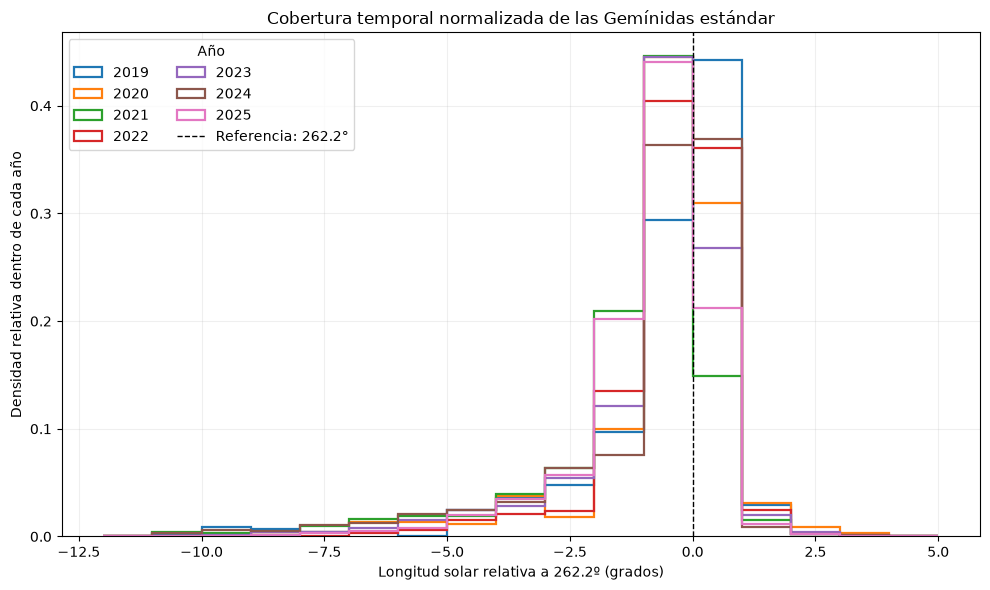

In [56]:
# Comparar la forma de la cobertura temporal de cada año sin usar los conteos absolutos

fig, ax = plt.subplots(figsize = (10, 6))

for anio, grupo_anual in df_gem_estandar.groupby("source_year", sort = True):
    ax.hist(
        grupo_anual["delta_sol_lon_deg"],
        bins=bordes_solares,
        density=True,
        histtype="step",
        linewidth=1.6,
        label=str(anio),
    )
    
ax.axvline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Referencia: 262.2°",
)

ax.set_xlabel("Longitud solar relativa a 262.2º (grados)")
ax.set_ylabel("Densidad relativa dentro de cada año")
ax.set_title("Cobertura temporal normalizada de las Gemínidas estándar")

ax.grid(alpha = 0.2)
ax.legend(title = "Año", ncol = 2)

plt.tight_layout()
plt.show()

In [57]:
# Marcar las observaciones qeu pertenecen a la ventana principal para ajustar la deriva

LIMITE_INFERIOR_DERIVA = -5.0
LIMITE_SUPERIOR_DERIVA = 2.0

def agregar_flag_ventana_deriva(df_entrada):
    df_salida = df_entrada.copy()
    
    df_salida["en_ventana_deriva"] = df_salida["delta_sol_lon_deg"].ge(LIMITE_INFERIOR_DERIVA) & df_salida["delta_sol_lon_deg"].lt(LIMITE_SUPERIOR_DERIVA)
    
    return df_salida
    
df_gem_catalogo = agregar_flag_ventana_deriva(df_gem_catalogo)
df_gem_estandar = agregar_flag_ventana_deriva(df_gem_estandar)
df_gem_estricta = agregar_flag_ventana_deriva(df_gem_estricta)

resumen_ventana_muestras = pd.DataFrame(
    {
        "muestra": [
            "Catálogo",
            "Estándar",
            "Estricta",
        ],
        "trayectorias_totales": [
            len(df_gem_catalogo),
            len(df_gem_estandar),
            len(df_gem_estricta),
        ],
        "dentro_ventana": [
            df_gem_catalogo[
                "en_ventana_deriva"
            ].sum(),
            df_gem_estandar[
                "en_ventana_deriva"
            ].sum(),
            df_gem_estricta[
                "en_ventana_deriva"
            ].sum(),
        ],
    }
)

resumen_ventana_muestras["fuera_ventana"] = resumen_ventana_muestras["trayectorias_totales"] - resumen_ventana_muestras["dentro_ventana"]
resumen_ventana_muestras["retencion_porcentaje"] = (100 * resumen_ventana_muestras["dentro_ventana"] / resumen_ventana_muestras["trayectorias_totales"]).round(2)

print(f"Ventana de deriva: {LIMITE_INFERIOR_DERIVA}, {LIMITE_SUPERIOR_DERIVA} grados.")
display(resumen_ventana_muestras)

Ventana de deriva: -5.0, 2.0 grados.


,muestra,trayectorias_totales,dentro_ventana,fuera_ventana,retencion_porcentaje
0,Catálogo,104678,101234,3444,96.71
1,Estándar,19758,19079,679,96.56
2,Estricta,7268,7040,228,96.86


In [58]:
# Comprobar cuántas Gemínidas estándar conserva la ventana de deriva en cada año

resumen_ventana_anual = df_gem_estandar.groupby("source_year").agg(
    geminidas_totales = ("Unique trajectory (identifier)", "size"),
    geminidas_en_ventana = ("en_ventana_deriva", "sum"),
).reset_index()

resumen_ventana_anual["geminidas_fuera_ventana"] = resumen_ventana_anual["geminidas_totales"] - resumen_ventana_anual["geminidas_en_ventana"]
resumen_ventana_anual["retencion_porcentaje"] = (100 * resumen_ventana_anual["geminidas_en_ventana"] / resumen_ventana_anual["geminidas_totales"]).round(2)

display(resumen_ventana_anual)

if (resumen_ventana_anual["geminidas_en_ventana"] < 30).any():
    raise ValueError("Algún año tiene muy pocas observaciones para ajustar una recta.")

print("\nTodos los años conservan suficientes observaciones.")

,source_year,geminidas_totales,geminidas_en_ventana,geminidas_fuera_ventana,retencion_porcentaje
0,2019,443,430,13,97.07
1,2020,1051,1002,49,95.34
2,2021,2023,1904,119,94.12
3,2022,3769,3712,57,98.49
4,2023,3538,3397,141,96.01
5,2024,2622,2459,163,93.78
6,2025,6312,6175,137,97.83



Todos los años conservan suficientes observaciones.


In [62]:
# Definir y comprobar una función de mínimos cuadrados ordinarios para ajustar una recta

def ajustar_recta_ols(x, y):
    x = np.asarray(x, dtype = float)
    y = np.asarray(y, dtype = float)
    
    valores_validos = np.isfinite(x) & np.isfinite(y)
    
    x = x[valores_validos]
    y = y[valores_validos]
    
    n = len(x)
    
    if n < 3:
        raise ValueError("Se necesitan al menos tres observaciones para ajustar la recta.")
    
    matriz_diseno = np.column_stack((np.ones(n), x))
    
    coeficientes = np.linalg.lstsq(matriz_diseno, y, rcond = None)[0]
    intercepto = coeficientes[0]
    pendiente = coeficientes[1]
    
    y_estimado = intercepto + pendiente * x
    
    residuos = y - y_estimado
    
    suma_cuadrados_residuos = np.sum(residuos ** 2)
    suma_cuadrados_total = np.sum((y - y.mean()) ** 2)
    
    grados_libertad = n - 2
    
    varianza_residual = suma_cuadrados_residuos / grados_libertad
    covarianza_coeficientes = varianza_residual * np.linalg.pinv(matriz_diseno.T @ matriz_diseno)
    
    errores_estandar = np.sqrt(np.diag(covarianza_coeficientes))
    
    r_cuadrada = 1.0 - suma_cuadrados_residuos / suma_cuadrados_total
    
    rmse = np.sqrt(np.mean(residuos ** 2))
    
    return {
        "n": n,
        "intercepto": intercepto,
        "pendiente": pendiente,
        "error_estandar_intercepto": (
            errores_estandar[0]
        ),
        "error_estandar_pendiente": (
            errores_estandar[1]
        ),
        "r_cuadrada": r_cuadrada,
        "rmse": rmse,
    }
    
x_prueba = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
y_prueba = 3.0 + 2.0 * x_prueba

ajuste_prueba = ajustar_recta_ols(x_prueba, y_prueba)

if not np.isclose(ajuste_prueba["intercepto"], 3):
    raise ValueError("La función no recuperó el intercepto de prueba.")

if not np.isclose(ajuste_prueba["pendiente"], 2.0):
    raise ValueError("La función no recuperó la pendiente de prueba.")

if not np.isclose(ajuste_prueba["r_cuadrada"], 1.0):
    raise ValueError("La función no recuperó R^2 = 1 en la prueba.")

print("Resultado de la prueba: ")

display(pd.DataFrame([ajuste_prueba]).round(10))

print("\nLa función de regresión lineal superó la prueba.")

Resultado de la prueba: 


,n,intercepto,pendiente,error_estandar_intercepto,error_estandar_pendiente,r_cuadrada,rmse
0,5,3.0,2.0,0.0,0.0,1.0,0.0



La función de regresión lineal superó la prueba.


In [63]:
# Ajustar por separado la deriva anual de longitud, latitud y velocidad geocéntrica

variables_deriva = {
    "lambda_sce": {
        "columna": "lambda_sce_deg",
        "intercepto_publicado": 207.995,
        "pendiente_publicada": -0.092,
    },
    "beta_geo": {
        "columna": "BETgeo (deg)",
        "intercepto_publicado": 10.466,
        "pendiente_publicada": -0.103,
    },
    "vgeo": {
        "columna": "Vgeo (km/s)",
        "intercepto_publicado": 33.881,
        "pendiente_publicada": 0.088,
    },
}

muestra_ajuste = df_gem_estandar.loc[df_gem_estandar["en_ventana_deriva"]].copy()

registros_ajustes_anuales = []

for anio, grupo_anual in muestra_ajuste.groupby("source_year", sort = True):
    x = grupo_anual["delta_sol_lon_deg"]
    
    for nombre_variable, informacion in variables_deriva.items():
        resultado = ajustar_recta_ols(x, grupo_anual[informacion["columna"]])
        
        registros_ajustes_anuales.append(
            {
                "anio": int(anio),
                "variable": nombre_variable,
                "n": resultado["n"],
                "intercepto": resultado["intercepto"],
                "error_estandar_intercepto": (resultado["error_estandar_intercepto"]),
                "intercepto_publicado": (informacion["intercepto_publicado"]),
                "diferencia_intercepto": (resultado["intercepto"] - informacion["intercepto_publicado"]),
                "pendiente": resultado["pendiente"],
                "error_estandar_pendiente": (resultado["error_estandar_pendiente"]),
                "pendiente_publicada": (informacion["pendiente_publicada"]),
                "diferencia_pendiente": (resultado["pendiente"] - informacion["pendiente_publicada"]),
                "r_cuadrada": resultado["r_cuadrada"],
                "rmse": resultado["rmse"],
            }
        )

ajustes_anuales = pd.DataFrame(registros_ajustes_anuales)

ajustes_anuales = ajustes_anuales.sort_values(["variable", "anio"]).reset_index(drop = True)

display(ajustes_anuales.round(
    {
        "intercepto": 5,
            "error_estandar_intercepto": 5,
            "intercepto_publicado": 5,
            "diferencia_intercepto": 5,
            "pendiente": 5,
            "error_estandar_pendiente": 5,
            "pendiente_publicada": 5,
            "diferencia_pendiente": 5,
            "r_cuadrada": 5,
            "rmse": 5,
    }
))

,anio,variable,n,intercepto,error_estandar_intercepto,intercepto_publicado,diferencia_intercepto,pendiente,error_estandar_pendiente,pendiente_publicada,diferencia_pendiente,r_cuadrada,rmse
0,2019,beta_geo,430,10.44465,0.02261,10.466,-0.02135,-0.03320,0.01749,-0.103,0.06980,0.00835,0.43153
1,2020,beta_geo,1002,10.48754,0.01452,10.466,0.02154,-0.06251,0.01287,-0.103,0.04049,0.02305,0.41648
2,2021,beta_geo,1904,10.49147,0.01145,10.466,0.02547,-0.06936,0.00835,-0.103,0.03364,0.03498,0.40263
3,2022,beta_geo,3712,10.48796,0.00634,10.466,0.02196,-0.06048,0.00575,-0.103,0.04252,0.02896,0.36240
4,2023,beta_geo,3397,10.49867,0.00725,10.466,0.03267,-0.05748,0.00558,-0.103,0.04552,0.03026,0.36748
5,2024,beta_geo,2459,10.51150,0.00861,10.466,0.04550,-0.04577,0.00651,-0.103,0.05723,0.01969,0.38343
6,2025,beta_geo,6175,10.51705,0.00568,10.466,0.05105,-0.05047,0.00435,-0.103,0.05253,0.02135,0.37498
7,2019,lambda_sce,430,207.95245,0.02284,207.995,-0.04255,-0.06818,0.01767,-0.092,0.02382,0.03362,0.43605
8,2020,lambda_sce,1002,208.01134,0.01510,207.995,0.01634,-0.08458,0.01338,-0.092,0.00742,0.03842,0.43306
9,2021,lambda_sce,1904,207.96408,0.01249,207.995,-0.03092,-0.11961,0.00911,-0.092,-0.02761,0.08309,0.43911


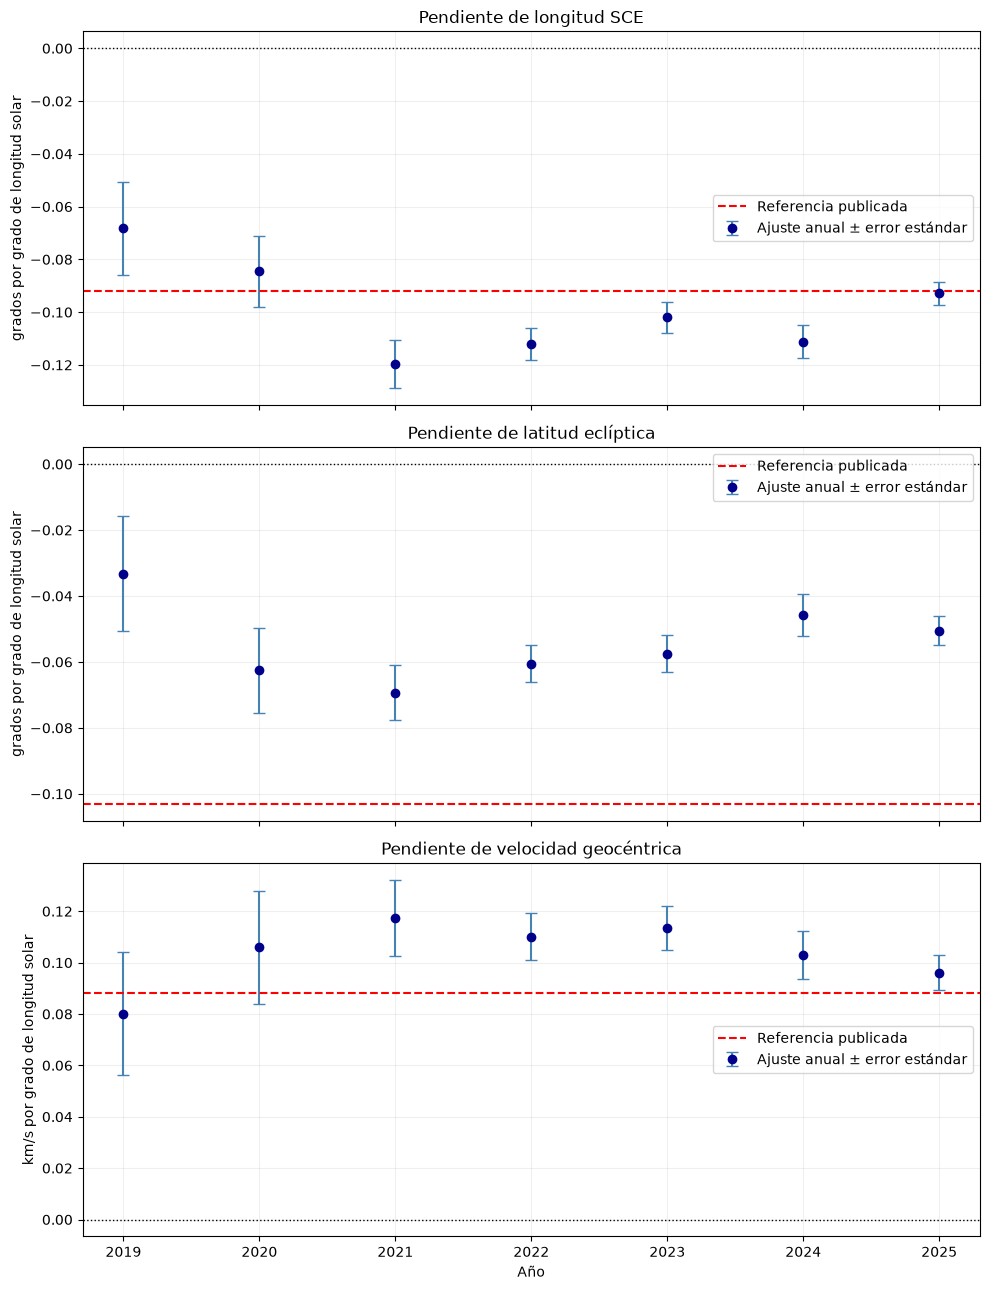

In [64]:
# Comparar visualmente las pendientes obtenidas en cada año con las referencias publicadas

fig, ejes = plt.subplots(nrows = 3, ncols = 1, figsize = (10, 13), sharex = True)

configuracion_graficas = [
    (
        "lambda_sce",
        "Pendiente de longitud SCE",
        "grados por grado de longitud solar",
    ),
    (
        "beta_geo",
        "Pendiente de latitud eclíptica",
        "grados por grado de longitud solar",
    ),
    (
        "vgeo",
        "Pendiente de velocidad geocéntrica",
        "km/s por grado de longitud solar",
    ),
]

for eje, (nombre_variable, titulo, unidad) in zip(ejes, configuracion_graficas):
    datos_variable = ajustes_anuales.loc[ajustes_anuales["variable"].eq(nombre_variable)].copy()
    
    pendiente_publicada = datos_variable["pendiente_publicada"].iloc[0]
    
    eje.errorbar(
        datos_variable["anio"],
        datos_variable["pendiente"],
        yerr=datos_variable["error_estandar_pendiente"],
        fmt="o",
        color="darkblue",
        ecolor="steelblue",
        capsize=4,
        markersize=6,
        label="Ajuste anual ± error estándar",
    )
    
    eje.axhline(
        pendiente_publicada,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Referencia publicada",
    )
    
    eje.axhline(
        0.0,
        color="black",
        linestyle=":",
        linewidth=1,
    )
    
    eje.set_title(titulo)
    eje.set_ylabel(unidad)
    eje.grid(alpha = 0.2)
    eje.legend()
    
ejes[-1].set_xlabel("Año")

plt.tight_layout()
plt.show()

In [70]:
# Ajustar las derivas anuales en las muestras estándar y estricta para comparar su estabilidad

def ajustar_derivas_por_anio(df_entrada, nombre_muestra):
    muestra_ventana = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    registros = []
    
    for anio, grupo_anual in muestra_ventana.groupby("source_year", sort = True):
        x = grupo_anual["delta_sol_lon_deg"]
        
        for nombre_variable, informacion in variables_deriva.items():
            resultado = ajustar_recta_ols(x, grupo_anual[informacion["columna"]])
            
            registros.append(
                {
                    "muestra": nombre_muestra,
                    "anio": int(anio),
                    "variable": nombre_variable,
                    "n": resultado["n"],
                    "intercepto": resultado["intercepto"],
                    "error_estandar_intercepto": (
                        resultado[
                            "error_estandar_intercepto"
                        ]
                    ),
                    "pendiente": resultado["pendiente"],
                    "error_estandar_pendiente": (
                        resultado[
                            "error_estandar_pendiente"
                        ]
                    ),
                    "r_cuadrada": resultado["r_cuadrada"],
                    "rmse": resultado["rmse"],
                }
            )
    return pd.DataFrame(registros).sort_values(["variable", "anio"]).reset_index(drop = True)

ajustes_estandar_validacion = ajustar_derivas_por_anio(df_gem_estandar, "Estándar")
ajustes_estricta = ajustar_derivas_por_anio(df_gem_estricta, "Estricta")

pendientes_previas = ajustes_anuales.sort_values(["variable", "anio"])["pendiente"].to_numpy()
pendientes_recalculadas = ajustes_estandar_validacion["pendiente"].to_numpy()

if not np.allclose(pendientes_previas, pendientes_recalculadas, atol = 1e-12):
    raise ValueError("Los ajsutes estándar recalculados no coinciden con los obtenidos anteriormente.")

comparacion_estandar_estricta = (
    ajustes_estandar_validacion[
        [
            "anio",
            "variable",
            "n",
            "pendiente",
            "error_estandar_pendiente",
            "intercepto",
            "rmse",
        ]
    ].merge(
        ajustes_estricta[
            [
                "anio",
                "variable",
                "n",
                "pendiente",
                "error_estandar_pendiente",
                "intercepto",
                "rmse",
            ]
        ],
        on=["anio", "variable"],
        how="inner",
        suffixes=("_estandar", "_estricta"),
    )
)

comparacion_estandar_estricta["diferencia_pendiente"] = comparacion_estandar_estricta["pendiente_estricta"] - comparacion_estandar_estricta["pendiente_estandar"]
comparacion_estandar_estricta["diferencia_intercepto"] = comparacion_estandar_estricta["intercepto_estricta"] - comparacion_estandar_estricta["intercepto_estandar"]

display(comparacion_estandar_estricta.round(
    {
        "pendiente_estandar": 5,
            "error_estandar_pendiente_estandar": 5,
            "pendiente_estricta": 5,
            "error_estandar_pendiente_estricta": 5,
            "diferencia_pendiente": 5,
            "intercepto_estandar": 5,
            "intercepto_estricta": 5,
            "diferencia_intercepto": 5,
            "rmse_estandar": 5,
            "rmse_estricta": 5,
    }
))

,anio,variable,n_estandar,pendiente_estandar,error_estandar_pendiente_estandar,intercepto_estandar,rmse_estandar,n_estricta,pendiente_estricta,error_estandar_pendiente_estricta,intercepto_estricta,rmse_estricta,diferencia_pendiente,diferencia_intercepto
0,2019,beta_geo,430,-0.03320,0.01749,10.44465,0.43153,99,-0.07458,0.02927,10.45196,0.33401,-0.04138,0.00730
1,2020,beta_geo,1002,-0.06251,0.01287,10.48754,0.41648,174,-0.06660,0.02217,10.48016,0.36892,-0.00409,-0.00738
2,2021,beta_geo,1904,-0.06936,0.00835,10.49147,0.40263,293,-0.05268,0.01731,10.52883,0.39858,0.01669,0.03736
3,2022,beta_geo,3712,-0.06048,0.00575,10.48796,0.36240,1755,-0.07152,0.00751,10.48385,0.32857,-0.01104,-0.00411
4,2023,beta_geo,3397,-0.05748,0.00558,10.49867,0.36748,1267,-0.04895,0.00787,10.50302,0.34453,0.00853,0.00435
5,2024,beta_geo,2459,-0.04577,0.00651,10.51150,0.38343,578,-0.04932,0.01348,10.51218,0.36064,-0.00355,0.00068
6,2025,beta_geo,6175,-0.05047,0.00435,10.51705,0.37498,2874,-0.05098,0.00642,10.53163,0.34808,-0.00051,0.01459
7,2019,lambda_sce,430,-0.06818,0.01767,207.95245,0.43605,99,-0.11055,0.03194,207.95863,0.36437,-0.04237,0.00618
8,2020,lambda_sce,1002,-0.08458,0.01338,208.01134,0.43306,174,-0.08008,0.02308,207.98641,0.38408,0.00450,-0.02493
9,2021,lambda_sce,1904,-0.11961,0.00911,207.96408,0.43911,293,-0.11039,0.01983,208.00607,0.45654,0.00922,0.04199


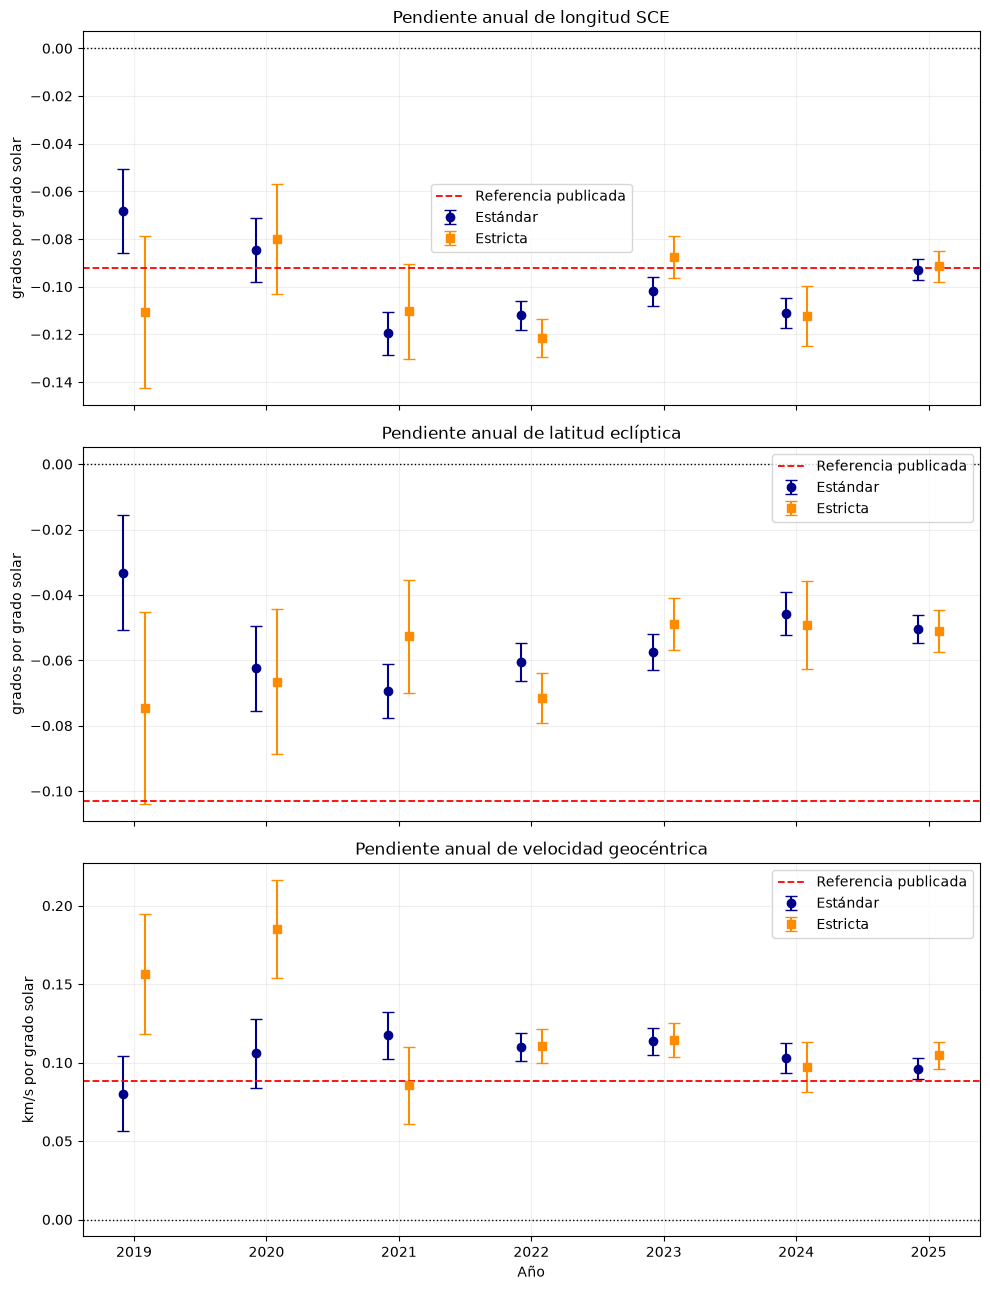

In [71]:
# Comparar visualmente las pendientes anuales de las muestras estándar y estricta

fig, ejes = plt.subplots(nrows = 3, ncols = 1, figsize = (10, 13), sharex = True)

configuracion_comparacion = [
    (
        "lambda_sce",
        "Pendiente anual de longitud SCE",
        "grados por grado solar",
    ),
    (
        "beta_geo",
        "Pendiente anual de latitud eclíptica",
        "grados por grado solar",
    ),
    (
        "vgeo",
        "Pendiente anual de velocidad geocéntrica",
        "km/s por grado solar",
    ),
]

DESPLAZAMIENTO_HORIZONTAL = 0.08

for eje, (nombre_variable, titulo, unidad) in zip(ejes, configuracion_comparacion): 
    datos = comparacion_estandar_estricta.loc[comparacion_estandar_estricta["variable"].eq(nombre_variable)].copy()
    
    pendiente_publicada = variables_deriva[nombre_variable]["pendiente_publicada"]
    
    eje.errorbar(
        datos["anio"] - DESPLAZAMIENTO_HORIZONTAL,
        datos["pendiente_estandar"],
        yerr=datos[
            "error_estandar_pendiente_estandar"
        ],
        fmt="o",
        capsize=4,
        color="darkblue",
        label="Estándar",
    )
    
    eje.errorbar(
        datos["anio"] + DESPLAZAMIENTO_HORIZONTAL,
        datos["pendiente_estricta"],
        yerr=datos[
            "error_estandar_pendiente_estricta"
        ],
        fmt="s",
        capsize=4,
        color="darkorange",
        label="Estricta",
    )
    
    eje.axhline(
        pendiente_publicada,
        color="red",
        linestyle="--",
        linewidth=1.3,
        label="Referencia publicada",
    )
    
    eje.axhline(
        0.0,
        color="black",
        linestyle=":",
        linewidth=1,
    )
    
    eje.set_title(titulo)
    eje.set_ylabel(unidad)
    eje.grid(alpha = 0.2)
    eje.legend()
    
ejes[-1].set_xlabel("Año")

plt.tight_layout()
plt.show()

In [76]:
# Definir un modelo con una pendiente común y un intercepto diferente para cada año

def ajustar_pendiente_comun_con_interceptos_anuales(df_entrada, columna_respuesta):
    
    muestra = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    x = muestra["delta_sol_lon_deg"].to_numpy(dtype = float)
    y = muestra[columna_respuesta].to_numpy(dtype = float)
    
    anios = muestra["source_year"].to_numpy(dtype = float)
    anios_unicos = np.sort(np.unique(anios))
    
    columnas_anuales = np.column_stack([(anios == anio).astype(float) for anio in anios_unicos])
    
    matriz_diseno = np.column_stack((columnas_anuales, x))
    
    coeficientes = np.linalg.lstsq(matriz_diseno, y, rcond = None)[0]
    
    interceptos = coeficientes[:-1]
    pendiente_comun = coeficientes[-1]
    
    y_estimado = matriz_diseno @ coeficientes
    residuos = y - y_estimado
    
    n = len(y)
    numero_parametros = matriz_diseno.shape[1]
    grados_libertad = n - numero_parametros
    
    suma_cuadrados_residuos = np.sum(residuos ** 2)
    suma_cuadrados_total = np.sum((y - y.mean()) ** 2)
    
    varianza_residual = suma_cuadrados_residuos / grados_libertad
    
    covarianza_coeficientes = varianza_residual * np.linalg.pinv(matriz_diseno.T @ matriz_diseno)
    
    errores_estandar = np.sqrt(np.diag(covarianza_coeficientes))
    
    r_cuadrada = 1.0 - suma_cuadrados_residuos / suma_cuadrados_total
    
    rmse = np.sqrt(np.mean(residuos ** 2))
    
    tabla_interceptos = pd.DataFrame(
        {
            "anio": anios_unicos,
            "intercepto": interceptos,
            "error_estandar_intercepto": (errores_estandar[:-1]),
        }
    )
    
    return {
        "n": n,
        "numero_parametros": numero_parametros,
        "pendiente_comun": pendiente_comun,
        "error_estandar_pendiente": (
            errores_estandar[-1]
        ),
        "r_cuadrada": r_cuadrada,
        "rmse": rmse,
        "interceptos": tabla_interceptos,
    }
    
modelos_pendiente_comun = {}
registros_pendiente_comun = []
registros_interceptos_comunes = []

for nombre_variable, informacion in variables_deriva.items():
    resultado = ajustar_pendiente_comun_con_interceptos_anuales(df_gem_estandar, informacion["columna"])
    
    modelos_pendiente_comun[nombre_variable] = resultado
    
    pendientes_anuales_variable = ajustes_estandar_validacion.loc[ajustes_estandar_validacion["variable"].eq(nombre_variable), "pendiente"]
    
    registros_pendiente_comun.append(
        {
            "variable": nombre_variable,
            "n": resultado["n"],
            "numero_parametros": (resultado["numero_parametros"]),
            "pendiente_comun": (resultado["pendiente_comun"]),
            "error_estandar_pendiente": (resultado["error_estandar_pendiente"]),
            "pendiente_publicada": (informacion["pendiente_publicada"]),
            "diferencia_publicada": (resultado["pendiente_comun"] - informacion["pendiente_publicada"]),
            "pendiente_anual_minima": (pendientes_anuales_variable.min()),
            "pendiente_anual_maxima": (pendientes_anuales_variable.max()),
            "r_cuadrada": resultado["r_cuadrada"],
            "rmse": resultado["rmse"],
        }
    )
    
    tabla_interceptos_variable = resultado["interceptos"].copy()
    
    tabla_interceptos_variable["variable"] = nombre_variable
    
    registros_interceptos_comunes.append(tabla_interceptos_variable)
    
ajustes_pendiente_comun = pd.DataFrame(registros_pendiente_comun)

interceptos_modelo_comun = pd.concat(registros_interceptos_comunes, ignore_index = True)

display(
    ajustes_pendiente_comun.round(
        {
            "pendiente_comun": 5,
            "error_estandar_pendiente": 5,
            "pendiente_publicada": 5,
            "diferencia_publicada": 5,
            "pendiente_anual_minima": 5,
            "pendiente_anual_maxima": 5,
            "r_cuadrada": 5,
            "rmse": 5,
        }
    )
)

print("\nInterceptos anuales del modelo común: ")

display(interceptos_modelo_comun[["variable", "anio", "intercepto", "error_estandar_intercepto"]].round(5))
    

,variable,n,numero_parametros,pendiente_comun,error_estandar_pendiente,pendiente_publicada,diferencia_publicada,pendiente_anual_minima,pendiente_anual_maxima,r_cuadrada,rmse
0,lambda_sce,19079,8,-0.10225,0.00257,-0.092,-0.01025,-0.11961,-0.06818,0.08224,0.39203
1,beta_geo,19079,8,-0.05477,0.00249,-0.103,0.04823,-0.06936,-0.03320,0.02722,0.37897
2,vgeo,19079,8,0.10493,0.00390,0.088,0.01693,0.08014,0.11732,0.04069,0.59395



Interceptos anuales del modelo común: 


,variable,anio,intercepto,error_estandar_intercepto
0,lambda_sce,2019.0,207.93548,0.01895
1,lambda_sce,2020.0,208.00295,0.01245
2,lambda_sce,2021.0,207.97817,0.00923
3,lambda_sce,2022.0,207.96825,0.00651
4,lambda_sce,2023.0,208.03508,0.00693
5,lambda_sce,2024.0,208.00941,0.00805
6,lambda_sce,2025.0,208.00486,0.00531
7,beta_geo,2019.0,10.43391,0.01832
8,beta_geo,2020.0,10.49122,0.01203
9,beta_geo,2021.0,10.50330,0.00892


In [78]:
# Comparar el error del modelo de pendiente común con el de pendientes anuales

def calcular_rmse_pendientes_anuales(df_entrada, ajustes, nombre_variable, columna_respuesta):
    muestra = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    parametros = ajustes.loc[ajustes["variable"].eq(nombre_variable)].set_index("anio")
    
    interceptos_por_anio = muestra["source_year"].map(parametros["intercepto"])
    pendientes_por_anio = muestra["source_year"].map(parametros["pendiente"])
    
    valores_estimados = interceptos_por_anio + pendientes_por_anio * muestra["delta_sol_lon_deg"]
    
    residuos = muestra[columna_respuesta] - valores_estimados
    
    return np.sqrt(np.mean(residuos ** 2))

registros_comparacion_modelos = []

for nombre_variable, informacion in variables_deriva.items():
    rmse_anual = calcular_rmse_pendientes_anuales(df_gem_estandar, ajustes_estandar_validacion, nombre_variable, informacion["columna"])
    rmse_comun = modelos_pendiente_comun[nombre_variable]["rmse"]
    
    mejora_porcentaje = 100 * (rmse_comun - rmse_anual) / rmse_comun
    
    registros_comparacion_modelos.append(
        {
            "variable": nombre_variable,
            "parametros_modelo_comun": 8,
            "parametros_modelo_anual": 14,
            "rmse_pendiente_comun": rmse_comun,
            "rmse_pendientes_anuales": rmse_anual,
            "reduccion_rmse_porcentaje": (
                mejora_porcentaje
            ),
        }
    )
    
comparacion_modelos = pd.DataFrame(registros_comparacion_modelos)

display(comparacion_modelos.round(
    {
        "rmse_pendiente_comun": 6,
        "rmse_pendientes_anuales": 6,
        "reduccion_rmse_porcentaje": 4,
    }
))

,variable,parametros_modelo_comun,parametros_modelo_anual,rmse_pendiente_comun,rmse_pendientes_anuales,reduccion_rmse_porcentaje
0,lambda_sce,8,14,0.392032,0.391828,0.0520
1,beta_geo,8,14,0.378967,0.378868,0.0260
2,vgeo,8,14,0.593949,0.593871,0.0131


In [83]:
# Crear residuos provisioinales usando pendientes comunes e interceptos diferentes para cada año

df_residuos_comun = df_gem_estandar.loc[df_gem_estandar["en_ventana_deriva"]].copy()

especificaciones_deriva = {
    "lambda_sce": {
        "columna_observada": "lambda_sce_deg",
        "columna_esperada": "lambda_sce_esperada_comun",
        "columna_residuo": "residuo_lambda_sce_comun",
        "variable_angular": True,
    },
    "beta_geo": {
        "columna_observada": "BETgeo (deg)",
        "columna_esperada": "beta_esperada_comun",
        "columna_residuo": "residuo_beta_comun",
        "variable_angular": False,
    },
    "vgeo": {
        "columna_observada": "Vgeo (km/s)",
        "columna_esperada": "vgeo_esperada_comun",
        "columna_residuo": "residuo_vgeo_comun",
        "variable_angular": False,
    },
}

for variable_modelo, especificacion in especificaciones_deriva.items():
    fila_pendiente = ajustes_pendiente_comun.loc[ajustes_pendiente_comun["variable"].eq(variable_modelo)].iloc[0]
    
    pendiente = fila_pendiente["pendiente_comun"]
    
    tabla_interceptos = interceptos_modelo_comun.loc[interceptos_modelo_comun["variable"].eq(variable_modelo), ["anio", "intercepto"]].copy()
    
    tabla_interceptos["anio"] = tabla_interceptos["anio"].astype(int)
    
    mapa_interceptos = dict(zip(tabla_interceptos["anio"], tabla_interceptos["intercepto"]))
    
    intercepto_anual = df_residuos_comun["source_year"].map(mapa_interceptos)
    
    if intercepto_anual.isna().any():
        raise ValueError(f"Falta un intercepto anual para la variable {variable_modelo}")
    
    valor_esperado = intercepto_anual + pendiente * df_residuos_comun["delta_sol_lon_deg"]
    
    columna_observada = especificacion["columna_observada"]
    columna_esperada = especificacion["columna_esperada"]
    columna_residuo = especificacion["columna_residuo"]
    
    df_residuos_comun[columna_esperada] = valor_esperado
    
    if especificacion["variable_angular"]:
        df_residuos_comun[columna_residuo] = ((df_residuos_comun[columna_observada] - valor_esperado + 180) % 360) - 180
    else:
        df_residuos_comun[columna_residuo] = df_residuos_comun[columna_observada] - valor_esperado
        
columnas_residuos = [
    "residuo_lambda_sce_comun",
    "residuo_beta_comun",
    "residuo_vgeo_comun",
]

if df_residuos_comun[columnas_residuos].isna().any().any():
    raise ValueError["Se produjeron valores faltantes en los residuos."]

resumen_residuos_comun = df_residuos_comun[columnas_residuos].agg(["count", "mean", "median", "std"]).T.rename(columns = {
    "count": "cantidad",
    "mean": "media",
    "median": "mediana",
    "std": "desviacion_estandar",
})

resumen_residuos_comun["percentil_95_absoluto"] = [df_residuos_comun[columna].abs().quantile(0.95) for columna in columnas_residuos]

print("Trayectorias utilizadas:", len(df_residuos_comun))
print("Años presentes:", sorted(df_residuos_comun["source_year"].unique()))

display(resumen_residuos_comun.round(6))

Trayectorias utilizadas: 19079
Años presentes: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,cantidad,media,mediana,desviacion_estandar,percentil_95_absoluto
residuo_lambda_sce_comun,19079.0,-0.0,0.016444,0.392042,0.804997
residuo_beta_comun,19079.0,-0.0,0.010177,0.378976,0.799362
residuo_vgeo_comun,19079.0,-0.0,-0.014378,0.593964,1.228878


,intervalo_delta_sol,trayectorias,delta_sol_mediana,residuo_lambda_mediana,residuo_beta_mediana,residuo_vgeo_mediana,centro_intervalo
0,"[-5.0, -4.5)",170,-4.72810,-0.00267,-0.12269,-0.00966,-4.75
1,"[-4.5, -4.0)",227,-4.26353,-0.02096,-0.09793,0.05780,-4.25
2,"[-4.0, -3.5)",214,-3.73116,0.01151,-0.04631,0.05752,-3.75
3,"[-3.5, -3.0)",406,-3.26475,-0.03705,-0.02194,-0.04315,-3.25
4,"[-3.0, -2.5)",370,-2.74567,-0.01033,0.03498,0.03239,-2.75
5,"[-2.5, -2.0)",601,-2.22193,0.01016,0.05832,0.02063,-2.25
6,"[-2.0, -1.5)",976,-1.70768,-0.00235,0.06529,0.01822,-1.75
7,"[-1.5, -1.0)",2009,-1.22814,-0.00076,0.04269,-0.05431,-1.25
8,"[-1.0, -0.5)",2963,-0.70581,0.04085,0.03112,-0.03284,-0.75
9,"[-0.5, 0.0)",5366,-0.26632,0.04284,0.01705,-0.04624,-0.25


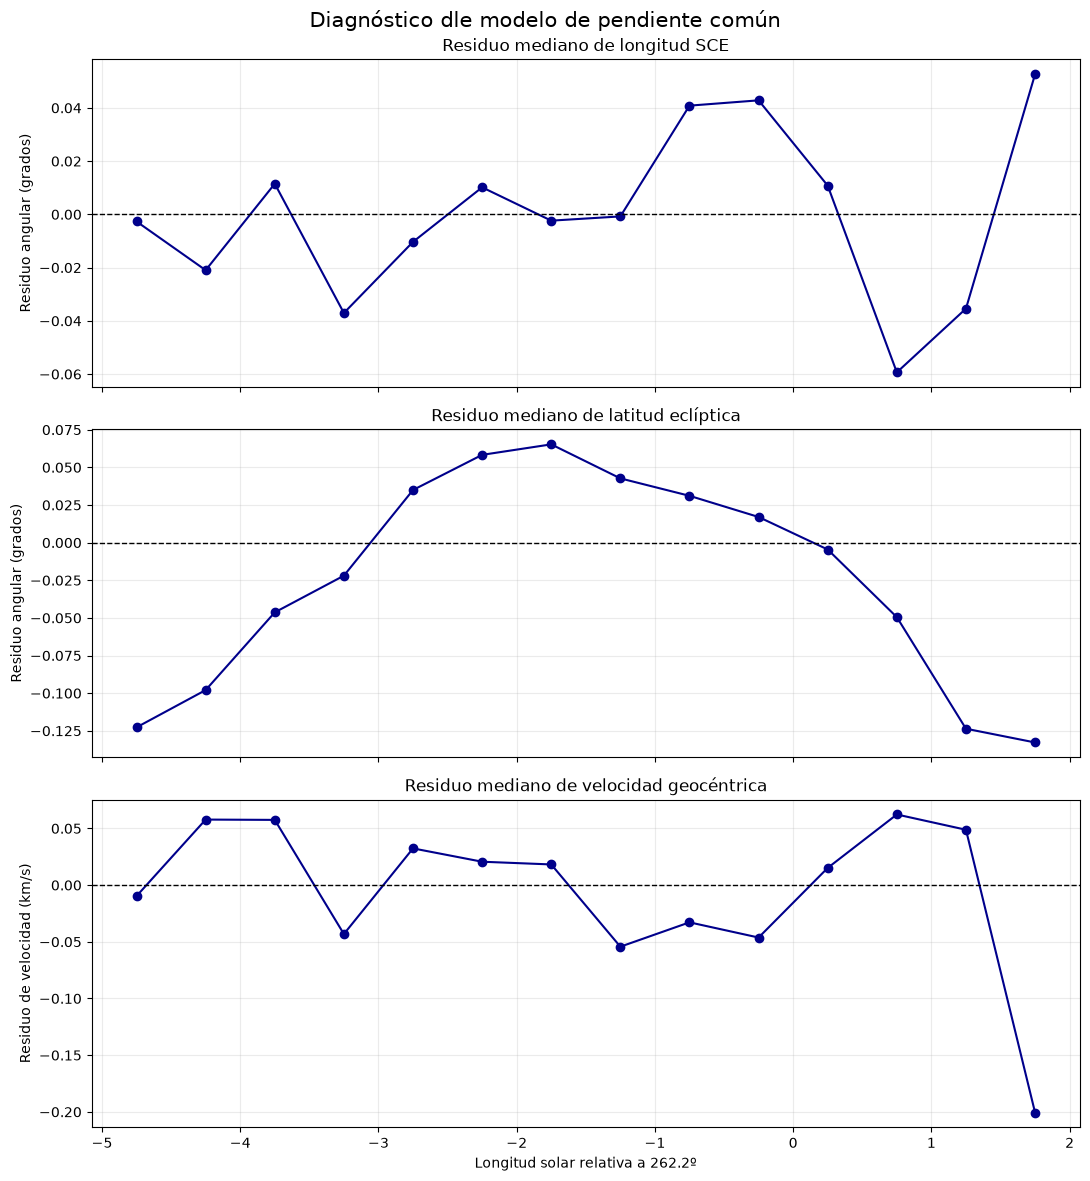

In [84]:
# Agrupar los residuos por longitud solar y comprobar si el modelo lineal deja patrones sistemáticos

bordes_delta_sol = np.arange(-5.0, 2.0 + 0.5, 0.5)

df_residuos_comun["intervalo_delta_sol"] = pd.cut(
    df_residuos_comun["delta_sol_lon_deg"],
    bins = bordes_delta_sol,
    right = False,
    include_lowest = True,
)

resumen_residuos_intervalo = df_residuos_comun.groupby("intervalo_delta_sol", observed = True).agg(
    trayectorias=(
            "Unique trajectory (identifier)",
            "size",
    ),
    delta_sol_mediana=(
        "delta_sol_lon_deg",
        "median",
    ),
    residuo_lambda_mediana=(
        "residuo_lambda_sce_comun",
        "median",
    ),
    residuo_beta_mediana=(
        "residuo_beta_comun",
        "median",
    ),
    residuo_vgeo_mediana=(
        "residuo_vgeo_comun",
        "median",
    ),
).reset_index()

resumen_residuos_intervalo["centro_intervalo"] = resumen_residuos_intervalo["intervalo_delta_sol"].map(lambda intervalo: intervalo.mid).astype(float)

display(resumen_residuos_intervalo.round(5))

fig, ejes = plt.subplots(
    nrows = 3,
    ncols = 1,
    figsize = (11, 12),
    sharex = True,
)

configuracion_graficas = [
    (
        "residuo_lambda_mediana",
        "Residuo mediano de longitud SCE",
        "Residuo angular (grados)",
    ),
    (
        "residuo_beta_mediana",
        "Residuo mediano de latitud eclíptica",
        "Residuo angular (grados)",
    ),
    (
        "residuo_vgeo_mediana",
        "Residuo mediano de velocidad geocéntrica",
        "Residuo de velocidad (km/s)",
    ),
]

for eje, (columna_residuo, titulo, etiqueta_y) in zip(ejes, configuracion_graficas):
    eje.plot(
        resumen_residuos_intervalo["centro_intervalo"], 
         resumen_residuos_intervalo[columna_residuo],
         marker = "o",
         color = "darkblue",
         linewidth = 1.5,
    )
    
    eje.axhline(0, color = "black", linestyle = "--", linewidth = 1)
    
    eje.set_title(titulo)
    eje.set_ylabel(etiqueta_y)
    eje.grid(alpha = 0.25)
    
ejes[-1].set_xlabel("Longitud solar relativa a 262.2º")

fig.suptitle("Diagnóstico dle modelo de pendiente común", fontsize = 15)

plt.tight_layout()
plt.show()

In [86]:
# Ajustar el modelo lineal común de latitud por separado en las muestras estándar y estricta

def calcular_residuos_beta_lineal_comun(df_entrada, nombre_muestra):
    df_modelo = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    anios = sorted(df_modelo["source_year"].unique())
    
    columnas_interceptos = np.column_stack([df_modelo["source_year"].eq(anio).astype(float).to_numpy() for anio in anios])
    
    x = df_modelo["delta_sol_lon_deg"].to_numpy(dtype = float)
    y = df_modelo["BETgeo (deg)"].to_numpy(dtype = float)
    
    matriz_diseno = np.column_stack([columnas_interceptos, x])
    
    coeficientes, _, _, _ = np.linalg.lstsq(matriz_diseno, y, rcond = None)
    
    valores_esperados = (matriz_diseno @ coeficientes)
    
    residuos = y - valores_esperados
    
    df_modelo["beta_esperada_lineal"] = valores_esperados
    df_modelo["residuo_beta_lineal"] = residuos
    
    pendiente_comun = coeficientes[-1]
    
    resumen_modelo = pd.DataFrame(
        {
            "muestra": [nombre_muestra],
            "trayectorias": [len(df_modelo)],
            "pendiente_comun": [
                pendiente_comun
            ],
            "residuo_medio": [
                residuos.mean()
            ],
            "residuo_mediano": [
                np.median(residuos)
            ],
            "rmse": [
                np.sqrt(
                    np.mean(residuos ** 2)
                )
            ],
        }
    )
    
    interceptos = pd.DataFrame(
        {
            "muestra": nombre_muestra,
            "anio": anios,
            "intercepto": coeficientes[:-1],
        }
    )
    
    return df_modelo, resumen_modelo, interceptos

df_beta_estandar_lineal, resumen_beta_estandar_lineal, interceptos_beta_estandar_lineal = calcular_residuos_beta_lineal_comun(df_gem_estandar, "Estandar")
df_beta_estricta_lineal, resumen_beta_estricta_lineal, interceptos_beta_estricta_lienal = calcular_residuos_beta_lineal_comun(df_gem_estricta, "Estricta")

resumen_beta_lineal_muestras = pd.concat([resumen_beta_estandar_lineal, resumen_beta_estricta_lineal], ignore_index = True)

display(resumen_beta_lineal_muestras.round(6))

,muestra,trayectorias,pendiente_comun,residuo_medio,residuo_mediano,rmse
0,Estandar,19079,-0.054772,-0.0,0.010177,0.378967
1,Estricta,7040,-0.056038,0.0,0.010945,0.346505


,muestra,intervalo_delta_sol,trayectorias,residuo_beta_mediano
0,Estándar,"[-5.0, -4.5)",170,-0.12269
1,Estándar,"[-4.5, -4.0)",227,-0.09793
2,Estándar,"[-4.0, -3.5)",214,-0.04631
3,Estándar,"[-3.5, -3.0)",406,-0.02194
4,Estándar,"[-3.0, -2.5)",370,0.03498
5,Estándar,"[-2.5, -2.0)",601,0.05832
6,Estándar,"[-2.0, -1.5)",976,0.06529
7,Estándar,"[-1.5, -1.0)",2009,0.04269
8,Estándar,"[-1.0, -0.5)",2963,0.03112
9,Estándar,"[-0.5, 0.0)",5366,0.01705


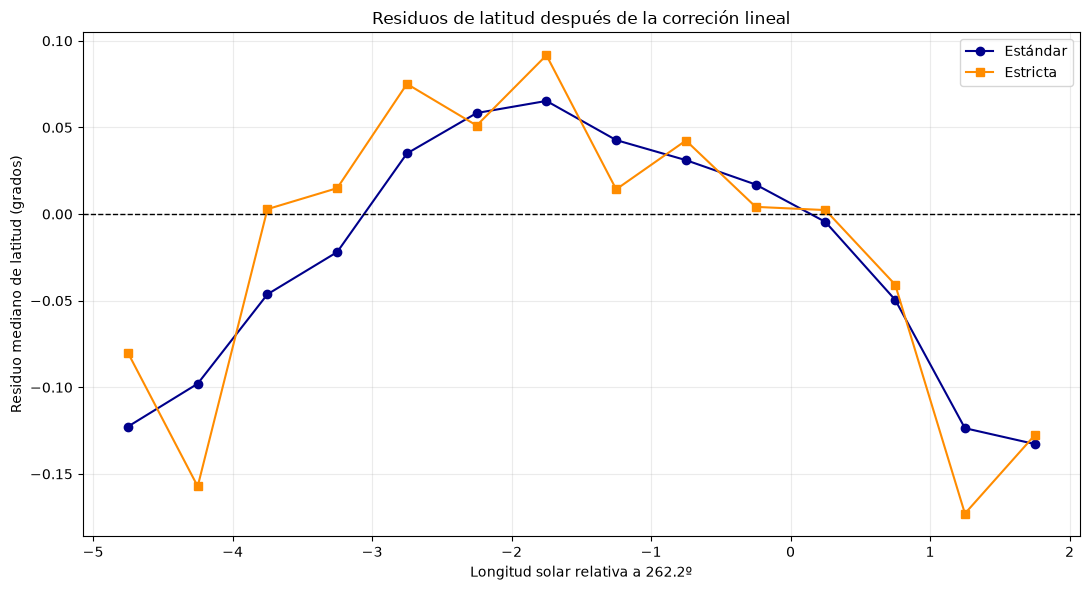

In [91]:
# Comparar los residuos de latitud por intervalo solar en las muestras estándar y estricta

def resumir_residuos_beta_por_intervalos(df_entrada, nombre_muestra, ancho_intervalo = 0.5):
    bordes = np.arange(-5.0, 2.0 + ancho_intervalo, ancho_intervalo)
    
    df_resumen = df_entrada.copy()
    
    df_resumen["intervalo_delta_sol"] = pd.cut(
        df_resumen["delta_sol_lon_deg"],
        bins = bordes,
        right = False,
        include_lowest = True
    )
    
    resumen = df_resumen.groupby("intervalo_delta_sol", observed = True).agg(
        trayectorias=(
                "Unique trajectory (identifier)",
                "size",
        ),
        delta_sol_mediana=(
            "delta_sol_lon_deg",
            "median",
        ),
        residuo_beta_mediano=(
            "residuo_beta_lineal",
            "median",
        ),
    ).reset_index()
    
    resumen["centro_intervalo"] = resumen["intervalo_delta_sol"].map(lambda intervalo: intervalo.mid).astype(float)
    
    resumen["muestra"] = nombre_muestra
    
    return resumen

residuos_beta_estandar_intervalos = resumir_residuos_beta_por_intervalos(df_beta_estandar_lineal, "Estándar")
residuos_beta_estricta_intervalos = resumir_residuos_beta_por_intervalos(df_beta_estricta_lineal, "Estricta")

comparacion_residuos_beta = pd.concat([residuos_beta_estandar_intervalos, residuos_beta_estricta_intervalos], ignore_index = True)

display(
    comparacion_residuos_beta[
        [
            "muestra",
            "intervalo_delta_sol",
            "trayectorias",
            "residuo_beta_mediano",
        ]
    ].round(5)
)

fig, eje = plt.subplots(figsize = (11, 6))

configuracion_muestras = {
    "Estándar": {
        "color": "darkblue",
        "marcador": "o",
    },
    "Estricta": {
        "color": "darkorange",
        "marcador": "s",
    },
}

for muestra, configuracion in configuracion_muestras.items():
    datos_muestra = comparacion_residuos_beta.loc[comparacion_residuos_beta["muestra"].eq(muestra)]
    
    eje.plot(
        datos_muestra["centro_intervalo"],
        datos_muestra["residuo_beta_mediano"],
        marker = configuracion["marcador"],
        color = configuracion["color"],
        linewidth = 1.5,
        label = muestra,
    )

eje.axhline(0, color = "black", linestyle = "--", linewidth = 1)

eje.set_title("Residuos de latitud después de la correción lineal")
eje.set_xlabel("Longitud solar relativa a 262.2º")
eje.set_ylabel("Residuo mediano de latitud (grados)")

eje.grid(alpha = 0.25)
eje.legend()

plt.tight_layout()
plt.show()

,source_year,intervalo_delta_sol_anual,trayectorias,delta_sol_mediana,residuo_beta_mediano,centro_intervalo,usar_en_grafica
0,2019,"[-5.0, -4.0)",11,-4.41888,-0.01473,-4.5,False
1,2019,"[-4.0, -3.0)",16,-3.69136,-0.24631,-3.5,False
2,2019,"[-3.0, -2.0)",21,-2.46758,0.09569,-2.5,True
3,2019,"[-2.0, -1.0)",43,-1.37362,0.06957,-1.5,True
4,2019,"[-1.0, 0.0)",130,-0.45858,0.09832,-0.5,True
5,2019,"[0.0, 1.0)",196,0.15564,0.01036,0.5,True
6,2019,"[1.0, 2.0)",13,1.10645,-0.05156,1.5,False
7,2020,"[-5.0, -4.0)",12,-4.73973,-0.16290,-4.5,False
8,2020,"[-4.0, -3.0)",40,-3.22955,0.16310,-3.5,True
9,2020,"[-3.0, -2.0)",19,-2.58163,-0.04084,-2.5,False


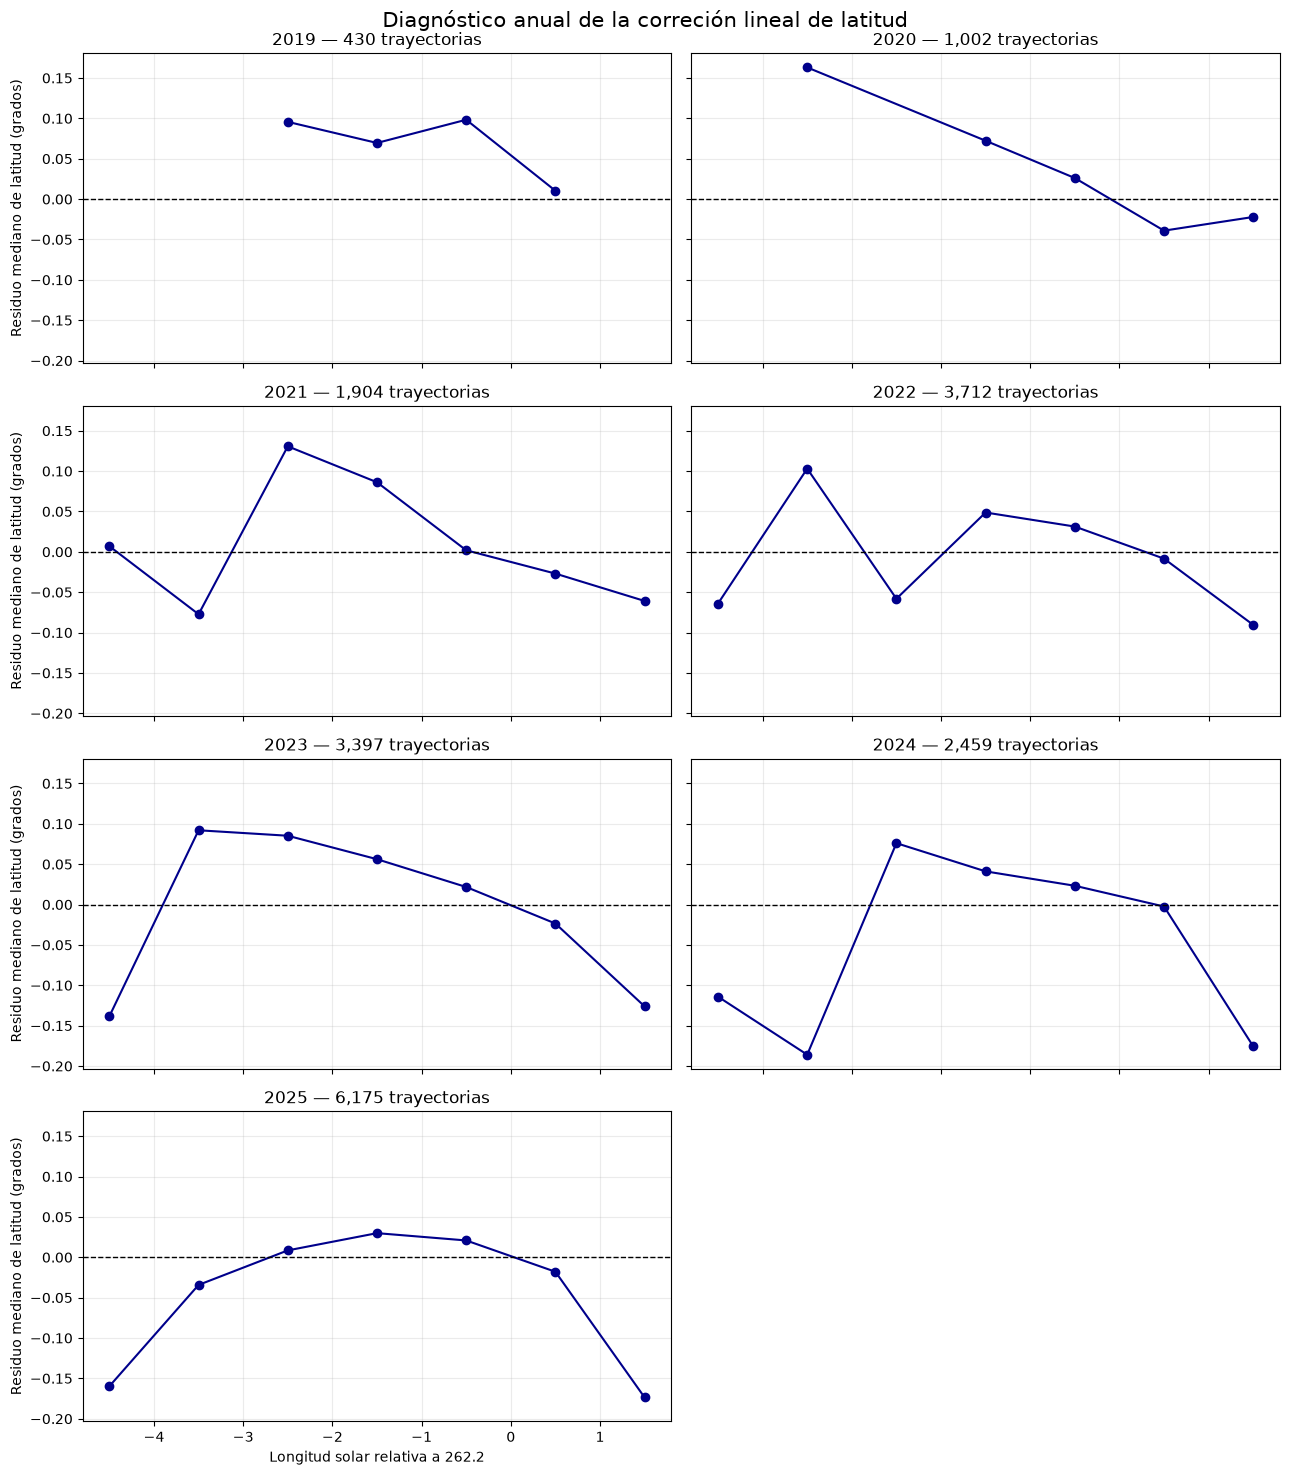

In [98]:
# Examinar año por año si la curvatura de latitud aparece dentro de la muestra estándar

bordes_anuales = np.arange(-5.0, 2.0 + 1.0, 1.0)

df_beta_anual = df_beta_estandar_lineal.copy()

df_beta_anual["intervalo_delta_sol_anual"] = pd.cut(
    df_beta_anual["delta_sol_lon_deg"],
    bins=bordes_anuales,
    right=False,
    include_lowest=True,
)

residuos_beta_por_anio = df_beta_anual.groupby(["source_year", "intervalo_delta_sol_anual"], observed = True).agg(
    trayectorias=(
        "Unique trajectory (identifier)",
        "size",
    ),
    delta_sol_mediana=(
        "delta_sol_lon_deg",
        "median",
    ),
    residuo_beta_mediano=(
        "residuo_beta_lineal",
        "median",
    ),
).reset_index()

residuos_beta_por_anio["centro_intervalo"] = residuos_beta_por_anio["intervalo_delta_sol_anual"].map(lambda intervalo: intervalo.mid).astype(float)
residuos_beta_por_anio["usar_en_grafica"] = residuos_beta_por_anio["trayectorias"].ge(20)

display(residuos_beta_por_anio.round(5))

fig, ejes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(13, 15),
    sharex=True,
    sharey=True,
)

ejes = ejes.ravel()

anios = sorted(df_beta_anual["source_year"].unique())

for eje, anio in zip(ejes, anios):
    datos_anio = residuos_beta_por_anio.loc[residuos_beta_por_anio["source_year"].eq(anio) & residuos_beta_por_anio["usar_en_grafica"]]
    
    eje.plot(datos_anio["centro_intervalo"], datos_anio["residuo_beta_mediano"], marker = "o", color = "darkblue", linewidth = 1.5)
    
    eje.axhline(0, color = "black", linestyle = "--", linewidth = 1)
    
    cantidad_anual = df_beta_anual["source_year"].eq(anio).sum()
    
    eje.set_title(f"{anio} — {cantidad_anual:,} trayectorias")
    
    eje.grid(alpha = 0.25)
    
for eje in ejes[len(anios):]:
    eje.set_visible(False)
    
for eje in ejes[::2]:
    eje.set_ylabel("Residuo mediano de latitud (grados)")
    
for eje in ejes[-2:]:
    eje.set_xlabel("Longitud solar relativa a 262.2")
    
fig.suptitle("Diagnóstico anual de la correción lineal de latitud", fontsize = 15)

plt.tight_layout()
plt.show()

In [100]:
# Ajustar y comparar modelos lienales y cuadráticos de deriva para la latitud eclíptica

def ajustar_modelo_beta_comun(df_entrada, nombre_muestra, incluir_cuadratico = False):
    df_modelo = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    anios = sorted(df_modelo["source_year"].unique())
    
    columnas_interceptos = np.column_stack([df_modelo["source_year"].eq(anio).astype(float).to_numpy() for anio in anios])
    
    x = df_modelo["delta_sol_lon_deg"].to_numpy(dtype = float)
    y = df_modelo["BETgeo (deg)"].to_numpy(dtype = float)
    
    columnas_modelo = [columnas_interceptos, x]
    
    if incluir_cuadratico: 
        columnas_modelo.append(x ** 2)
        
    matriz_diseno = np.column_stack(columnas_modelo)
    
    coeficientes, _, _, _ = np.linalg.lstsq(matriz_diseno, y, rcond = None)
    
    valores_esperados = matriz_diseno @ coeficientes
    
    residuos = y - valores_esperados
    
    numero_observaciones = len(y)
    numero_parametros = matriz_diseno.shape[1]
    
    suma_cuadrados_residuos = np.sum(residuos ** 2)
    
    varianza_residual = suma_cuadrados_residuos / (numero_observaciones - numero_parametros)
    
    matriz_covarianza = varianza_residual * np.linalg.pinv(matriz_diseno.T @ matriz_diseno)
    
    errores_estandar = np.sqrt(np.diag(matriz_covarianza))
    
    suma_cuadrados_total = np.sum((y - y.mean()) ** 2)
    
    r_cuadrada = 1 - suma_cuadrados_residuos / suma_cuadrados_total
    
    df_modelo["beta_esperada_modelo"] = valores_esperados
    
    df_modelo["residuo_beta_modelo"] = residuos
    
    indice_lineal = len(anios)
    
    pendiente_lineal = coeficientes[indice_lineal]
    
    error_lineal = errores_estandar[indice_lineal]
    
    if incluir_cuadratico:
        coeficiente_cuadratico = coeficientes[indice_lineal + 1]
        
        error_cuadratico = errores_estandar[indice_lineal + 1]
    else:
        coeficiente_cuadratico = np.nan
        error_cuadratico = np.nan
        
    nombre_modelo = "Cuadrático" if incluir_cuadratico else "Lineal"
    
    resumen = pd.DataFrame(
        {
            "muestra": [nombre_muestra],
            "modelo": [nombre_modelo],
            "trayectorias": [
                numero_observaciones
            ],
            "numero_parametros": [
                numero_parametros
            ],
            "coeficiente_lineal": [
                pendiente_lineal
            ],
            "error_estandar_lineal": [
                error_lineal
            ],
            "coeficiente_cuadratico": [
                coeficiente_cuadratico
            ],
            "error_estandar_cuadratico": [
                error_cuadratico
            ],
            "r_cuadrada": [
                r_cuadrada
            ],
            "rmse": [
                np.sqrt(
                    np.mean(residuos ** 2)
                )
            ],
        }
    )
    
    interceptos = pd.DataFrame(
        {
            "muestra": nombre_muestra,
            "modelo": nombre_modelo,
            "anio": anios,
            "intercepto": (
                coeficientes[:len(anios)]
            ),
            "error_estandar_intercepto": (
                errores_estandar[:len(anios)]
            ),
        }
    )
    
    return df_modelo, resumen, interceptos

resultados_modelos_beta = {}

for nombre_muestra, df_muestra in {"Estándar": df_gem_estandar, "Estricta": df_gem_estricta}.items():
    for incluir_cuadratico in [False, True]:
        nombre_modelo = "Cuadrático" if incluir_cuadratico else "Lineal"
        
        df_resultado, resumen_resultado, interceptos_resultado = ajustar_modelo_beta_comun(df_muestra, nombre_muestra, incluir_cuadratico)
        
        resultados_modelos_beta[(nombre_muestra, nombre_modelo)] = {
            "datos": df_resultado,
            "resumen": resumen_resultado,
            "interceptos": (interceptos_resultado),
        }
        
resumen_modelos_beta = pd.concat([resultado["resumen"] for resultado in resultados_modelos_beta.values()], ignore_index = True)

display(resumen_modelos_beta.round(7))

,muestra,modelo,trayectorias,numero_parametros,coeficiente_lineal,error_estandar_lineal,coeficiente_cuadratico,error_estandar_cuadratico,r_cuadrada,rmse
0,Estándar,Lineal,19079,8,-0.054772,0.002489,NaN,NaN,0.027220,0.378966
1,Estándar,Cuadrático,19079,9,-0.108621,0.004750,-0.019099,0.001437,0.036144,0.377224
2,Estricta,Lineal,7040,8,-0.056038,0.003774,NaN,NaN,0.037204,0.346505
3,Estricta,Cuadrático,7040,9,-0.108832,0.007241,-0.017757,0.002082,0.047060,0.344727


In [101]:
# Calcular cuánto mejora el RMSE al añadir el término cuadrático en cada muestra

registros_comparacion_beta = []

for muestra in ["Estándar", "Estricta"]:
    fila_lineal = resumen_modelos_beta.loc[resumen_modelos_beta["muestra"].eq(muestra) & resumen_modelos_beta["modelo"].eq("Lineal")].iloc[0]
    fila_cuadratica = resumen_modelos_beta.loc[resumen_modelos_beta["muestra"].eq(muestra) & resumen_modelos_beta["modelo"].eq("Cuadrático")].iloc[0]
    
    rmse_lineal = fila_lineal["rmse"]
    rmse_cuadratico = fila_cuadratica["rmse"]
    
    reduccion_rmse = 100 * (rmse_lineal - rmse_cuadratico) / rmse_lineal
    
    coeficiente_cuadratico = fila_cuadratica["coeficiente_cuadratico"]
    
    error_cuadratico = fila_cuadratica["error_estandar_cuadratico"]
    
    razon_coeficiente_error = coeficiente_cuadratico / error_cuadratico
    
    registros_comparacion_beta.append(
        {
            "muestra": muestra,
            "rmse_lineal": rmse_lineal,
            "rmse_cuadratico": (
                rmse_cuadratico
            ),
            "reduccion_rmse_porcentaje": (
                reduccion_rmse
            ),
            "coeficiente_cuadratico": (
                coeficiente_cuadratico
            ),
            "error_estandar_cuadratico": (
                error_cuadratico
            ),
            "razon_coeficiente_error": (
                razon_coeficiente_error
            ),
        }
    )
    
comparacion_modelos_beta = pd.DataFrame(registros_comparacion_beta)

display(comparacion_modelos_beta)

,muestra,rmse_lineal,rmse_cuadratico,reduccion_rmse_porcentaje,coeficiente_cuadratico,error_estandar_cuadratico,razon_coeficiente_error
0,Estándar,0.378967,0.377224,0.459771,-0.019099,0.001437,-13.288102
1,Estricta,0.346505,0.344727,0.513162,-0.017757,0.002082,-8.527605


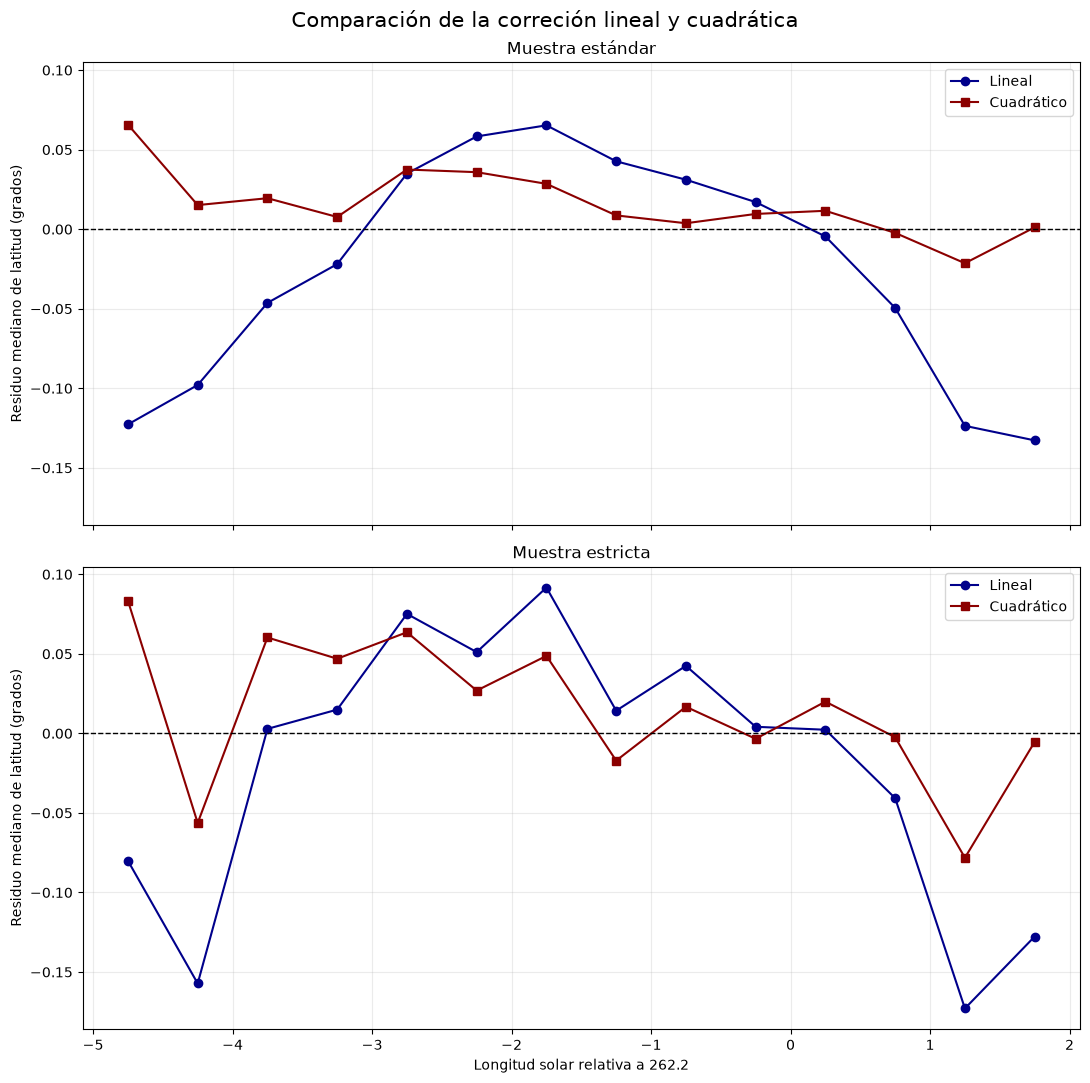

In [106]:
# Comparar las medianas residuales de los modelos lineal y cuadrático

def resumir_residuos_modelo_beta(df_modelo, nombre_muestra, nombre_modelo):
    bordes = np.arange(-5.0, 2.0 + 0.5, 0.5)
    
    df_resumen = df_modelo.copy()
    
    df_resumen["intervalo_delta_sol"] = pd.cut(
        df_resumen["delta_sol_lon_deg"],
        bins=bordes,
        right=False,
        include_lowest=True,
    )
    
    resumen = df_resumen.groupby("intervalo_delta_sol", observed = True).agg(
        trayectorias=(
            "Unique trajectory (identifier)",
            "size",
        ),
        residuo_beta_mediano=(
            "residuo_beta_modelo",
            "median",
        ),
    ).reset_index()
    
    resumen["centro_intervalo"] = resumen["intervalo_delta_sol"].map(lambda intervalo: intervalo.mid).astype(float)
    
    resumen["muestra"] = nombre_muestra
    resumen["modelo"] = nombre_modelo
    
    return resumen

resumenes_residuos_beta = []

for (nombre_muestra, nombre_modelo), resultado in resultados_modelos_beta.items():
    resumen_residuos = resumir_residuos_modelo_beta(resultado["datos"], nombre_muestra, nombre_modelo)
    
    resumenes_residuos_beta.append(resumen_residuos)
    
comparacion_residuos_modelos_beta = pd.concat(resumenes_residuos_beta, ignore_index = True)

fig, ejes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(11, 11),
    sharex=True,
    sharey=True,
)

for eje, muestra in zip(ejes, ["Estándar", "Estricta"]):
    for modelo, color, marcador in [("Lineal", "darkblue", "o"), ("Cuadrático", "darkred", "s")]:
        datos = comparacion_residuos_modelos_beta.loc[comparacion_residuos_modelos_beta["muestra"].eq(muestra) & comparacion_residuos_modelos_beta["modelo"].eq(modelo)]
        
        eje.plot(
            datos["centro_intervalo"],
            datos["residuo_beta_mediano"],
            marker=marcador,
            color=color,
            linewidth=1.5,
            label=modelo,
        )
    
    eje.axhline(0, color = "black", linestyle = "--", linewidth = 1)
    
    eje.set_title(f"Muestra {muestra.lower()}")
    eje.set_ylabel("Residuo mediano de latitud (grados)")
    
    eje.grid(alpha = 0.25)
    eje.legend()
    
ejes[-1].set_xlabel("Longitud solar relativa a 262.2")

fig.suptitle("Comparación de la correción lineal y cuadrática", fontsize = 15)

plt.tight_layout()
plt.show()

In [108]:
# Resumir la distribución de magnitud por longitud solar en las muestras estándar y estricta

def resumir_magnitud_por_intervalo(df_entrada, nombre_muestra, ancho_intervalo = 0.5):
    df_magnitud = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    bordes = np.arange(-5.0, 2.0 + ancho_intervalo, ancho_intervalo)
    
    df_magnitud["intervalo_delta_sol"] = pd.cut(
        df_magnitud["delta_sol_lon_deg"],
        bins=bordes,
        right=False,
        include_lowest=True,
    )
    
    resumen = df_magnitud.groupby("intervalo_delta_sol", observed = True).agg(
        trayectorias=(
            "Unique trajectory (identifier)",
            "size",
        ),
        delta_sol_mediana=(
            "delta_sol_lon_deg",
            "median",
        ),
        magnitud_percentil_25=(
            "Peak (AbsMag)",
            lambda serie: serie.quantile(0.25),
        ),
        magnitud_mediana=(
            "Peak (AbsMag)",
            "median",
        ),
        magnitud_percentil_75=(
            "Peak (AbsMag)",
            lambda serie: serie.quantile(0.75),
        ),
    ).reset_index()
    
    resumen["centro_intervalo"] = resumen["intervalo_delta_sol"].map(lambda intervalo: intervalo.mid).astype(float)
    
    resumen["muestra"] = nombre_muestra
    
    return resumen

magnitud_estandar_intervalos = resumir_magnitud_por_intervalo(df_gem_estandar, "Estándar")
magnitud_estricta_intervalos = resumir_magnitud_por_intervalo(df_gem_estricta, "Estricta")

comparacion_magnitud_intervalos = pd.concat([magnitud_estandar_intervalos, magnitud_estricta_intervalos], ignore_index = True)

display(
    comparacion_magnitud_intervalos[
        [
            "muestra",
            "intervalo_delta_sol",
            "trayectorias",
            "magnitud_percentil_25",
            "magnitud_mediana",
            "magnitud_percentil_75",
        ]
    ].round(4)
)

,muestra,intervalo_delta_sol,trayectorias,magnitud_percentil_25,magnitud_mediana,magnitud_percentil_75
0,Estándar,"[-5.0, -4.5)",170,-0.9625,-0.340,0.3475
1,Estándar,"[-4.5, -4.0)",227,-0.9200,-0.420,0.1750
2,Estándar,"[-4.0, -3.5)",214,-1.0700,-0.340,0.2500
3,Estándar,"[-3.5, -3.0)",406,-1.0075,-0.310,0.4675
4,Estándar,"[-3.0, -2.5)",370,-0.9800,-0.215,0.4575
5,Estándar,"[-2.5, -2.0)",601,-0.8500,-0.210,0.5400
6,Estándar,"[-2.0, -1.5)",976,-0.8225,-0.180,0.4700
7,Estándar,"[-1.5, -1.0)",2009,-0.8000,-0.180,0.4400
8,Estándar,"[-1.0, -0.5)",2963,-0.9100,-0.300,0.3000
9,Estándar,"[-0.5, 0.0)",5366,-1.1300,-0.550,0.0700


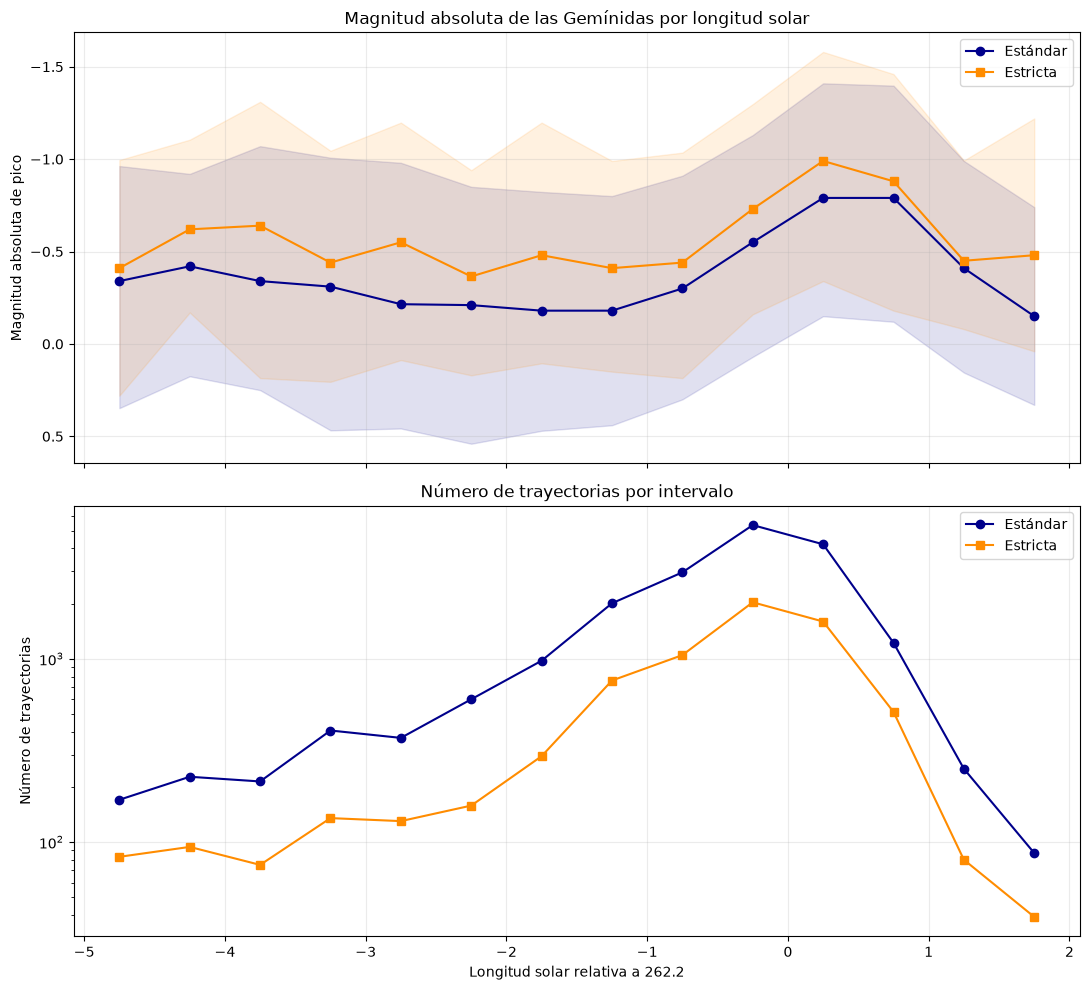

In [111]:
# Visualizar la evolución de la magnitud y la cobertura observacional a lo largo de la lluvia

fig, ejes = plt.subplots(
    nrows = 2,
    ncols = 1,
    figsize = (11, 10),
    sharex = True,
)

configuracion_muestras = {
    "Estándar": {
        "color": "darkblue",
        "marcador": "o",
    },
    "Estricta": {
        "color": "darkorange",
        "marcador": "s",
    },
}

for muestra, configuracion in configuracion_muestras.items():
    datos = comparacion_magnitud_intervalos.loc[comparacion_magnitud_intervalos["muestra"].eq(muestra)]
    
    x = datos["centro_intervalo"].to_numpy(dtype = float)
    
    mediana = datos["magnitud_mediana"].to_numpy(dtype = float)
    percentil_25 = datos["magnitud_percentil_25"].to_numpy(dtype = float)
    percentil_75 = datos["magnitud_percentil_75"].to_numpy(dtype = float)
    
    ejes[0].plot(
        x,
        mediana,
        marker=configuracion["marcador"],
        color=configuracion["color"],
        linewidth=1.5,
        label=muestra,
    )
    
    ejes[0].fill_between(
        x,
        percentil_25,
        percentil_75,
        color=configuracion["color"],
        alpha=0.12,
    )

    ejes[1].plot(
        x,
        datos["trayectorias"],
        marker=configuracion["marcador"],
        color=configuracion["color"],
        linewidth=1.5,
        label=muestra,
    )
    
ejes[0].invert_yaxis()

ejes[0].set_title("Magnitud absoluta de las Gemínidas por longitud solar")
ejes[0].set_ylabel("Magnitud absoluta de pico")

ejes[0].grid(alpha = 0.25)
ejes[0].legend()

ejes[1].set_title("Número de trayectorias por intervalo")
ejes[1].set_xlabel("Longitud solar relativa a 262.2")
ejes[1].set_ylabel("Número de trayectorias")

ejes[1].set_yscale("log")
ejes[1].grid(alpha=0.25)
ejes[1].legend()

plt.tight_layout()
plt.show()

,source_year,intervalo_delta_sol_anual,trayectorias,delta_sol_mediana,magnitud_mediana,magnitud_percentil_25,magnitud_percentil_75,centro_intervalo,usar_en_grafica
0,2019,"[-5.0, -4.0)",11,-4.4189,-0.270,-0.5400,-0.1850,-4.5,False
1,2019,"[-4.0, -3.0)",16,-3.6914,-0.350,-0.7525,0.4950,-3.5,False
2,2019,"[-3.0, -2.0)",21,-2.4676,-0.210,-0.7200,0.2900,-2.5,True
3,2019,"[-2.0, -1.0)",43,-1.3736,-0.070,-0.5950,0.3600,-1.5,True
4,2019,"[-1.0, 0.0)",130,-0.4586,-0.335,-0.9200,0.1925,-0.5,True
5,2019,"[0.0, 1.0)",196,0.1556,-0.715,-1.2525,-0.1150,0.5,True
6,2019,"[1.0, 2.0)",13,1.1064,-0.020,-0.5200,0.1900,1.5,False
7,2020,"[-5.0, -4.0)",12,-4.7397,0.405,-0.7825,0.7900,-4.5,False
8,2020,"[-4.0, -3.0)",40,-3.2295,-0.490,-1.5050,0.2700,-3.5,True
9,2020,"[-3.0, -2.0)",19,-2.5816,-0.950,-1.2650,-0.1450,-2.5,False


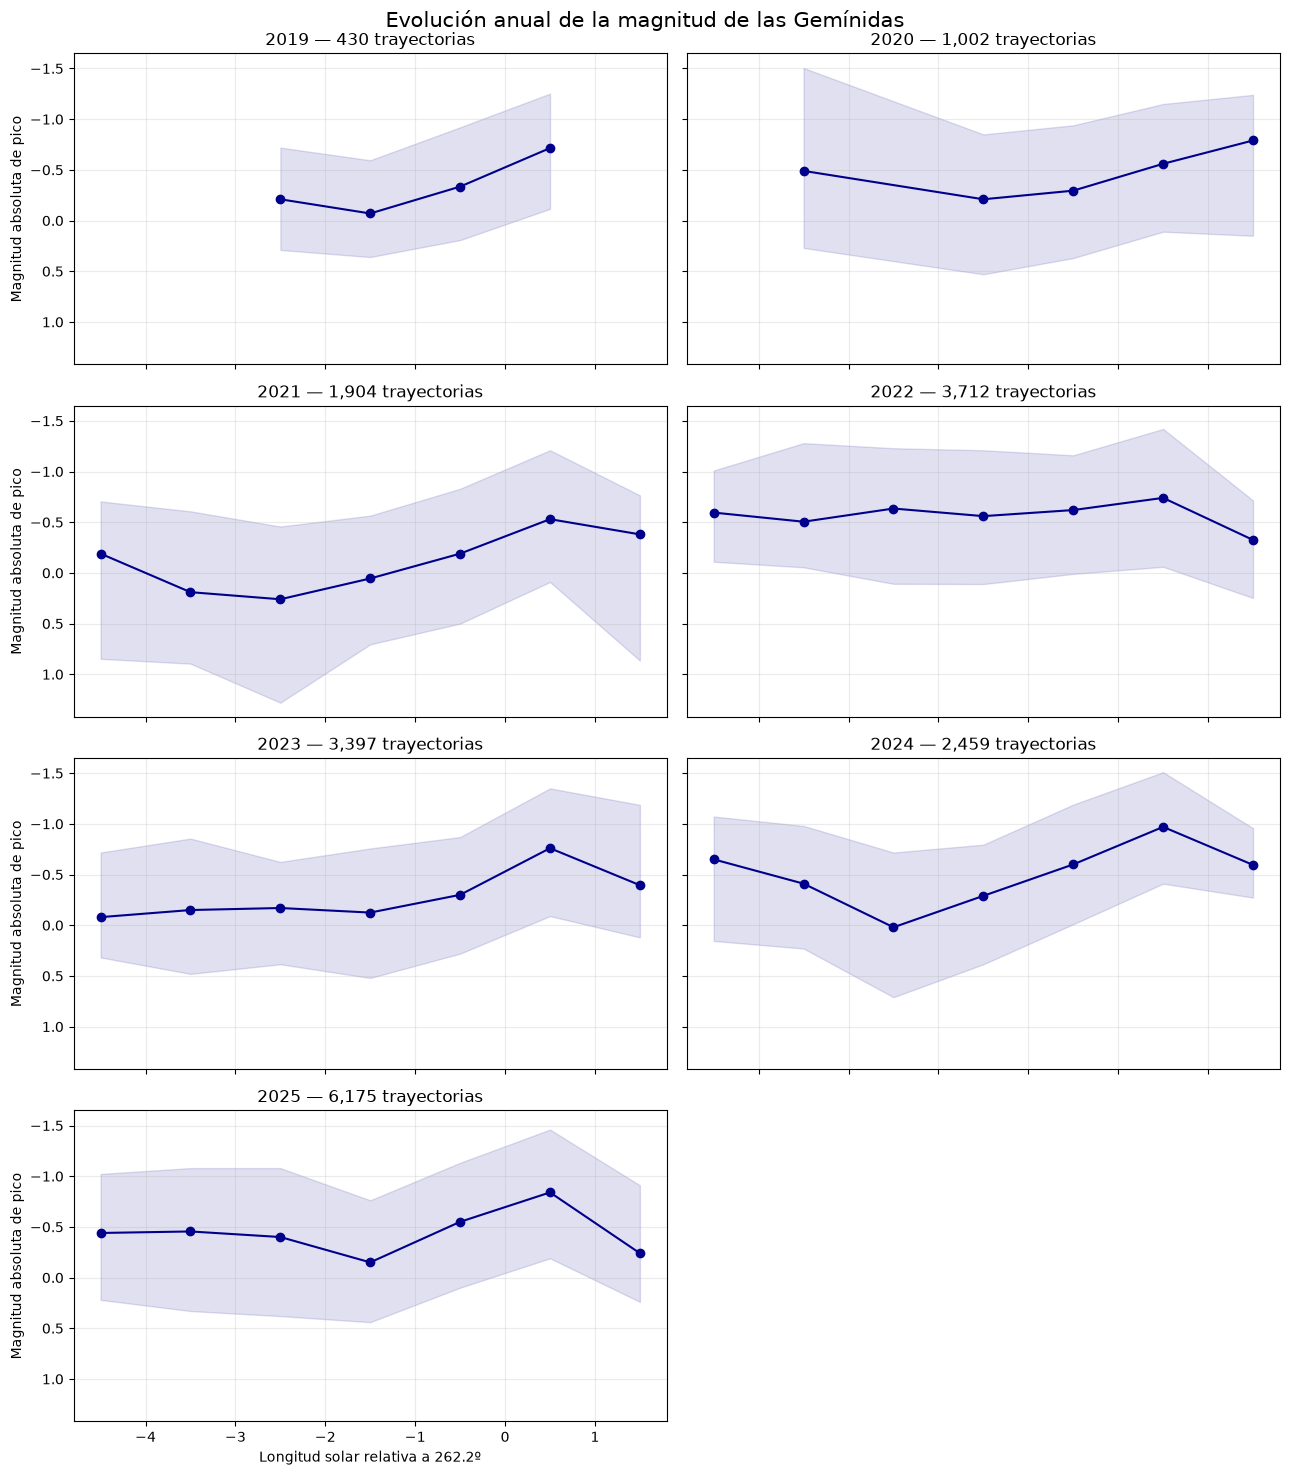

In [115]:
# Examinar año por año la evolución de la magnitud dentro de la muestra estándar

df_magnitud_anual = df_gem_estandar.loc[df_gem_estandar["en_ventana_deriva"]].copy()

bordes_magnitud_anual = np.arange(-5.0, 2.0 + 1.0, 1.0)

df_magnitud_anual["intervalo_delta_sol_anual"] = pd.cut(
    df_magnitud_anual["delta_sol_lon_deg"],
    bins=bordes_magnitud_anual,
    right=False,
    include_lowest=True,
)

magnitud_por_anio = df_magnitud_anual.groupby(["source_year", "intervalo_delta_sol_anual"], observed = True).agg(
    trayectorias=(
        "Unique trajectory (identifier)",
        "size",
    ),
    delta_sol_mediana=(
        "delta_sol_lon_deg",
        "median",
    ),
    magnitud_mediana=(
        "Peak (AbsMag)",
        "median",
    ),
    magnitud_percentil_25=(
        "Peak (AbsMag)",
        lambda serie: serie.quantile(0.25),
    ),
    magnitud_percentil_75=(
        "Peak (AbsMag)",
        lambda serie: serie.quantile(0.75),
    ),
).reset_index()

magnitud_por_anio["centro_intervalo"] = magnitud_por_anio["intervalo_delta_sol_anual"].map(lambda intervalo: intervalo.mid).astype(float)

magnitud_por_anio["usar_en_grafica"] = magnitud_por_anio["trayectorias"].ge(20)

display(magnitud_por_anio.round(4))

fig, ejes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(13, 15),
    sharex=True,
    sharey=True,
)

ejes = ejes.ravel()

anios = sorted(df_magnitud_anual["source_year"].unique())

for eje, anio in zip(ejes, anios):
    datos_anio = magnitud_por_anio.loc[magnitud_por_anio["source_year"].eq(anio) & magnitud_por_anio["usar_en_grafica"]]
    
    x = datos_anio["centro_intervalo"].to_numpy(dtype = float)
    
    mediana = datos_anio["magnitud_mediana"].to_numpy(dtype = float)
    percentil_25 = datos_anio["magnitud_percentil_25"].to_numpy(dtype = float)
    percentil_75 = datos_anio["magnitud_percentil_75"].to_numpy(dtype = float)
    
    eje.plot(
        x,
        mediana,
        marker="o",
        color="darkblue",
        linewidth=1.5,
    )
    
    eje.fill_between(
        x,
        percentil_25,
        percentil_75,
        color="darkblue",
        alpha=0.12,
    )
    
    eje.set_title(f"{anio} — {len(df_magnitud_anual.loc[df_magnitud_anual["source_year"].eq(anio)]):,} trayectorias")
    
    eje.grid(alpha = 0.25)
    
for eje in ejes[len(anios):]:
    eje.set_visible(False)
    
ejes[0].invert_yaxis()

for eje in ejes[::2]:
    eje.set_ylabel("Magnitud absoluta de pico")
    
for eje in ejes[-2:]:
    eje.set_xlabel("Longitud solar relativa a 262.2º")
    
fig.suptitle("Evolución anual de la magnitud de las Gemínidas", fontsize = 15)

plt.tight_layout()
plt.show()

In [118]:
# Reunir en tablas únicas los coeficientes e interceptos del modelo final de deriva

fila_lambda_final = ajustes_pendiente_comun.loc[ajustes_pendiente_comun["variable"].eq("lambda_sce")].iloc[0]
fila_vgeo_final = ajustes_pendiente_comun.loc[ajustes_pendiente_comun["variable"].eq("vgeo")].iloc[0]
fila_beta_final = resumen_modelos_beta.loc[resumen_modelos_beta["muestra"].eq("Estándar") & resumen_modelos_beta["modelo"].eq("Cuadrático")].iloc[0]

parametros_deriva_finales = pd.DataFrame(
    [
        {
            "variable": "lambda_sce",
            "modelo": "Lineal",
            "coeficiente_lineal": (fila_lambda_final["pendiente_comun"]),
            "coeficiente_cuadratico": 0.0,
        },
        {
            "variable": "beta_geo",
            "modelo": "Cuadrático",
            "coeficiente_lineal": (fila_beta_final["coeficiente_lineal"]),
            "coeficiente_cuadratico": (fila_beta_final["coeficiente_cuadratico"]),
        },
        {
            "variable": "vgeo",
            "modelo": "Lineal",
            "coeficiente_lineal": (fila_vgeo_final["pendiente_comun"]),
            "coeficiente_cuadratico": 0.0,
        },
    ]
)

interceptos_lambda_finales = interceptos_modelo_comun.loc[interceptos_modelo_comun["variable"].eq("lambda_sce"), ["anio", "intercepto"]].copy()
interceptos_lambda_finales["variable"] = "lambda_sce"

interceptos_vgeo_finales = interceptos_modelo_comun.loc[interceptos_modelo_comun["variable"].eq("vgeo"), ["anio", "intercepto"]].copy()
interceptos_vgeo_finales["variable"] = "vgeo"

interceptos_beta_finales = resultados_modelos_beta[("Estándar", "Cuadrático")]["interceptos"][["anio", "intercepto"]].copy()
interceptos_beta_finales["variable"] = "beta_geo"

interceptos_deriva_finales = pd.concat([interceptos_lambda_finales, interceptos_beta_finales, interceptos_vgeo_finales], ignore_index = True)
interceptos_deriva_finales["anio"] = interceptos_deriva_finales["anio"].astype(int)
interceptos_deriva_finales = interceptos_deriva_finales[["variable", "anio", "intercepto"]].sort_values(["variable", "anio"]).reset_index(drop = True)

conteo_interceptos = interceptos_deriva_finales.groupby("variable").size()

if not conteo_interceptos.eq(7).all():
    raise ValueError("No se encontraron siete interceptos anuales para cada variable")

if not np.isfinite(parametros_deriva_finales[["coeficiente_lineal", "coeficiente_cuadratico"]].to_numpy()).all():
    raise ValueError("Los coeficientes finales contienen valores no finitos.")

print("Parámetros comunes del modelo final: ")
display(parametros_deriva_finales.round(7))

print("\nInterceptos anuales del modelo final: ")
display(interceptos_deriva_finales.round(7))


Parámetros comunes del modelo final: 


,variable,modelo,coeficiente_lineal,coeficiente_cuadratico
0,lambda_sce,Lineal,-0.102246,0.000000
1,beta_geo,Cuadrático,-0.108621,-0.019099
2,vgeo,Lineal,0.104933,0.000000



Interceptos anuales del modelo final: 


,variable,anio,intercepto
0,beta_geo,2019,10.438999
1,beta_geo,2020,10.489941
2,beta_geo,2021,10.495518
3,beta_geo,2022,10.492777
4,beta_geo,2023,10.498125
5,beta_geo,2024,10.508347
6,beta_geo,2025,10.508397
7,lambda_sce,2019,207.935478
8,lambda_sce,2020,208.002945
9,lambda_sce,2021,207.978167


In [129]:
# Calcular el radiante y la velocidad esperados usando una referencia idéntica para todas las muestras

def agregar_centro_esperado_final(df_entrada, nombre_muestra):
    df_centro = df_entrada.loc[df_entrada["en_ventana_deriva"]].copy()
    
    mapas_interceptos = {}
    
    for variable in ["lambda_sce", "beta_geo", "vgeo"]:
        tabla_variable = interceptos_deriva_finales.loc[interceptos_deriva_finales["variable"].eq(variable), ["anio", "intercepto"]]
        
        mapas_interceptos[variable] = dict(zip(tabla_variable["anio"], tabla_variable["intercepto"]))
        
    df_centro["intercepto_lambda_anual"] = df_centro["source_year"].map(mapas_interceptos["lambda_sce"])
    df_centro["intercepto_beta_anual"] = df_centro["source_year"].map(mapas_interceptos["beta_geo"])
    df_centro["intercepto_vgeo_anual"] = df_centro["source_year"].map(mapas_interceptos["vgeo"])
    
    columnas_interceptos = [
        "intercepto_lambda_anual",
        "intercepto_beta_anual",
        "intercepto_vgeo_anual",
    ]
    
    if df_centro[columnas_interceptos].isna().any().any():
        raise ValueError(f"Faltan interceptos anuales en la muestra {nombre_muestra}.")
    
    x = df_centro["delta_sol_lon_deg"].to_numpy(dtype = float)
    
    coeficientes = parametros_deriva_finales.set_index("variable")
    
    lambda_lineal = coeficientes.loc["lambda_sce", "coeficiente_lineal"]
    beta_lineal = coeficientes.loc["beta_geo", "coeficiente_lineal"]
    beta_cuadratico = coeficientes.loc["beta_geo", "coeficiente_cuadratico"]
    vgeo_lineal = coeficientes.loc["vgeo", "coeficiente_lineal"]
    
    df_centro["lambda_sce_esperada_deg"] = (df_centro["intercepto_lambda_anual"] + lambda_lineal * x) % 360
    df_centro["beta_esperada_deg"] = (df_centro["intercepto_beta_anual"]) + (beta_lineal * x) + (beta_cuadratico * x ** 2)
    df_centro["vgeo_esperada_km_s"] = df_centro["intercepto_vgeo_anual"] + vgeo_lineal * x
    
    df_centro["residuo_lambda_coordenada_deg"] = ((df_centro["lambda_sce_deg"] - df_centro["lambda_sce_esperada_deg"] + 180) % 360) - 180
    df_centro["residuo_beta_coordenada_deg"] = df_centro["BETgeo (deg)"] - df_centro["beta_esperada_deg"]
    df_centro["residuo_vgeo_km_s"] = df_centro["Vgeo (km/s)"] - df_centro["vgeo_esperada_km_s"]
    
    df_centro["muestra_calidad"] = nombre_muestra
    
    columnas_calculadas = [
        "lambda_sce_esperada_deg",
        "beta_esperada_deg",
        "vgeo_esperada_km_s",
        "residuo_lambda_coordenada_deg",
        "residuo_beta_coordenada_deg",
        "residuo_vgeo_km_s",
    ]
    
    if df_centro[columnas_calculadas].isna().any().any():
        raise ValueError(f"Se produjeron valores faltantes en la muestra {nombre_muestra}.")
    
    if not np.isfinite(df_centro[columnas_calculadas].to_numpy()).all():
        raise ValueError(f"Se produjeron valores no finitos en la muestra {nombre_muestra}.")
    
    if not df_centro["beta_esperada_deg"].between(-90, 90, inclusive = "both").all():
        raise ValueError("La latitud esperada contiene valores físicamente inválidos.")
    
    return df_centro

In [131]:
# Aplicar el modelo final a las muestras estándar y estricta y comprobar que usan exactamente la misma referencia

df_gem_estandar_centro = agregar_centro_esperado_final(df_gem_estandar, "Estándar")
df_gem_estricta_centro = agregar_centro_esperado_final(df_gem_estricta, "Estricta")

resumen_centros_esperados = pd.DataFrame(
    [
        {
            "muestra": "Estándar",
            "trayectorias": (len(df_gem_estandar_centro)),
            "lambda_esperada_minima": (df_gem_estandar_centro["lambda_sce_esperada_deg"].min()),
            "lambda_esperada_mediana": (df_gem_estandar_centro["lambda_sce_esperada_deg"].median()),
            "lambda_esperada_maxima": (df_gem_estandar_centro["lambda_sce_esperada_deg"].max()),
            "beta_esperada_minima": (df_gem_estandar_centro["beta_esperada_deg"].min()),
            "beta_esperada_mediana": (df_gem_estandar_centro["beta_esperada_deg"].median()),
            "beta_esperada_maxima": (df_gem_estandar_centro["beta_esperada_deg"].max()),
            "vgeo_esperada_minima": (df_gem_estandar_centro["vgeo_esperada_km_s"].min()),
            "vgeo_esperada_mediana": (df_gem_estandar_centro["vgeo_esperada_km_s"].median()),
            "vgeo_esperada_maxima": (df_gem_estandar_centro["vgeo_esperada_km_s"].max()),
        },
        {
            "muestra": "Estricta",
            "trayectorias": (len(df_gem_estricta_centro)),
            "lambda_esperada_minima": (df_gem_estricta_centro["lambda_sce_esperada_deg"].min()),
            "lambda_esperada_mediana": (df_gem_estricta_centro["lambda_sce_esperada_deg"].median()),
            "lambda_esperada_maxima": (df_gem_estricta_centro["lambda_sce_esperada_deg"].max()),
            "beta_esperada_minima": (df_gem_estricta_centro["beta_esperada_deg"].min()),
            "beta_esperada_mediana": (df_gem_estricta_centro["beta_esperada_deg"].median()),
            "beta_esperada_maxima": (df_gem_estricta_centro["beta_esperada_deg"].max()),
            "vgeo_esperada_minima": (df_gem_estricta_centro["vgeo_esperada_km_s"].min()),
            "vgeo_esperada_mediana": (df_gem_estricta_centro["vgeo_esperada_km_s"].median()),
            "vgeo_esperada_maxima": (df_gem_estricta_centro["vgeo_esperada_km_s"].max()),
        },
    ]
)

columnas_referencia = [
    "Unique trajectory (identifier)",
    "lambda_sce_esperada_deg",
    "beta_esperada_deg",
    "vgeo_esperada_km_s",
]

comparacion_referencias = df_gem_estricta_centro[columnas_referencia].merge(
    df_gem_estandar_centro[columnas_referencia],
    on = "Unique trajectory (identifier)",
    how = "left",
    suffixes = ("_estricta", "_estandar"),
    validate = "one_to_one",
    )

diferencias_referencia = pd.DataFrame(
    {
        "variable": [
            "lambda_sce_esperada_deg",
            "beta_esperada_deg",
            "vgeo_esperada_km_s",
        ],
        "diferencia_maxima_absoluta": [
            (comparacion_referencias["lambda_sce_esperada_deg_estricta"] - comparacion_referencias["lambda_sce_esperada_deg_estandar"]).abs().max(),
            (comparacion_referencias["beta_esperada_deg_estricta"] - comparacion_referencias["beta_esperada_deg_estandar"]).abs().max(),
            (comparacion_referencias["vgeo_esperada_km_s_estricta"] - comparacion_referencias["vgeo_esperada_km_s_estandar"]).abs().max(),
        ],
    }
)

if not diferencias_referencia["diferencia_maxima_absoluta"].le(1e-12).all():
    raise ValueError("Las muestras estándar y estricta no están usando la misma referencia.")

print("Resumen de centros esperados: ")
display(resumen_centros_esperados.round(6))

print("\nComprobación de referencias compartidas: ")
display(diferencias_referencia)

Resumen de centros esperados: 


,muestra,trayectorias,lambda_esperada_minima,lambda_esperada_mediana,lambda_esperada_maxima,beta_esperada_minima,beta_esperada_mediana,beta_esperada_maxima,vgeo_esperada_minima,vgeo_esperada_mediana,vgeo_esperada_maxima
0,Estándar,19079,207.754033,208.037629,208.545808,10.186094,10.537817,10.662831,33.341644,33.892823,34.184907
1,Estricta,7040,207.780309,208.039722,208.545808,10.204627,10.539124,10.662831,33.341644,33.899604,34.184907



Comprobación de referencias compartidas: 


,variable,diferencia_maxima_absoluta
0,lambda_sce_esperada_deg,0.0
1,beta_esperada_deg,0.0
2,vgeo_esperada_km_s,0.0


In [134]:
# Constuir una base ortonormal local en el centro esperado del radiante

def construir_base_tangente(longitud_deg, latitud_deg):
    longitud_rad = np.deg2rad(np.asarray(longitud_deg, dtype = float))
    latitud_rad = np.deg2rad(np.asarray(latitud_deg, dtype = float))
    
    cos_longitud = np.cos(longitud_rad)
    sin_longitud = np.sin(longitud_rad)
    
    cos_latitud = np.cos(latitud_rad)
    sin_latitud = np.sin(latitud_rad)
    
    vector_centro = np.stack(
        [
            cos_latitud * cos_longitud,
            cos_latitud * sin_longitud,
            sin_latitud
        ],
        axis = -1,
    )
    
    vector_longitud = np.stack(
        [
            -sin_longitud,
            cos_longitud,
            np.zeros_like(longitud_rad),
        ],
        axis = -1
    )
    
    vector_latitud = np.stack(
        [
            -sin_latitud * cos_longitud,
            -sin_latitud * sin_longitud,
            cos_latitud,
        ],
        axis = -1
    )
    
    return vector_centro, vector_longitud, vector_latitud

longitudes_prueba = np.array([0.0, 90, 208.0])
latitudes_prueba = np.array([0.0, 0.0, 10.5])

centros_prueba, longitudes_tangentes_prueba, latitudes_tangentes_prueba = construir_base_tangente(longitudes_prueba, latitudes_prueba)

normas_centro = np.linalg.norm(centros_prueba, axis = 1)
normas_longitud = np.linalg.norm(longitudes_tangentes_prueba, axis = 1)
normas_latitud = np.linalg.norm(latitudes_tangentes_prueba, axis = 1)

productos_centro_longitud = np.sum(centros_prueba * longitudes_tangentes_prueba, axis = 1)
productos_centro_latitud = np.sum(centros_prueba * latitudes_tangentes_prueba, axis = 1)
productos_longitud_latitud = np.sum(longitudes_tangentes_prueba * latitudes_tangentes_prueba, axis = 1)

orientacion_prueba = np.cross(longitudes_tangentes_prueba, latitudes_tangentes_prueba)

error_orientacion = np.linalg.norm(orientacion_prueba - centros_prueba, axis = 1)

auditoria_base_tangente_prueba = pd.DataFrame(
    {
        "comprobacion": [
            "Norma del vector central",
            "Norma del vector longitudinal",
            "Norma del vector latitudinal",
            "Centro · longitud",
            "Centro · latitud",
            "Longitud · latitud",
            "Error de orientación",
        ],
        "error_maximo": [
            np.max(np.abs(normas_centro - 1)),
            np.max(np.abs(normas_longitud - 1)),
            np.max(np.abs(normas_latitud - 1)),
            np.max(np.abs(productos_centro_longitud)),
            np.max(np.abs(productos_centro_latitud)),
            np.max(np.abs(productos_longitud_latitud)),
            np.max(error_orientacion),
        ],
    }
)

display(auditoria_base_tangente_prueba)

if not auditoria_base_tangente_prueba["error_maximo"].le(1e-12).all():
    raise ValueError("La base tangente no superó las pruebas geométricas.")

print("La función de base tangente superó todas las pruebas.")


,comprobacion,error_maximo
0,Norma del vector central,0.000000e+00
1,Norma del vector longitudinal,0.000000e+00
2,Norma del vector latitudinal,0.000000e+00
3,Centro · longitud,0.000000e+00
4,Centro · latitud,2.775558e-17
5,Longitud · latitud,1.387779e-17
6,Error de orientación,2.775558e-17


La función de base tangente superó todas las pruebas.


In [135]:
# Añadir el vector central y los dos ejes tangenciales a cada trayectoria

def agregar_base_tangente(df_entrada):
    df_tangente = df_entrada.copy()
    
    vectores_centro, vectores_longitud, vectores_latitud = construir_base_tangente(df_tangente["lambda_sce_esperada_deg"].to_numpy(), df_tangente["beta_esperada_deg"].to_numpy())
    
    df_tangente[["u_centro_x", "u_centro_y", "u_centro_z"]] = vectores_centro
    df_tangente[["e_lambda_x", "e_lambda_y", "e_lambda_z"]] = vectores_longitud
    df_tangente[["e_beta_x", "e_beta_y", "e_beta_z"]] = vectores_latitud
    
    return df_tangente

df_gem_estandar_tangente = agregar_base_tangente(df_gem_estandar_centro)
df_gem_estricta_tangente = agregar_base_tangente(df_gem_estricta_centro)

In [137]:
# Comprobar que todas las bases tangentes sean unitarias, ortogonales y tengan la orientación correcta

def auditar_bases_tangentes(df_entrada, nombre_muestra):
    centros = df_entrada[["u_centro_x", "u_centro_y", "u_centro_z"]].to_numpy()
    e_lambda = df_entrada[["e_lambda_x", "e_lambda_y", "e_lambda_z"]].to_numpy()
    e_beta = df_entrada[["e_beta_x", "e_beta_y", "e_beta_z"]].to_numpy()
    
    norma_centro = np.linalg.norm(centros, axis = 1)
    norma_lambda = np.linalg.norm(e_lambda, axis = 1)
    norma_beta = np.linalg.norm(e_beta, axis = 1)
    
    producto_centro_lambda = np.sum(centros * e_lambda, axis = 1)
    producto_centro_beta = np.sum(centros * e_beta, axis = 1)
    producto_lambda_beta = np.sum(e_lambda * e_beta, axis = 1)
    
    orientacion = np.cross(e_lambda, e_beta)
    error_orientacion = np.linalg.norm(orientacion - centros, axis = 1)
    
    return {
        "muestra": nombre_muestra,
        "trayectorias": len(df_entrada),
        "error_norma_centro": np.max(
            np.abs(norma_centro - 1)
        ),
        "error_norma_e_lambda": np.max(
            np.abs(norma_lambda - 1)
        ),
        "error_norma_e_beta": np.max(
            np.abs(norma_beta - 1)
        ),
        "error_ortogonalidad_centro_lambda": np.max(
            np.abs(
                producto_centro_lambda
            )
        ),
        "error_ortogonalidad_centro_beta": np.max(
            np.abs(
                producto_centro_beta
            )
        ),
        "error_ortogonalidad_lambda_beta": np.max(
            np.abs(
                producto_lambda_beta
            )
        ),
        "error_orientacion": np.max(
            error_orientacion
        ),
    }
    
auditoria_bases_tangentes = pd.DataFrame([auditar_bases_tangentes(df_gem_estandar_tangente, "Estándar"), auditar_bases_tangentes(df_gem_estricta_tangente, "Estricta")])

display(auditoria_bases_tangentes)

columnas_error = [columna for columna in auditoria_bases_tangentes.columns if columna.startswith("error_")]

if not auditoria_bases_tangentes[columnas_error].le(1e-12).all().all():
    raise ValueError("Algunas bases tangentes no superaron la auditoría geométrica.")

print("Todas las bases tangentes superaron la auditoría.")

,muestra,trayectorias,error_norma_centro,error_norma_e_lambda,error_norma_e_beta,error_ortogonalidad_centro_lambda,error_ortogonalidad_centro_beta,error_ortogonalidad_lambda_beta,error_orientacion
0,Estándar,19079,2.220446e-16,1.110223e-16,1.110223e-16,5.551115e-17,5.551115e-17,1.387779e-17,5.551115e-17
1,Estricta,7040,2.220446e-16,1.110223e-16,1.110223e-16,5.551115e-17,5.551115e-17,1.387779e-17,5.551115e-17


Todas las bases tangentes superaron la auditoría.


In [139]:
# Proyectar direcciones esféricas sobre el plano tangente mediante el mapa logarítmico de la esfera

def proyectar_radiante_en_plano_tangente(vectores_observados, vectores_centro, ejes_lambda, ejes_beta):
    vectores_observados = np.asarray(vectores_observados, dtype = float)
    vectores_centro = np.asarray(vectores_centro, dtype = float)
    ejes_lambda = np.asarray(ejes_lambda, dtype = float)
    ejes_beta = np.asarray(ejes_beta, dtype = float)
    
    componente_lambda_esferica = np.sum(vectores_observados * ejes_lambda, axis = 1)
    componente_beta_esferica = np.sum(vectores_observados * ejes_beta, axis = 1)
    producto_centro = np.sum(vectores_observados * vectores_centro, axis = 1)
    
    producto_centro = np.clip(producto_centro, -1.0, 1.0)
    
    seno_distancia = np.hypot(componente_lambda_esferica, componente_beta_esferica)
    distancia_angular_rad = np.arctan2(seno_distancia, producto_centro)
    
    factor_proyeccion = np.divide(distancia_angular_rad, seno_distancia, out = np.zeros_like(distancia_angular_rad), where = seno_distancia > 1e-15)
    
    desplazamiento_lambda_rad = factor_proyeccion * componente_lambda_esferica
    desplazamiento_beta_rad = factor_proyeccion * componente_beta_esferica
    
    desplazamiento_lambda_deg = np.rad2deg(desplazamiento_lambda_rad)
    desplazamiento_beta_deg = np.rad2deg(desplazamiento_beta_rad)
    distancia_angular_deg = np.rad2deg(distancia_angular_rad)
    
    return desplazamiento_lambda_deg, desplazamiento_beta_deg, distancia_angular_deg, producto_centro

longitudes_centro_prueba = np.array([0.0, 0.0, 0.0, 0.0])
latitudes_centro_prueba = np.array([0.0, 0.0, 0.0, 0.0])
longitudes_observadas_prueba = np.array([0.0, 1.0, 0.0, 359.0])
latitudes_observadas_prueba = np.array([0.0, 0.0, 1.0, 0.0])

vectores_centro_prueba, ejes_lambda_prueba, ejes_beta_prueba = construir_base_tangente(longitudes_centro_prueba, latitudes_centro_prueba)

vectores_observados_prueba, _, _ = construir_base_tangente(longitudes_observadas_prueba, latitudes_observadas_prueba)

desplazamiento_lambda_prueba, desplazamiento_beta_prueba, distancia_angular_prueba, _, = proyectar_radiante_en_plano_tangente(vectores_observados_prueba, vectores_centro_prueba, ejes_lambda_prueba, ejes_beta_prueba)

resultados_prueba_proyeccion = pd.DataFrame(
    {
        "caso": [
            "Mismo punto",
            "Longitud +1 grado",
            "Latitud +1 grado",
            "Longitud -1 grado",
        ],
        "delta_lambda_obtenida": (
            desplazamiento_lambda_prueba
        ),
        "delta_lambda_esperada": [
            0.0,
            1.0,
            0.0,
            -1.0,
        ],
        "delta_beta_obtenida": (
            desplazamiento_beta_prueba
        ),
        "delta_beta_esperada": [
            0.0,
            0.0,
            1.0,
            0.0,
        ],
        "distancia_obtenida": (
            distancia_angular_prueba
        ),
        "distancia_esperada": [
            0.0,
            1.0,
            1.0,
            1.0,
        ],
    }
)

errores_prueba_proyeccion = np.concatenate(
    [
        np.abs(
            resultados_prueba_proyeccion[
                "delta_lambda_obtenida"
            ]
            - resultados_prueba_proyeccion[
                "delta_lambda_esperada"
            ]
        ).to_numpy(),
        np.abs(
            resultados_prueba_proyeccion[
                "delta_beta_obtenida"
            ]
            - resultados_prueba_proyeccion[
                "delta_beta_esperada"
            ]
        ).to_numpy(),
        np.abs(
            resultados_prueba_proyeccion[
                "distancia_obtenida"
            ]
            - resultados_prueba_proyeccion[
                "distancia_esperada"
            ]
        ).to_numpy(),
    ]
)

display(resultados_prueba_proyeccion.round(12))

print("Error máximo de las pruebas: ", errores_prueba_proyeccion.max())

if errores_prueba_proyeccion.max() > 1e-10:
    raise ValueError("La función de proyección no superó las pruebas geométricas.")

print("La función de proyección superó todas las pruebas.")

,caso,delta_lambda_obtenida,delta_lambda_esperada,delta_beta_obtenida,delta_beta_esperada,distancia_obtenida,distancia_esperada
0,Mismo punto,0.0,0.0,0.0,0.0,0.0,0.0
1,Longitud +1 grado,1.0,1.0,0.0,0.0,1.0,1.0
2,Latitud +1 grado,0.0,0.0,1.0,1.0,1.0,1.0
3,Longitud -1 grado,-1.0,-1.0,0.0,0.0,1.0,1.0


Error máximo de las pruebas:  2.886579864025407e-15
La función de proyección superó todas las pruebas.


In [140]:
# Calcular desplazamientos tangenciales y distancia angular para cada trayectoria

def agregar_residuos_tangenciales(df_entrada):
    df_residuos = df_entrada.copy()
    
    vectores_observados = df_residuos[["u_sce_x", "u_sce_y", "u_sce_z"]].to_numpy()
    vectores_centro = df_residuos[["u_centro_x", "u_centro_y", "u_centro_z"]].to_numpy()
    ejes_lambda = df_residuos[["e_lambda_x", "e_lambda_y", "e_lambda_z"]].to_numpy()
    ejes_beta = df_residuos[["e_beta_x", "e_beta_y", "e_beta_z"]].to_numpy()
    
    delta_lambda_tangencial, delta_beta_tangencial, distancia_angular, coseno_distancia = proyectar_radiante_en_plano_tangente(vectores_observados, vectores_centro, ejes_lambda, ejes_beta)
    
    df_residuos["delta_lambda_tangencial_deg"] = delta_lambda_tangencial
    df_residuos["delta_beta_tangencial_deg"] = delta_beta_tangencial
    df_residuos["distancia_angular_centro_deg"] = distancia_angular
    df_residuos["coseno_distancia_centro"] = coseno_distancia
    
    return df_residuos

df_gem_estandar_residuos = agregar_residuos_tangenciales(df_gem_estandar_tangente)
df_gem_estricta_residuos = agregar_residuos_tangenciales(df_gem_estricta_tangente)

print("Trayectorias estándar: ", len(df_gem_estandar_residuos))
print("Trayectorias estrictas: ", len(df_gem_estricta_residuos))

Trayectorias estándar:  19079
Trayectorias estrictas:  7040


In [144]:
# Auditar la identidad geométrica y resummir los residuos físicos obtenidos

def auditar_residuos_fisicos(df_entrada, nombre_muestra):
    delta_lambda = df_entrada["delta_lambda_tangencial_deg"].to_numpy()
    delta_beta = df_entrada["delta_beta_tangencial_deg"].to_numpy()
    
    distancia_tangente = np.hypot(delta_lambda, delta_beta)
    
    distancia_guardada = df_entrada["distancia_angular_centro_deg"].to_numpy()
    
    vectores_observados = df_entrada[["u_sce_x", "u_sce_y", "u_sce_z"]].to_numpy()
    vectores_centro = df_entrada[["u_centro_x", "u_centro_y", "u_centro_z"]].to_numpy()
    
    productos = np.sum(vectores_observados * vectores_centro, axis = 1)
    
    distancia_independiente = np.rad2deg(np.arccos(np.clip(productos, -1.0, 1.0)))
    
    columnas_finales = [
        "delta_lambda_tangencial_deg",
        "delta_beta_tangencial_deg",
        "distancia_angular_centro_deg",
        "residuo_vgeo_km_s",
    ]
    
    valores_finales = df_entrada[columnas_finales].to_numpy()
    
    return {
        "muestra": nombre_muestra,
        "trayectorias": len(df_entrada),
        "valores_faltantes": (
            df_entrada[
                columnas_finales
            ].isna().sum().sum()
        ),
        "valores_no_finitos": (
            (~np.isfinite(
                valores_finales
            )).sum()
        ),
        "error_maximo_identidad_tangente": np.max(
            np.abs(
                distancia_tangente
                - distancia_guardada
            )
        ),
        "error_maximo_distancia_independiente": np.max(
            np.abs(
                distancia_independiente
                - distancia_guardada
            )
        ),
        "distancia_mediana": np.median(
            distancia_guardada
        ),
        "distancia_percentil_95": np.quantile(
            distancia_guardada,
            0.95,
        ),
        "distancia_maxima": np.max(
            distancia_guardada
        ),
        "residuo_vgeo_mediano": np.median(
            df_entrada[
                "residuo_vgeo_km_s"
            ]
        ),
        "residuo_vgeo_absoluto_p95": np.quantile(
            np.abs(
                df_entrada[
                    "residuo_vgeo_km_s"
                ]
            ),
            0.95,
        ),
    }

auditoria_residuos_fisicos = pd.DataFrame([auditar_residuos_fisicos(df_gem_estandar_residuos, "Estándar"), auditar_residuos_fisicos(df_gem_estricta_residuos, "Estricta")])

display(auditoria_residuos_fisicos)

columnas_errores_geometricos = [
    "error_maximo_identidad_tangente",
    "error_maximo_distancia_independiente",
]

if not auditoria_residuos_fisicos[columnas_errores_geometricos].le(1e-8).all().all():
    raise ValueError("Las distancias angulares no superaron la auditoría geométrica.")

if not auditoria_residuos_fisicos["valores_faltantes"].eq(0).all():
    raise ValueError("Los residuos físicos contienen valores faltantes.")

if not auditoria_residuos_fisicos["valores_no_finitos"].eq(0).all():
    raise ValueError("Los residuos físicos contienen valores no finitos.")

print("Los residuos físicos superaron la auditoría geométrica.")

,muestra,trayectorias,valores_faltantes,valores_no_finitos,error_maximo_identidad_tangente,error_maximo_distancia_independiente,distancia_mediana,distancia_percentil_95,distancia_maxima,residuo_vgeo_mediano,residuo_vgeo_absoluto_p95
0,Estándar,19079,0,0,4.440892e-16,1.355411e-10,0.381578,1.040741,2.046279,-0.014378,1.228878
1,Estricta,7040,0,0,4.440892e-16,1.210788e-10,0.346772,0.962962,2.046279,-0.046981,0.977635


Los residuos físicos superaron la auditoría geométrica.


In [146]:
# Resumir los residuos físicos por longitud solar para comprobar que la deriva fue eliminada

def resumir_residuos_fisicos_por_intervalo(df_entrada, nombre_muestra, ancho_intervalo = 0.5):
    df_resumen = df_entrada.copy()
    
    bordes = np.arange(-5.0, 2.0 + ancho_intervalo, ancho_intervalo)
    
    df_resumen["intervalo_delta_sol"] = pd.cut(
        df_resumen["delta_sol_lon_deg"],
        bins=bordes,
        right=False,
        include_lowest=True,
    )
    
    resumen = df_resumen.groupby("intervalo_delta_sol", observed = True).agg(
        trayectorias=(
            "Unique trajectory (identifier)",
            "size",
        ),
        delta_lambda_mediana=(
            "delta_lambda_tangencial_deg",
            "median",
        ),
        delta_beta_mediana=(
            "delta_beta_tangencial_deg",
            "median",
        ),
        residuo_vgeo_mediano=(
            "residuo_vgeo_km_s",
            "median",
        ),
        distancia_angular_mediana=(
            "distancia_angular_centro_deg",
            "median",
        ),
        distancia_angular_percentil_95=(
            "distancia_angular_centro_deg",
            lambda serie: serie.quantile(0.95),
            ),
        ).reset_index()
    
    resumen["centro_intervalo"] = resumen["intervalo_delta_sol"].map(lambda intervalo: intervalo.mid).astype(float)
    resumen["muestra"] = nombre_muestra
    
    return resumen

residuos_fisicos_estandar_intervalos = resumir_residuos_fisicos_por_intervalo(df_gem_estandar_residuos, "Estándar")
residuos_fisicos_estricta_intervalos = resumir_residuos_fisicos_por_intervalo(df_gem_estricta_residuos, "Estricta")

comparacion_residuos_fisicos_intervalos = pd.concat([residuos_fisicos_estandar_intervalos, residuos_fisicos_estricta_intervalos], ignore_index = True)

display(
    comparacion_residuos_fisicos_intervalos[
        [
            "muestra",
            "intervalo_delta_sol",
            "trayectorias",
            "delta_lambda_mediana",
            "delta_beta_mediana",
            "residuo_vgeo_mediano",
            "distancia_angular_mediana",
            "distancia_angular_percentil_95",
        ]
    ].round(5)
)

,muestra,intervalo_delta_sol,trayectorias,delta_lambda_mediana,delta_beta_mediana,residuo_vgeo_mediano,distancia_angular_mediana,distancia_angular_percentil_95
0,Estándar,"[-5.0, -4.5)",170,-0.00263,0.06579,-0.00966,0.62963,1.34188
1,Estándar,"[-4.5, -4.0)",227,-0.02066,0.01586,0.05780,0.70241,1.45894
2,Estándar,"[-4.0, -3.5)",214,0.01134,0.01951,0.05752,0.65943,1.44990
3,Estándar,"[-3.5, -3.0)",406,-0.03648,0.00800,-0.04315,0.63645,1.44721
4,Estándar,"[-3.0, -2.5)",370,-0.01014,0.03775,0.03239,0.57428,1.37410
5,Estándar,"[-2.5, -2.0)",601,0.00998,0.03615,0.02063,0.54751,1.25167
6,Estándar,"[-2.0, -1.5)",976,-0.00231,0.02904,0.01822,0.42795,1.14412
7,Estándar,"[-1.5, -1.0)",2009,-0.00075,0.00868,-0.05431,0.42334,1.05170
8,Estándar,"[-1.0, -0.5)",2963,0.04016,0.00417,-0.03284,0.37291,1.00816
9,Estándar,"[-0.5, 0.0)",5366,0.04214,0.00978,-0.04624,0.35961,0.91337


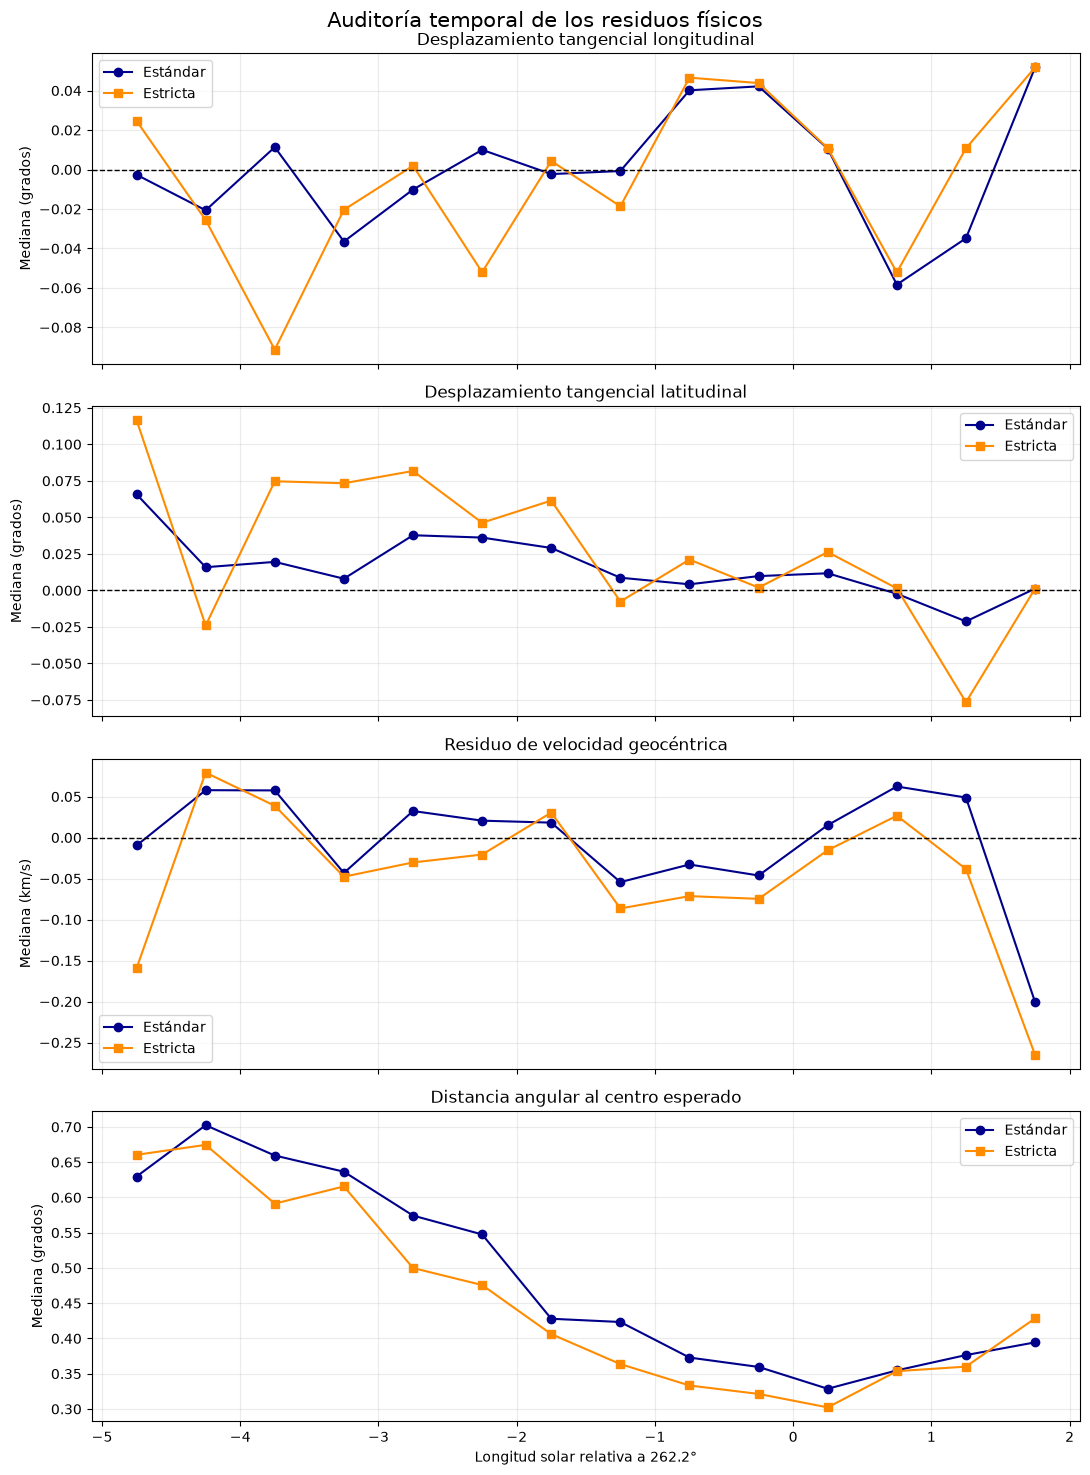

In [147]:
# Visualizar si queda alguna estructura temporal en los residuos físicos finales

fig, ejes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(11, 15),
    sharex=True,
)

configuracion_muestras = {
    "Estándar": {
        "color": "darkblue",
        "marcador": "o",
    },
    "Estricta": {
        "color": "darkorange",
        "marcador": "s",
    },
}

configuracion_paneles = [
    {
        "columna": "delta_lambda_mediana",
        "titulo": (
            "Desplazamiento tangencial longitudinal"
        ),
        "etiqueta_y": "Mediana (grados)",
        "linea_cero": True,
    },
    {
        "columna": "delta_beta_mediana",
        "titulo": (
            "Desplazamiento tangencial latitudinal"
        ),
        "etiqueta_y": "Mediana (grados)",
        "linea_cero": True,
    },
    {
        "columna": "residuo_vgeo_mediano",
        "titulo": (
            "Residuo de velocidad geocéntrica"
        ),
        "etiqueta_y": "Mediana (km/s)",
        "linea_cero": True,
    },
    {
        "columna": "distancia_angular_mediana",
        "titulo": (
            "Distancia angular al centro esperado"
        ),
        "etiqueta_y": "Mediana (grados)",
        "linea_cero": False,
    },
]

for eje, panel in zip(ejes,configuracion_paneles,):
    for muestra, configuracion in (configuracion_muestras.items()):
        datos = comparacion_residuos_fisicos_intervalos.loc[comparacion_residuos_fisicos_intervalos["muestra"].eq(muestra)]

        eje.plot(
            datos["centro_intervalo"],
            datos[panel["columna"]],
            marker=configuracion["marcador"],
            color=configuracion["color"],
            linewidth=1.5,
            label=muestra,
        )

    if panel["linea_cero"]:
        eje.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
        )

    eje.set_title(
        panel["titulo"]
    )

    eje.set_ylabel(
        panel["etiqueta_y"]
    )

    eje.grid(alpha=0.25)
    eje.legend()

ejes[-1].set_xlabel("Longitud solar relativa a 262.2°")

fig.suptitle("Auditoría temporal de los residuos físicos", fontsize=15,)

plt.tight_layout()
plt.show()

## Preparar e interpretar el brillo

In [164]:
# Crear copias de las muestras finales de la etapa 5 para preparar las variables de brillo

df_gem_estandar_brillo = df_gem_estandar_residuos.copy()
df_gem_estricta_brillo = df_gem_estricta_residuos.copy()

columnas_necesarias_brillo = [
    "Unique trajectory (identifier)",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "delta_sol_lon_deg",
    "source_year",
    "distancia_angular_centro_deg",
    "residuo_vgeo_km_s",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
]

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    columnas_faltantes = [columna for columna in columnas_necesarias_brillo if columna not in df_muestra_brillo.columns]
    
    if columnas_faltantes:
        raise ValueError(f"Faltan columnas en la muestra {nombre_muestra}: {columnas_faltantes}")
    
comprobaciones_inicio_brillo = pd.DataFrame(
    {
        "muestra": [
            "Estándar",
            "Estricta",
        ],
        "filas_obtenidas": [
            len(df_gem_estandar_brillo),
            len(df_gem_estricta_brillo),
        ],
        "filas_esperadas": [
            19079,
            7040,
        ],
    }
)

comprobaciones_inicio_brillo["coincide"] = comprobaciones_inicio_brillo["filas_obtenidas"] == comprobaciones_inicio_brillo["filas_esperadas"]

display(comprobaciones_inicio_brillo)

if not comprobaciones_inicio_brillo["coincide"].all():
    raise ValueError("Las muestras de brillo no coinciden con el final de la etapa 5.")

,muestra,filas_obtenidas,filas_esperadas,coincide
0,Estándar,19079,19079,True
1,Estricta,7040,7040,True


In [165]:
# Resumir la distribución de la magntiud máxima y la altura del máximo en las dos muestras

def resumir_variable_fisica(serie, nombre_muestera, nombre_variable):
    serie_numerica = pd.to_numeric(serie, errors = "coerce")
    
    mascara_finita = serie_numerica.notna() & np.isfinite(serie_numerica)
    
    valores_validos = serie_numerica.loc[mascara_finita]
    
    minimo = valores_validos.min()
    maximo = valores_validos.max()
    
    return {
        "muestra": nombre_muestra,
        "variable": nombre_variable,
        "trayectorias": len(serie_numerica),
        "valores_faltantes": serie_numerica.isna().sum(),
        "valores_no_finitos": (
            serie_numerica.notna()
            & ~np.isfinite(serie_numerica)
        ).sum(),
        "valores_unicos": valores_validos.nunique(),
        "minimo": minimo,
        "percentil_0_1": valores_validos.quantile(0.001),
        "percentil_1": valores_validos.quantile(0.01),
        "percentil_5": valores_validos.quantile(0.05),
        "percentil_25": valores_validos.quantile(0.25),
        "mediana": valores_validos.median(),
        "media": valores_validos.mean(),
        "percentil_75": valores_validos.quantile(0.75),
        "percentil_95": valores_validos.quantile(0.95),
        "percentil_99": valores_validos.quantile(0.99),
        "percentil_99_9": valores_validos.quantile(0.999),
        "maximo": maximo,
        "repeticiones_minimo": (
            valores_validos.eq(minimo).sum()
        ),
        "repeticiones_maximo": (
            valores_validos.eq(maximo).sum()
        ),
    }
    
registros_distribucion_brillo = []

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    for columna in ["Peak (AbsMag)", "Peak Ht (km)"]:
        registros_distribucion_brillo.append(resumir_variable_fisica(df_muestra_brillo[columna], nombre_muestra, columna))
        
resumen_distribucion_brillo = pd.DataFrame(registros_distribucion_brillo)

columnas_redondear_brillo = [
    "minimo",
    "percentil_0_1",
    "percentil_1",
    "percentil_5",
    "percentil_25",
    "mediana",
    "media",
    "percentil_75",
    "percentil_95",
    "percentil_99",
    "percentil_99_9",
    "maximo",
]

resumen_distribucion_brillo[columnas_redondear_brillo] = resumen_distribucion_brillo[columnas_redondear_brillo].round(4)

display(resumen_distribucion_brillo)

,muestra,variable,trayectorias,valores_faltantes,valores_no_finitos,valores_unicos,minimo,percentil_0_1,percentil_1,percentil_5,percentil_25,mediana,media,percentil_75,percentil_95,percentil_99,percentil_99_9,maximo,repeticiones_minimo,repeticiones_maximo
0,Estándar,Peak (AbsMag),19079,0,0,664,-29.3500,-12.5467,-2.8000,-2.0200,-1.1300,-0.4900,-0.4939,0.1600,1.1300,1.9322,2.6800,3.8200,1,1
1,Estándar,Peak Ht (km),19079,0,0,18030,53.0036,64.1413,74.5714,79.5334,84.8150,87.8898,87.5752,90.7183,94.5594,97.3099,99.8427,104.4529,1,1
2,Estricta,Peak (AbsMag),7040,0,0,537,-29.3500,-17.6486,-3.0800,-2.1700,-1.2825,-0.6800,-0.7286,-0.0600,0.7700,1.3700,2.0192,2.6700,1,1
3,Estricta,Peak Ht (km),7040,0,0,6899,61.0948,68.4869,75.9239,80.1835,85.0748,87.9103,87.7487,90.6830,94.6003,97.3125,99.8427,104.4529,1,1


In [167]:
# Contar progresivamente las trayectorias de la cola brillante sin aplicar todavía ningún filtro

umbrales_diagnostico_magnitud = [
    -3,
    -4,
    -5,
    -8,
    -10,
    -15,
    -20,
]

registros_cola_brillante = []

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    for umbral in umbrales_diagnostico_magnitud:
        mascara_extrema = df_muestra_brillo["Peak (AbsMag)"].le(umbral)
        
        cantidad = mascara_extrema.sum()
        
        registros_cola_brillante.append(
            {
                "muestra": nombre_muestra,
                "umbral_magnitud": umbral,
                "interpretacion": (
                    f"M ≤ {umbral}"
                ),
                "trayectorias": cantidad,
                "porcentaje_muestra": round(
                    100
                    * cantidad
                    / len(df_muestra_brillo),
                    4,
                ),
            }
        )
        
resumen_cola_brillante = pd.DataFrame(registros_cola_brillante)

display(resumen_cola_brillante)

,muestra,umbral_magnitud,interpretacion,trayectorias,porcentaje_muestra
0,Estándar,-3,M ≤ -3,142,0.7443
1,Estándar,-4,M ≤ -4,43,0.2254
2,Estándar,-5,M ≤ -5,37,0.1939
3,Estándar,-8,M ≤ -8,25,0.1310
4,Estándar,-10,M ≤ -10,25,0.1310
5,Estándar,-15,M ≤ -15,14,0.0734
6,Estándar,-20,M ≤ -20,4,0.0210
7,Estricta,-3,M ≤ -3,83,1.1790
8,Estricta,-4,M ≤ -4,31,0.4403
9,Estricta,-5,M ≤ -5,28,0.3977


In [168]:
# Mostrar las trayectorias con las magnitudes más negativas y comprobar si también pertenecen a la muestra estricta

ids_muestra_estricta = set(df_gem_estricta_brillo["Unique trajectory (identifier)"])

columnas_candidatas_extremos = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "source_year",
    "source_file",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "Vgeo (km/s)",
    "Vavg (km/s)",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "Beg in (FOV)",
    "End in (FOV)",
    "Participating (stations)",
]

columnas_disponibles_extremos = [columna for columna in columnas_candidatas_extremos if columna in df_gem_estandar_brillo.columns]

trayectorias_mas_brillantes = df_gem_estandar_brillo.nsmallest(40, "Peak (AbsMag)")[columnas_disponibles_extremos].copy()

trayectorias_mas_brillantes["pertenece_muestra_estricta"] = trayectorias_mas_brillantes["Unique trajectory (identifier)"].isin(ids_muestra_estricta)

display(trayectorias_mas_brillantes)

,Unique trajectory (identifier),Beginning (UTC Time),source_year,source_file,Peak (AbsMag),Peak Ht (km),Vgeo (km/s),Vavg (km/s),Qc (deg),MedianFitErr (arcsec),Num (stat),Beg in (FOV),End in (FOV),Participating (stations),pertenece_muestra_estricta
76100,20221213232357_4NeQm,2022-12-13 23:23:57.905149+00:00,2022,traj_summary_monthly_202212.txt,-29.35,69.2281,34.20414,35.56774,79.55,56.61,4,True,True,"BE0008,BE000B,UK0034,UK006B",True
71387,20221212194155_2wRWS,2022-12-12 19:41:55.092359+00:00,2022,traj_summary_monthly_202212.txt,-26.70,94.3390,32.92877,34.14312,89.77,42.69,9,True,True,"BE0001,BE0005,BE0009,BE000A,BE000B,BE000C,NL00...",True
73427,20221213044153_MZS2M,2022-12-13 04:41:53.243486+00:00,2022,traj_summary_monthly_202212.txt,-25.51,84.6050,33.96228,35.16363,85.89,56.39,8,True,True,"BE0001,BE0005,BE000B,BE000C,BE000G,FR000X,UK00...",True
73415,20221213043845_L4z0M,2022-12-13 04:38:45.813402+00:00,2022,traj_summary_monthly_202212.txt,-21.40,88.6939,33.84674,34.54509,87.16,57.71,4,True,True,"BE0009,BE000B,BE000C,UK007W",True
71884,20221212230543_dvDsG,2022-12-12 23:05:43.627319+00:00,2022,traj_summary_monthly_202212.txt,-18.09,83.5800,33.98695,35.30674,50.00,48.29,6,True,True,"BE0001,BE000B,BE000M,FR000Y,NL0001,NL000L",True
72716,20221213020709_qkPqS,2022-12-13 02:07:09.102856+00:00,2022,traj_summary_monthly_202212.txt,-17.99,88.1459,33.84656,34.68049,84.95,30.80,4,True,True,"BE0003,BE000B,BE000C,FR000X",True
72717,20221213020716_Uguy8,2022-12-13 02:07:16.867087+00:00,2022,traj_summary_monthly_202212.txt,-17.77,93.0235,33.16762,33.91322,81.17,37.03,6,True,True,"BE0005,BE0008,BE0009,BE000B,BE000C,BE000G",True
73222,20221213035452_auLrA,2022-12-13 03:54:52.119983+00:00,2022,traj_summary_monthly_202212.txt,-17.67,93.4692,33.83827,35.17351,65.40,45.27,4,True,True,"BE0001,BE000B,DE0001,NL0009",True
75149,20221213190853_9FHmf,2022-12-13 19:08:53.545353+00:00,2022,traj_summary_monthly_202212.txt,-17.13,88.5174,34.31877,35.83343,68.57,37.04,2,True,True,"BE0003,BE000C",False
73379,20221213042901_I5a7J,2022-12-13 04:29:01.808282+00:00,2022,traj_summary_monthly_202212.txt,-17.12,92.1255,33.91938,34.57158,62.52,29.54,5,True,True,"BE0005,BE0009,BE000B,BE000C,BE000G",True


In [170]:
# Resumir por año la cantidad y el valor mínimo de las magnitudes extremadamente brillantes

registros_extremos_anuales = []

for anio, df_anio in df_gem_estandar_brillo.groupby("source_year", sort = True):
    magnitud = df_anio["Peak (AbsMag)"]
    
    registros_extremos_anuales.append(
        {
            "anio": anio,
            "trayectorias": len(df_anio),
            "magnitud_minima": magnitud.min(),
            "percentil_0_1": magnitud.quantile(0.001),
            "percentil_1": magnitud.quantile(0.01),
            "cantidad_menor_igual_menos_4": (
                magnitud.le(-4).sum()
            ),
            "cantidad_menor_igual_menos_8": (
                magnitud.le(-8).sum()
            ),
            "cantidad_menor_igual_menos_10": (
                magnitud.le(-10).sum()
            ),
        }
    )
    
resumen_extremos_anuales = pd.DataFrame(registros_extremos_anuales)

columnas_redondear_extremos = [
    "magnitud_minima",
    "percentil_0_1",
    "percentil_1",
]

resumen_extremos_anuales[columnas_redondear_extremos] = resumen_extremos_anuales[columnas_redondear_extremos].round(4)

display(resumen_extremos_anuales)

,anio,trayectorias,magnitud_minima,percentil_0_1,percentil_1,cantidad_menor_igual_menos_4,cantidad_menor_igual_menos_8,cantidad_menor_igual_menos_10
0,2019,430,-2.74,-2.5427,-2.1668,0,0,0
1,2020,1002,-4.68,-3.3699,-2.7294,1,0,0
2,2021,1904,-10.90,-4.8773,-2.6097,3,1,1
3,2022,3712,-29.35,-19.0466,-3.9423,37,24,24
4,2023,3397,-3.88,-3.3289,-2.5904,0,0,0
5,2024,2459,-4.09,-3.7284,-2.6700,1,0,0
6,2025,6175,-4.05,-3.5874,-2.7226,1,0,0


In [171]:
# Identificar provisionalmente la cola fotométrica extrema y resumir su concentración temporal

umbral_magnitud_extrema = -8

df_extremos_fotometricos = df_gem_estandar_brillo.loc[df_gem_estandar_brillo["Peak (AbsMag)"].le(umbral_magnitud_extrema)].copy()

ids_estrictos = set(df_gem_estricta_brillo["Unique trajectory (identifier)"])

df_extremos_fotometricos["pertenece_muestra_estricta"] = df_extremos_fotometricos["Unique trajectory (identifier)"].isin(ids_estrictos)

df_extremos_fotometricos["fecha_utc"] = df_extremos_fotometricos["Beginning (UTC Time)"].dt.floor("D")

resumen_temporal_extremos = df_extremos_fotometricos.groupby("fecha_utc", as_index = False, sort = True).agg(
    trayectorias = (
        "Unique trajectory (identifier)",
        "size",
    ),
    magnitud_minima = (
        "Peak (AbsMag)",
        "min",
    ),
    magnitud_mediana = (
        "Peak (AbsMag)",
        "median",
    ),
    trayectorias_estrictas = (
        "pertenece_muestra_estricta",
        "sum",
    ),
    estaciones_mediana = (
        "Num (stat)",
        "median",
    ),
)

resumen_temporal_extremos[
    [
        "magnitud_minima",
        "magnitud_mediana",
        "estaciones_mediana",
    ]
] = resumen_temporal_extremos[
    [
        "magnitud_minima",
        "magnitud_mediana",
        "estaciones_mediana",
    ]
].round(3)

print("Trayectoria con magnitud menor o igual que ", umbral_magnitud_extrema, ":", len(df_extremos_fotometricos))

display(resumen_temporal_extremos)

Trayectoria con magnitud menor o igual que  -8 : 25


,fecha_utc,trayectorias,magnitud_minima,magnitud_mediana,trayectorias_estrictas,estaciones_mediana
0,2021-12-14 00:00:00+00:00,1,-10.90,-10.90,0,2.0
1,2022-12-11 00:00:00+00:00,1,-15.93,-15.93,1,4.0
2,2022-12-12 00:00:00+00:00,6,-26.70,-15.03,5,5.5
3,2022-12-13 00:00:00+00:00,17,-29.35,-16.90,15,4.0


In [172]:
# Comparar la presencia de estaciones en los eventos extremos con su presencia en todas las Gemínidas estándar de 2022

def contar_eventos_por_estacion(df_entrada):
    tabla_estaciones = df_entrada[
        [
            "Unique trajectory (identifier)",
            "Participating (stations)",
        ]
    ].copy()
    
    tabla_estaciones["estacion"] = tabla_estaciones["Participating (stations)"].astype("string").str.split(",")
    
    tabla_estaciones = tabla_estaciones.explode("estacion")
    
    tabla_estaciones["estacion"] = tabla_estaciones["estacion"].str.strip()
    
    conteo_estaciones = tabla_estaciones.groupby("estacion", as_index = False).agg(eventos = ("Unique trajectory (identifier)", "nunique"))
    
    return conteo_estaciones

df_estandar_2022 = df_gem_estandar_brillo.loc[df_gem_estandar_brillo["source_year"].eq(2022)].copy()
df_extremos_2022 = df_extremos_fotometricos.loc[df_extremos_fotometricos["source_year"].eq(2022)].copy()

conteo_estaciones_extremos = contar_eventos_por_estacion(df_extremos_2022).rename(columns = {"eventos": "eventos_extremos"})
conteo_estaciones_2022 = contar_eventos_por_estacion(df_estandar_2022).rename(columns = {"eventos": "eventos_totales_2022"})

comparacion_estaciones_extremos = conteo_estaciones_extremos.merge(conteo_estaciones_2022, on = "estacion", how = "left", validate = "one_to_one")

comparacion_estaciones_extremos["porcentaje_extremos"] = (100 * comparacion_estaciones_extremos["eventos_extremos"] / len(df_extremos_2022)).round(2)
comparacion_estaciones_extremos["porcentaje_total_2022"] = (100 * comparacion_estaciones_extremos["eventos_totales_2022"] / len(df_estandar_2022)).round(2)
comparacion_estaciones_extremos["razon_concentracion"] = (comparacion_estaciones_extremos["porcentaje_extremos"] / comparacion_estaciones_extremos["porcentaje_total_2022"]).round(2)

comparacion_estaciones_extremos = comparacion_estaciones_extremos.sort_values(["eventos_extremos", "razon_concentracion"], ascending = [False, False], ignore_index = True)

display(comparacion_estaciones_extremos.head(20))

,estacion,eventos_extremos,eventos_totales_2022,porcentaje_extremos,porcentaje_total_2022,razon_concentracion
0,BE000B,21,130,87.50,3.50,25.00
1,BE000C,20,127,83.33,3.42,24.37
2,BE000G,12,90,50.00,2.42,20.66
3,BE0005,12,118,50.00,3.18,15.72
4,FR000X,9,98,37.50,2.64,14.20
5,BE0003,8,75,33.33,2.02,16.50
6,BE0008,7,97,29.17,2.61,11.18
7,BE0009,6,43,25.00,1.16,21.55
8,BE0001,5,103,20.83,2.77,7.52
9,NL0001,3,68,12.50,1.83,6.83


In [173]:
# Comparar la calidad geométrica y las propiedades físicas de la cola extrema con el resto de la muestra estándar

df_comparacion_extremos = df_gem_estandar_brillo.copy()

df_comparacion_extremos["grupo_fotometrico"] = np.where(df_comparacion_extremos["Peak (AbsMag)"].le(umbral_magnitud_extrema),"M ≤ -8","M > -8")

resumen_comparacion_extremos = df_comparacion_extremos.groupby("grupo_fotometrico", as_index = False).agg(
    trayectorias = (
        "Unique trajectory (identifier)",
        "size",
    ),
    magnitud_mediana = (
        "Peak (AbsMag)",
        "median",
    ),
    altura_pico_mediana = (
        "Peak Ht (km)",
        "median",
    ),
    qc_mediana = (
        "Qc (deg)",
        "median",
    ),
    error_ajuste_mediano = (
        "MedianFitErr (arcsec)",
        "median",
    ),
    estaciones_mediana = (
        "Num (stat)",
        "median",
    ),
    distancia_angular_mediana = (
        "distancia_angular_centro_deg",
        "median",
    ),
    residuo_vgeo_mediano = (
        "residuo_vgeo_km_s",
        "median",
    ),
    delta_sol_mediana = (
        "delta_sol_lon_deg",
        "median",
    ),
)

columnas_redondear_comparacion = [columna for columna in resumen_comparacion_extremos.columns if columna not in ["grupo_fotometrico","trayectorias"]]

resumen_comparacion_extremos[columnas_redondear_comparacion] = resumen_comparacion_extremos[columnas_redondear_comparacion].round(4)

display(resumen_comparacion_extremos)

,grupo_fotometrico,trayectorias,magnitud_mediana,altura_pico_mediana,qc_mediana,error_ajuste_mediano,estaciones_mediana,distancia_angular_mediana,residuo_vgeo_mediano,delta_sol_mediana
0,M > -8,19054,-0.49,87.8888,67.15,43.63,3.0,0.3814,-0.0144,-0.3526
1,M ≤ -8,25,-15.52,88.5174,79.55,36.48,4.0,0.4562,0.0548,-1.4722


In [174]:
# Marcar la cola fotométrica sospechosa y crear una magnitud de análisis sin modificar el valor original

umbral_fotometria_sospechosa = -8.0

def preparar_magnitud_analisis(df_entrada):
    df_resultado = df_entrada.copy()
    
    df_resultado["flag_fotometria_sospechosa"] = df_resultado["Peak (AbsMag)"].le(umbral_fotometria_sospechosa)
    
    df_resultado["magnitud_analisis"] = df_resultado["Peak (AbsMag)"].mask(df_resultado["flag_fotometria_sospechosa"])
    
    return df_resultado

df_gem_estandar_brillo = preparar_magnitud_analisis(df_gem_estandar_brillo)
df_gem_estricta_brillo = preparar_magnitud_analisis(df_gem_estricta_brillo)

registros_control_magnitud = []

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    cantidad_sospechosa = df_muestra_brillo["flag_fotometria_sospechosa"].sum()
    
    registros_control_magnitud.append(
        {
            "muestra": nombre_muestra,
            "trayectorias_totales": len(
                df_muestra_brillo
            ),
            "fotometria_sospechosa": (
                cantidad_sospechosa
            ),
            "porcentaje_sospechoso": round(
                100
                * cantidad_sospechosa
                / len(df_muestra_brillo),
                4,
            ),
            "magnitudes_disponibles_analisis": (
                df_muestra_brillo[
                    "magnitud_analisis"
                ].notna().sum()
            ),
            "magnitud_original_modificada": (
                ~df_muestra_brillo[
                    "Peak (AbsMag)"
                ].eq(
                    df_muestra_brillo[
                        "Peak (AbsMag)"
                    ]
                )
            ).sum(),
        }
    )
    
control_preparacion_magnitud = pd.DataFrame(registros_control_magnitud)

display(control_preparacion_magnitud)
    
    

,muestra,trayectorias_totales,fotometria_sospechosa,porcentaje_sospechoso,magnitudes_disponibles_analisis,magnitud_original_modificada
0,Estándar,19079,25,0.1310,19054,0
1,Estricta,7040,21,0.2983,7019,0


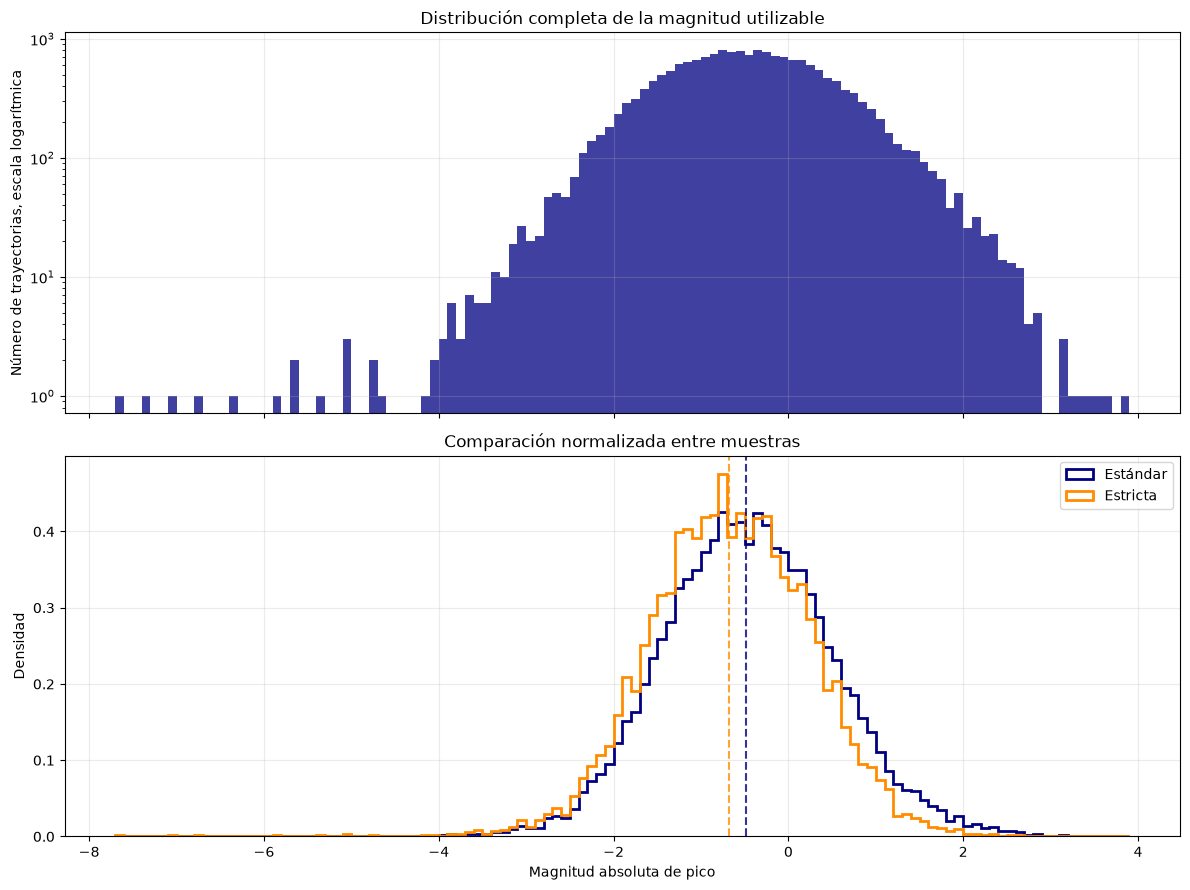

In [176]:
# Visualizar la distribución de magnitud después de marcar la cola fotométrica sospechosa

magnitud_estandar = df_gem_estandar_brillo["magnitud_analisis"].dropna()

magnitud_estricta = df_gem_estricta_brillo["magnitud_analisis"].dropna()

limite_inferior_histograma = np.floor(min(magnitud_estandar.min(), magnitud_estricta.min())* 10) / 10

limite_superior_histograma = np.ceil(max(magnitud_estandar.max(), magnitud_estricta.max())* 10) / 10

bordes_magnitud = np.arange(limite_inferior_histograma, limite_superior_histograma + 0.1, 0.1,)

fig, ejes = plt.subplots(
    2,
    1,
    figsize = (12, 9),
    sharex = True,
)

ejes[0].hist(
    magnitud_estandar,
    bins = bordes_magnitud,
    color = "navy",
    alpha = 0.75,
)

ejes[0].set_yscale("log")

ejes[0].set_title("Distribución completa de la magnitud utilizable")

ejes[0].set_ylabel("Número de trayectorias, escala logarítmica")

ejes[1].hist(
    magnitud_estandar,
    bins = bordes_magnitud,
    density = True,
    histtype = "step",
    linewidth = 2,
    color = "navy",
    label = "Estándar",
)

ejes[1].hist(
    magnitud_estricta,
    bins = bordes_magnitud,
    density = True,
    histtype = "step",
    linewidth = 2,
    color = "darkorange",
    label = "Estricta",
)

ejes[1].axvline(
    magnitud_estandar.median(),
    color = "navy",
    linestyle = "--",
    alpha = 0.8,
)

ejes[1].axvline(
    magnitud_estricta.median(),
    color = "darkorange",
    linestyle = "--",
    alpha = 0.8,
)

ejes[1].set_title("Comparación normalizada entre muestras")

ejes[1].set_xlabel("Magnitud absoluta de pico")

ejes[1].set_ylabel("Densidad")

ejes[1].legend()

for eje in ejes:
    eje.grid(alpha = 0.25)

plt.tight_layout()
plt.show()

In [179]:
# Crear grupos descriptivos comunes de magnitud sin sustituir la variable continua principal

limites_grupos_magnitud = [
    -np.inf,
    -1,
    0,
    1,
    np.inf,
]

etiquetas_grupos_magnitud = [
    "M ≤ -1",
    "-1 < M ≤ 0",
    "0 < M ≤ 1",
    "M > 1",
]

for df_muestras_brillo in [df_gem_estandar_brillo, df_gem_estricta_brillo]:
    df_muestra_brillo["grupo_magnitud"] = pd.cut(
        df_muestra_brillo["magnitud_analisis"],
        bins = limites_grupos_magnitud,
        labels = etiquetas_grupos_magnitud,
        right = True,
        include_lowest = True,
        ordered = True,
    )
    
registros_grupos_magnitud = []

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    grupos = df_muestra_brillo.groupby("grupo_magnitud", observed = False, sort = False)
    
    for grupo, df_grupo in grupos:
        registros_grupos_magnitud.append(
            {
                "muestra": nombre_muestra,
                "grupo_magnitud": grupo,
                "trayectorias": len(df_grupo),
                "magnitud_mediana": (
                    df_grupo[
                        "magnitud_analisis"
                    ].median()
                ),
                "altura_pico_mediana": (
                    df_grupo[
                        "Peak Ht (km)"
                    ].median()
                ),
                "altura_pico_percentil_25": (
                    df_grupo[
                        "Peak Ht (km)"
                    ].quantile(0.25)
                ),
                "altura_pico_percentil_75": (
                    df_grupo[
                        "Peak Ht (km)"
                    ].quantile(0.75)
                ),
                "delta_sol_mediana": (
                    df_grupo[
                        "delta_sol_lon_deg"
                    ].median()
                ),
                "distancia_angular_mediana": (
                    df_grupo[
                        "distancia_angular_centro_deg"
                    ].median()
                ),
                "distancia_angular_p95": (
                    df_grupo[
                        "distancia_angular_centro_deg"
                    ].quantile(0.95)
                ),
                "estaciones_mediana": (
                    df_grupo[
                        "Num (stat)"
                    ].median()
                ),
            }
        )
        
resumen_grupos_magnitud = pd.DataFrame(registros_grupos_magnitud)

columnas_redondear_grupos = [
    "magnitud_mediana",
    "altura_pico_mediana",
    "altura_pico_percentil_25",
    "altura_pico_percentil_75",
    "delta_sol_mediana",
    "distancia_angular_mediana",
    "distancia_angular_p95",
    "estaciones_mediana",
]

resumen_grupos_magnitud[columnas_redondear_grupos] = resumen_grupos_magnitud[columnas_redondear_grupos].round(4)

display(resumen_grupos_magnitud)

,muestra,grupo_magnitud,trayectorias,magnitud_mediana,altura_pico_mediana,altura_pico_percentil_25,altura_pico_percentil_75,delta_sol_mediana,distancia_angular_mediana,distancia_angular_p95,estaciones_mediana
0,Estándar,-1 < M ≤ 0,7572,-0.500,87.7324,85.3584,90.2324,-0.3510,0.3754,1.0167,3.0
1,Estándar,0 < M ≤ 1,4633,0.380,90.0171,87.9792,92.1754,-0.5367,0.4050,1.0612,3.0
2,Estándar,M ≤ -1,5655,-1.460,84.3350,81.3696,87.3760,-0.1560,0.3554,1.0252,3.0
3,Estándar,M > 1,1194,1.400,91.9336,90.1978,93.9870,-0.8043,0.4726,1.1618,2.0
4,Estricta,-1 < M ≤ 0,2838,-0.520,88.2972,86.1349,90.6821,-0.3721,0.3518,0.9577,5.0
5,Estricta,0 < M ≤ 1,1420,0.335,90.3654,88.3817,92.5628,-0.5351,0.3699,1.0340,5.0
6,Estricta,M ≤ -1,2563,-1.490,85.0529,82.3799,87.8634,-0.1914,0.3170,0.9153,5.0
7,Estricta,M > 1,198,1.250,92.3907,90.3678,94.9099,-0.5857,0.4484,1.0349,4.0


In [180]:
# Resumir la evolución de la magnitud y la altura del máximo a lo largo de la ventana solar

limites_solares_brillo = np.arange(-5.0, 2.0 + 0.5, 0.5,)

for df_muestra_brillo in [df_gem_estandar_brillo, df_gem_estricta_brillo,]:
    df_muestra_brillo["intervalo_delta_sol_brillo"] = pd.cut(
        df_muestra_brillo["delta_sol_lon_deg"],
        bins = limites_solares_brillo,
        right = False,
        include_lowest = True,
    )

registros_evolucion_brillo = []

for nombre_muestra, df_muestra_brillo in {"Estándar": df_gem_estandar_brillo, "Estricta": df_gem_estricta_brillo}.items():
    grupos_solares = df_muestra_brillo.groupby("intervalo_delta_sol_brillo", observed = True, sort = True)
    
    for intervalo, df_intervalo in grupos_solares:
        magnitudes_validas = df_intervalo["magnitud_analisis"].dropna()
        
        registros_evolucion_brillo.append(
            {
                "muestra": nombre_muestra,
                "intervalo_delta_sol": str(
                    intervalo
                ),
                "trayectorias_totales": len(
                    df_intervalo
                ),
                "magnitudes_validas": len(
                    magnitudes_validas
                ),
                "centro_intervalo": (
                    intervalo.left
                    + intervalo.right
                ) / 2,
                "magnitud_percentil_25": (
                    magnitudes_validas.quantile(0.25)
                ),
                "magnitud_mediana": (
                    magnitudes_validas.median()
                ),
                "magnitud_percentil_75": (
                    magnitudes_validas.quantile(0.75)
                ),
                "altura_pico_mediana": (
                    df_intervalo[
                        "Peak Ht (km)"
                    ].median()
                ),
                "distancia_angular_mediana": (
                    df_intervalo[
                        "distancia_angular_centro_deg"
                    ].median()
                ),
            }
        )

resumen_evolucion_brillo = pd.DataFrame(registros_evolucion_brillo)

columnas_redondear_evolucion = [
    "centro_intervalo",
    "magnitud_percentil_25",
    "magnitud_mediana",
    "magnitud_percentil_75",
    "altura_pico_mediana",
    "distancia_angular_mediana",
]

resumen_evolucion_brillo[columnas_redondear_evolucion] = resumen_evolucion_brillo[columnas_redondear_evolucion].round(4)

display(resumen_evolucion_brillo)

,muestra,intervalo_delta_sol,trayectorias_totales,magnitudes_validas,centro_intervalo,magnitud_percentil_25,magnitud_mediana,magnitud_percentil_75,altura_pico_mediana,distancia_angular_mediana
0,Estándar,"[-5.0, -4.5)",170,170,-4.75,-0.9625,-0.340,0.3475,88.0818,0.6296
1,Estándar,"[-4.5, -4.0)",227,227,-4.25,-0.9200,-0.420,0.1750,87.6743,0.7024
2,Estándar,"[-4.0, -3.5)",214,214,-3.75,-1.0700,-0.340,0.2500,88.0135,0.6594
3,Estándar,"[-3.5, -3.0)",406,406,-3.25,-1.0075,-0.310,0.4675,88.3042,0.6365
4,Estándar,"[-3.0, -2.5)",370,369,-2.75,-0.9500,-0.210,0.4600,88.1473,0.5743
5,Estándar,"[-2.5, -2.0)",601,600,-2.25,-0.8425,-0.210,0.5400,88.5597,0.5475
6,Estándar,"[-2.0, -1.5)",976,969,-1.75,-0.8100,-0.170,0.4700,88.7760,0.4279
7,Estándar,"[-1.5, -1.0)",2009,1997,-1.25,-0.7800,-0.170,0.4400,88.3342,0.4233
8,Estándar,"[-1.0, -0.5)",2963,2960,-0.75,-0.9100,-0.300,0.3025,88.4985,0.3729
9,Estándar,"[-0.5, 0.0)",5366,5366,-0.25,-1.1300,-0.550,0.0700,87.7010,0.3596


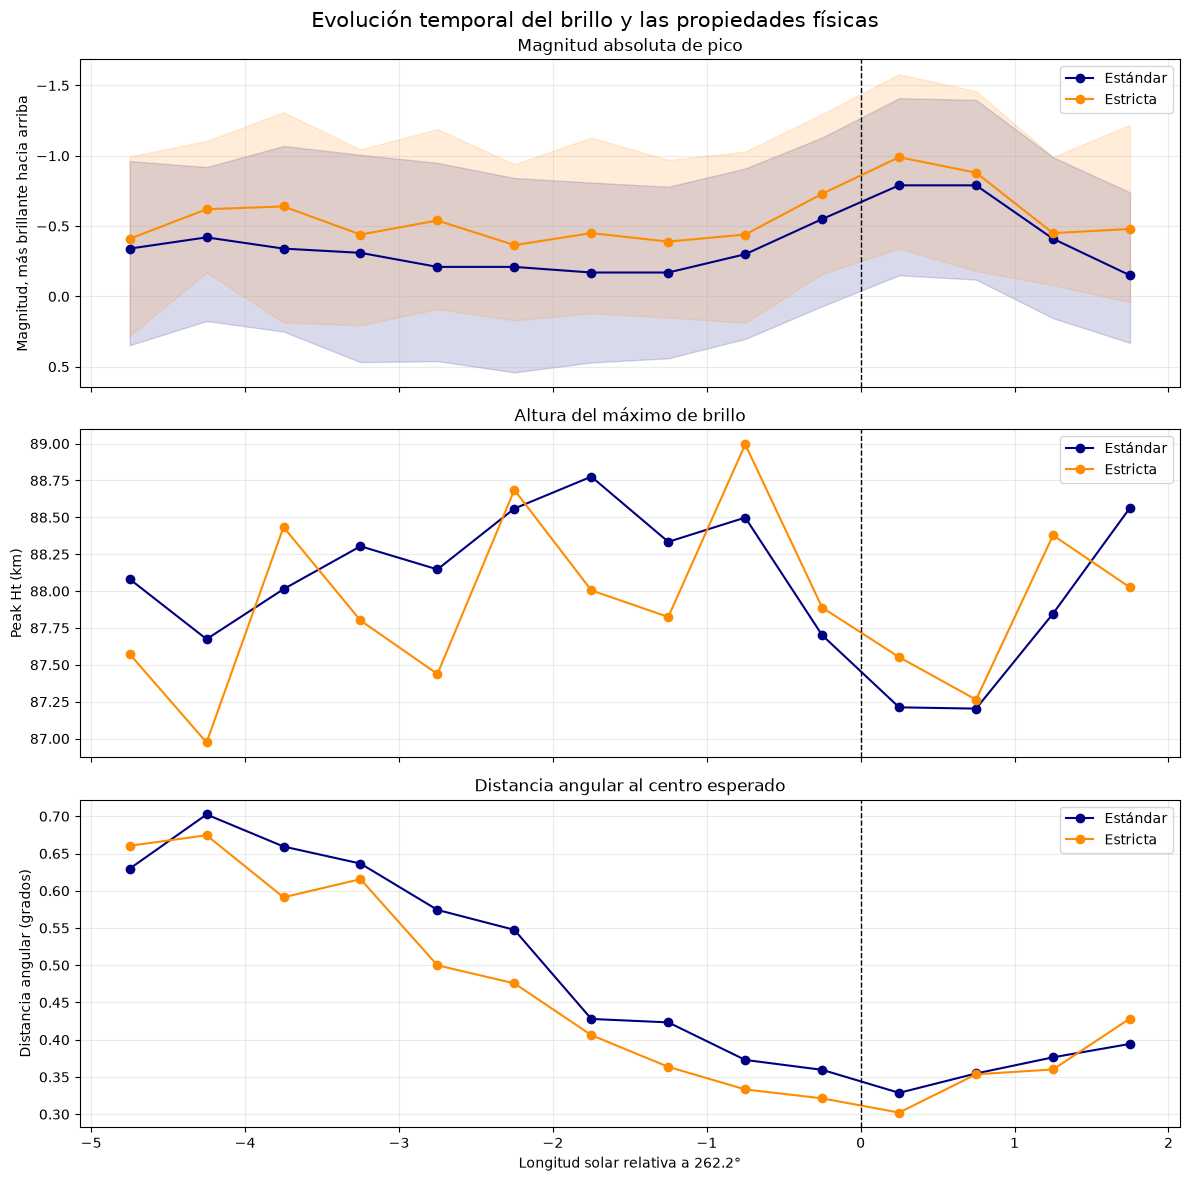

In [181]:
# Visualizar conjuntamente la evolución temporal del brillo, la altura del máximo y la dispersión angular

fig, ejes = plt.subplots(
    3,
    1,
    figsize = (12, 12),
    sharex = True,
)

colores_muestras = {
    "Estándar": "navy",
    "Estricta": "darkorange",
}

for nombre_muestra, color in colores_muestras.items():
    datos_muestra = (
        resumen_evolucion_brillo.loc[
            resumen_evolucion_brillo[
                "muestra"
            ].eq(nombre_muestra)
        ]
        .sort_values("centro_intervalo")
    )
    
    eje_x = datos_muestra[
        "centro_intervalo"
    ].to_numpy(
        dtype = float
    )
    
    magnitud_mediana = datos_muestra[
        "magnitud_mediana"
    ].to_numpy(
        dtype = float
    )
    
    magnitud_p25 = datos_muestra[
        "magnitud_percentil_25"
    ].to_numpy(
        dtype = float
    )
    
    magnitud_p75 = datos_muestra[
        "magnitud_percentil_75"
    ].to_numpy(
        dtype = float
    )
    
    altura_mediana = datos_muestra[
        "altura_pico_mediana"
    ].to_numpy(
        dtype = float
    )
    
    distancia_mediana = datos_muestra[
        "distancia_angular_mediana"
    ].to_numpy(
        dtype = float
    )
    
    ejes[0].plot(
        eje_x,
        magnitud_mediana,
        marker = "o",
        color = color,
        label = nombre_muestra,
    )
    
    ejes[0].fill_between(
        eje_x,
        magnitud_p25,
        magnitud_p75,
        color = color,
        alpha = 0.15,
    )
    
    ejes[1].plot(
        eje_x,
        altura_mediana,
        marker = "o",
        color = color,
        label = nombre_muestra,
    )
    
    ejes[2].plot(
        eje_x,
        distancia_mediana,
        marker = "o",
        color = color,
        label = nombre_muestra,
    )

ejes[0].invert_yaxis()

ejes[0].set_title(
    "Magnitud absoluta de pico"
)

ejes[0].set_ylabel(
    "Magnitud, más brillante hacia arriba"
)

ejes[1].set_title(
    "Altura del máximo de brillo"
)

ejes[1].set_ylabel(
    "Peak Ht (km)"
)

ejes[2].set_title(
    "Distancia angular al centro esperado"
)

ejes[2].set_ylabel(
    "Distancia angular (grados)"
)

ejes[2].set_xlabel(
    "Longitud solar relativa a 262.2°"
)

for eje in ejes:
    eje.axvline(
        0,
        color = "black",
        linestyle = "--",
        linewidth = 1,
    )
    
    eje.grid(
        alpha = 0.25
    )
    
    eje.legend()

fig.suptitle(
    "Evolución temporal del brillo y las propiedades físicas",
    fontsize = 15,
)

plt.tight_layout()
plt.show()

## Auditoría de sesgos

In [182]:
# Preparar las muestras con magnitud válida para la auditoría de sesgos

orden_grupos_magnitud = [
    "M ≤ -1",
    "-1 < M ≤ 0",
    "0 < M ≤ 1",
    "M > 1"
]

limites_solares_sesgos = np.arange(-5.0, 2.0 + 1.0, 1.0)


def preparar_muestra_sesgos(df):
    df_sesgos = df.loc[df["magnitud_analisis"].notna()].copy()

    df_sesgos["grupo_magnitud"] = pd.Categorical(
        df_sesgos["grupo_magnitud"].astype("string"),
        categories=orden_grupos_magnitud,
        ordered=True
    )

    df_sesgos["estrato_solar_sesgos"] = pd.cut(
        df_sesgos["delta_sol_lon_deg"],
        bins=limites_solares_sesgos,
        right=False,
        include_lowest=True
    )

    return df_sesgos


df_gem_estandar_sesgos = preparar_muestra_sesgos(df_gem_estandar_brillo)

df_gem_estricta_sesgos = preparar_muestra_sesgos(df_gem_estricta_brillo)


resumen_preparacion_sesgos = pd.DataFrame([
    {
        "muestra": "Estándar",
        "filas_obtenidas": len(df_gem_estandar_sesgos),
        "filas_esperadas": 19054,
        "grupos_faltantes": int(
            df_gem_estandar_sesgos["grupo_magnitud"].isna().sum()
        ),
        "estratos_solares_faltantes": int(
            df_gem_estandar_sesgos["estrato_solar_sesgos"].isna().sum()
        )
    },
    {
        "muestra": "Estricta",
        "filas_obtenidas": len(df_gem_estricta_sesgos),
        "filas_esperadas": 7019,
        "grupos_faltantes": int(
            df_gem_estricta_sesgos["grupo_magnitud"].isna().sum()
        ),
        "estratos_solares_faltantes": int(
            df_gem_estricta_sesgos["estrato_solar_sesgos"].isna().sum()
        )
    }
])

resumen_preparacion_sesgos["coincide"] = resumen_preparacion_sesgos["filas_obtenidas"] == resumen_preparacion_sesgos["filas_esperadas"]

display(resumen_preparacion_sesgos)

if not (resumen_preparacion_sesgos["coincide"].all() and resumen_preparacion_sesgos["grupos_faltantes"].eq(0).all() and resumen_preparacion_sesgos["estratos_solares_faltantes"].eq(0).all()):
    raise ValueError("Las muestras no quedaron correctamente preparadas para la auditoría.")

print("Las muestras para la auditoría de sesgos fueron preparadas correctamente.")

,muestra,filas_obtenidas,filas_esperadas,grupos_faltantes,estratos_solares_faltantes,coincide
0,Estándar,19054,19054,0,0,True
1,Estricta,7019,7019,0,0,True


Las muestras para la auditoría de sesgos fueron preparadas correctamente.


In [183]:
# Contar los grupos de magnitud presentes en cada año de la muestra estándar

resumen_anual_grupos = df_gem_estandar_sesgos.groupby(["source_year", "grupo_magnitud"],observed=False).size().rename("trayectorias").reset_index()

resumen_anual_grupos["trayectorias_anuales"] = resumen_anual_grupos.groupby("source_year")["trayectorias"].transform("sum")

resumen_anual_grupos["porcentaje_anual"] = (100 * resumen_anual_grupos["trayectorias"] / resumen_anual_grupos["trayectorias_anuales"]).round(2)

display(resumen_anual_grupos)

,source_year,grupo_magnitud,trayectorias,trayectorias_anuales,porcentaje_anual
0,2019,M ≤ -1,111,430,25.81
1,2019,-1 < M ≤ 0,189,430,43.95
2,2019,0 < M ≤ 1,99,430,23.02
3,2019,M > 1,31,430,7.21
4,2020,M ≤ -1,270,1002,26.95
5,2020,-1 < M ≤ 0,378,1002,37.72
6,2020,0 < M ≤ 1,269,1002,26.85
7,2020,M > 1,85,1002,8.48
8,2021,M ≤ -1,373,1903,19.60
9,2021,-1 < M ≤ 0,709,1903,37.26


In [184]:
# Evaluar el solapamiento entre grupos dentro de cada año e intervalo solar

conteos_estratos_estandar = (df_gem_estandar_sesgos.groupby(
        [
            "source_year",
            "estrato_solar_sesgos",
            "grupo_magnitud"
        ],
        observed=False
    )
    .size()
    .rename("trayectorias_grupo")
    .reset_index()
)

resumen_estratos_estandar = (conteos_estratos_estandar.groupby(["source_year", "estrato_solar_sesgos"], observed=False)
    .agg(
        trayectorias_estrato=(
            "trayectorias_grupo",
            "sum"
        ),
        grupos_presentes=(
            "trayectorias_grupo",
            lambda valores: int((valores > 0).sum())
        ),
        grupos_con_al_menos_20=(
            "trayectorias_grupo",
            lambda valores: int((valores >= 20).sum())
        ),
        minimo_entre_grupos=(
            "trayectorias_grupo",
            "min"
        ),
        maximo_entre_grupos=(
            "trayectorias_grupo",
            "max"
        )
    )
    .reset_index()
)

resumen_estratos_estandar["comparacion_completa"] = resumen_estratos_estandar["grupos_con_al_menos_20"] == 4


resumen_estratos_estandar["comparacion_parcial"] = resumen_estratos_estandar["grupos_con_al_menos_20"] >= 3

display(resumen_estratos_estandar)

,source_year,estrato_solar_sesgos,trayectorias_estrato,grupos_presentes,grupos_con_al_menos_20,minimo_entre_grupos,maximo_entre_grupos,comparacion_completa,comparacion_parcial
0,2019,"[-5.0, -4.0)",11,3,0,0,8,False,False
1,2019,"[-4.0, -3.0)",16,4,0,3,6,False,False
2,2019,"[-3.0, -2.0)",21,4,0,3,9,False,False
3,2019,"[-2.0, -1.0)",43,4,1,3,20,False,False
4,2019,"[-1.0, 0.0)",130,4,3,6,57,False,True
5,2019,"[0.0, 1.0)",196,4,3,13,84,False,True
6,2019,"[1.0, 2.0)",13,3,0,0,5,False,False
7,2020,"[-5.0, -4.0)",12,4,0,1,5,False,False
8,2020,"[-4.0, -3.0)",40,4,0,1,14,False,False
9,2020,"[-3.0, -2.0)",19,4,0,1,9,False,False


In [185]:
# Resumir cuántos intervalos solares permiten comparaciones dentro de cada año

resumen_cobertura_solar = (resumen_estratos_estandar.groupby("source_year", as_index=False)
    .agg(
        estratos_evaluados=(
            "estrato_solar_sesgos",
            "size"
        ),
        trayectorias=(
            "trayectorias_estrato",
            "sum"
        ),
        estratos_completos=(
            "comparacion_completa",
            "sum"
        ),
        estratos_parciales=(
            "comparacion_parcial",
            "sum"
        ),
        minimo_grupos_presentes=(
            "grupos_presentes",
            "min"
        ),
        mediana_grupos_presentes=(
            "grupos_presentes",
            "median"
        ),
        maximo_grupos_presentes=(
            "grupos_presentes",
            "max"
        )
    )
)

resumen_cobertura_solar["porcentaje_estratos_completos"] = (100 * resumen_cobertura_solar["estratos_completos"] / resumen_cobertura_solar["estratos_evaluados"]).round(2)

display(resumen_cobertura_solar)

,source_year,estratos_evaluados,trayectorias,estratos_completos,estratos_parciales,minimo_grupos_presentes,mediana_grupos_presentes,maximo_grupos_presentes,porcentaje_estratos_completos
0,2019,7,430,0,2,3,4.0,4,0.00
1,2020,7,1002,2,3,4,4.0,4,28.57
2,2021,7,1903,2,4,4,4.0,4,28.57
3,2022,7,3688,3,4,3,4.0,4,42.86
4,2023,7,3397,3,6,4,4.0,4,42.86
5,2024,7,2459,2,4,4,4.0,4,28.57
6,2025,7,6175,4,6,4,4.0,4,57.14


In [186]:
# Comparar la calidad observacional entre los grupos de magnitud

for df_calidad in [df_gem_estandar_sesgos, df_gem_estricta_sesgos]:
    df_calidad["incertidumbre_radiante_aprox_deg"] = np.hypot(df_calidad["RAgeo_sigma"], df_calidad["DECgeo_sigma"])


def resumir_calidad_por_grupo(df, nombre_muestra):
    resumen = (df.groupby("grupo_magnitud", observed=False)
        .agg(
            trayectorias=(
                "magnitud_analisis",
                "size"
            ),
            magnitud_mediana=(
                "magnitud_analisis",
                "median"
            ),
            estaciones_mediana=(
                "Num (stat)",
                "median"
            ),
            estaciones_percentil_25=(
                "Num (stat)",
                lambda valores: valores.quantile(0.25)
            ),
            qc_mediana=(
                "Qc (deg)",
                "median"
            ),
            qc_percentil_25=(
                "Qc (deg)",
                lambda valores: valores.quantile(0.25)
            ),
            error_ajuste_mediano=(
                "MedianFitErr (arcsec)",
                "median"
            ),
            error_ajuste_percentil_75=(
                "MedianFitErr (arcsec)",
                lambda valores: valores.quantile(0.75)
            ),
            incertidumbre_radiante_mediana=(
                "incertidumbre_radiante_aprox_deg",
                "median"
            ),
            incertidumbre_radiante_percentil_75=(
                "incertidumbre_radiante_aprox_deg",
                lambda valores: valores.quantile(0.75)
            ),
            incertidumbre_vgeo_mediana=(
                "Vgeo_sigma",
                "median"
            ),
            incertidumbre_vgeo_percentil_75=(
                "Vgeo_sigma",
                lambda valores: valores.quantile(0.75)
            ),
            distancia_angular_mediana=(
                "distancia_angular_centro_deg",
                "median"
            ),
            distancia_angular_percentil_95=(
                "distancia_angular_centro_deg",
                lambda valores: valores.quantile(0.95)
            )
        )
        .reset_index()
    )

    resumen.insert(0, "muestra", nombre_muestra)

    return resumen


resumen_calidad_grupos = pd.concat(
    [
        resumir_calidad_por_grupo(
            df_gem_estandar_sesgos,
            "Estándar"
        ),
        resumir_calidad_por_grupo(
            df_gem_estricta_sesgos,
            "Estricta"
        )
    ],
    ignore_index=True
)

columnas_numericas_calidad = resumen_calidad_grupos.select_dtypes(include="number").columns

resumen_calidad_grupos[columnas_numericas_calidad] = resumen_calidad_grupos[columnas_numericas_calidad].round(4)

display(resumen_calidad_grupos)

,muestra,grupo_magnitud,trayectorias,magnitud_mediana,estaciones_mediana,estaciones_percentil_25,qc_mediana,qc_percentil_25,error_ajuste_mediano,error_ajuste_percentil_75,incertidumbre_radiante_mediana,incertidumbre_radiante_percentil_75,incertidumbre_vgeo_mediana,incertidumbre_vgeo_percentil_75,distancia_angular_mediana,distancia_angular_percentil_95
0,Estándar,M ≤ -1,5655,-1.460,3.0,2.0,69.180,48.7200,47.300,53.9200,0.1576,0.2094,0.0380,0.0733,0.3554,1.0252
1,Estándar,-1 < M ≤ 0,7572,-0.500,3.0,2.0,67.055,46.5775,43.115,50.6000,0.1759,0.2226,0.0577,0.1061,0.3754,1.0167
2,Estándar,0 < M ≤ 1,4633,0.380,3.0,2.0,66.590,46.6000,40.820,49.2700,0.1897,0.2307,0.0850,0.1494,0.4050,1.0612
3,Estándar,M > 1,1194,1.400,2.0,2.0,59.945,37.7075,34.630,45.6075,0.1971,0.2369,0.1199,0.2156,0.4726,1.1618
4,Estricta,M ≤ -1,2563,-1.490,5.0,4.0,79.890,62.7950,51.040,55.5600,0.1365,0.1883,0.0305,0.0568,0.3170,0.9153
5,Estricta,-1 < M ≤ 0,2838,-0.520,5.0,4.0,79.810,64.7800,48.495,54.1800,0.1607,0.2110,0.0440,0.0806,0.3518,0.9577
6,Estricta,0 < M ≤ 1,1420,0.335,5.0,4.0,79.055,61.8000,47.655,53.7350,0.1849,0.2268,0.0675,0.1192,0.3699,1.0340
7,Estricta,M > 1,198,1.250,4.0,4.0,74.780,47.0875,47.130,53.2300,0.1994,0.2343,0.1014,0.1610,0.4484,1.0349


In [187]:
# Calcular la retención de cada grupo de magnitud en la muestra estricta

columna_identificador = "Unique trajectory (identifier)"

identificadores_estrictos_validos = set(df_gem_estricta_sesgos[columna_identificador])

df_gem_estandar_sesgos["pertenece_muestra_estricta"] = df_gem_estandar_sesgos[columna_identificador].isin(identificadores_estrictos_validos)

resumen_retencion_estricta = (
    df_gem_estandar_sesgos.groupby("grupo_magnitud", observed=False)
    .agg(
        trayectorias_estandar=(
            columna_identificador,
            "size"
        ),
        trayectorias_estrictas=(
            "pertenece_muestra_estricta",
            "sum"
        )
    )
    .reset_index()
)

resumen_retencion_estricta["retencion_estricta_porcentaje"] = (100 * resumen_retencion_estricta["trayectorias_estrictas"] / resumen_retencion_estricta["trayectorias_estandar"]).round(2)

display(resumen_retencion_estricta)

if resumen_retencion_estricta["trayectorias_estrictas"].sum() != len(df_gem_estricta_sesgos):
    raise ValueError("La muestra estricta no quedó correctamente identificada dentro de la muestra estándar.")

print("La pertenencia a la muestra estricta fue verificada correctamente.")

,grupo_magnitud,trayectorias_estandar,trayectorias_estrictas,retencion_estricta_porcentaje
0,M ≤ -1,5655,2563,45.32
1,-1 < M ≤ 0,7572,2838,37.48
2,0 < M ≤ 1,4633,1420,30.65
3,M > 1,1194,198,16.58


La pertenencia a la muestra estricta fue verificada correctamente.


In [190]:
# Preparar las variables para modelar la distancia angular


def preparar_datos_modelo_sesgos(df):
    datos_modelo = pd.DataFrame({
        "distancia": df[
            "distancia_angular_centro_deg"
        ].astype(float),

        "magnitud": df[
            "magnitud_analisis"
        ].astype(float),

        "anio": (
            df["source_year"]
            .astype(int)
            .astype(str)
        ),

        "estrato_solar": (
            df["estrato_solar_sesgos"]
            .astype(str)
        ),

        "estaciones": df[
            "Num (stat)"
        ].astype(float),

        "qc": df[
            "Qc (deg)"
        ].astype(float),

        "error_ajuste": df[
            "MedianFitErr (arcsec)"
        ].astype(float),

        "sigma_radiante": df[
            "incertidumbre_radiante_aprox_deg"
        ].astype(float),

        "sigma_vgeo": df[
            "Vgeo_sigma"
        ].astype(float)
    })

    if datos_modelo.isna().any().any():
        raise ValueError("Hay valores faltantes en las variables del modelo.")

    if not np.isfinite(datos_modelo.select_dtypes(include="number")).all().all():
        raise ValueError("Hay valores no finitos en las variables del modelo.")

    return datos_modelo


datos_modelo_estandar = preparar_datos_modelo_sesgos(df_gem_estandar_sesgos)

datos_modelo_estricta = preparar_datos_modelo_sesgos(df_gem_estricta_sesgos)


resumen_datos_modelo = pd.DataFrame([
    {
        "muestra": "Estándar",
        "trayectorias": len(datos_modelo_estandar),
        "esperadas": 19054
    },
    {
        "muestra": "Estricta",
        "trayectorias": len(datos_modelo_estricta),
        "esperadas": 7019
    }
])

resumen_datos_modelo["coincide"] = resumen_datos_modelo["trayectorias"] == resumen_datos_modelo["esperadas"]

display(resumen_datos_modelo)

,muestra,trayectorias,esperadas,coincide
0,Estándar,19054,19054,True
1,Estricta,7019,7019,True


In [191]:
# Ajustar modelos progresivos de brillo y distancia angular

formulas_modelos = {
    "Crudo": (
        "distancia ~ magnitud"
    ),

    "Temporal": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar)"
    ),

    "Temporal + calidad": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar)"
        " + estaciones"
        " + qc"
        " + error_ajuste"
        " + sigma_radiante"
        " + sigma_vgeo"
    )
}


muestras_modelo = {
    "Estándar": datos_modelo_estandar,
    "Estricta": datos_modelo_estricta
}

modelos_distancia = {}
resultados_modelos_distancia = []

for nombre_muestra, datos in muestras_modelo.items():
    for nombre_modelo, formula in formulas_modelos.items():

        ajuste = smf.ols(formula=formula,data=datos).fit(cov_type="HC3")

        modelos_distancia[(nombre_muestra, nombre_modelo)] = ajuste

        intervalo_confianza = ajuste.conf_int().loc["magnitud"]

        rmse = np.sqrt(np.mean(np.square(ajuste.resid)))

        resultados_modelos_distancia.append({
            "muestra": nombre_muestra,
            "modelo": nombre_modelo,
            "trayectorias": int(ajuste.nobs),
            "numero_parametros": int(
                ajuste.df_model + 1
            ),
            "cambio_distancia_por_magnitud": (
                ajuste.params["magnitud"]
            ),
            "error_estandar_robusto": (
                ajuste.bse["magnitud"]
            ),
            "limite_inferior_95": (
                intervalo_confianza.iloc[0]
            ),
            "limite_superior_95": (
                intervalo_confianza.iloc[1]
            ),
            "p_valor": (
                ajuste.pvalues["magnitud"]
            ),
            "r_cuadrada": ajuste.rsquared,
            "rmse": rmse
        })


resumen_modelos_distancia = pd.DataFrame(resultados_modelos_distancia)

columnas_redondear_modelos = [
    "cambio_distancia_por_magnitud",
    "error_estandar_robusto",
    "limite_inferior_95",
    "limite_superior_95",
    "r_cuadrada",
    "rmse"
]

resumen_modelos_distancia[columnas_redondear_modelos] = resumen_modelos_distancia[columnas_redondear_modelos].round(6)

display(resumen_modelos_distancia)

,muestra,modelo,trayectorias,numero_parametros,cambio_distancia_por_magnitud,error_estandar_robusto,limite_inferior_95,limite_superior_95,p_valor,r_cuadrada,rmse
0,Estándar,Crudo,19054,2,0.026210,0.002333,0.021638,0.030783,2.738374e-29,0.007278,0.299137
1,Estándar,Temporal,19054,14,0.014523,0.002344,0.009928,0.019118,5.824641e-10,0.080957,0.287822
2,Estándar,Temporal + calidad,19054,19,0.001671,0.002483,-0.003195,0.006538,5.008381e-01,0.115493,0.282363
3,Estricta,Crudo,7019,2,0.026809,0.003616,0.019721,0.033897,1.234606e-13,0.007748,0.277731
4,Estricta,Temporal,7019,14,0.017009,0.003590,0.009973,0.024045,2.155461e-06,0.094281,0.265345
5,Estricta,Temporal + calidad,7019,19,0.004853,0.003783,-0.002562,0.012268,1.995780e-01,0.118513,0.261771


In [192]:
# Crear intervalos solares de medio grado para la sensibilidad temporal

limites_solares_medio_grado = np.arange(
    -5.0,
    2.5,
    0.5
)


def agregar_estratos_medio_grado(datos_modelo, datos_origen):
    resultado = datos_modelo.copy()

    resultado["estrato_solar_05"] = pd.cut(
        datos_origen["delta_sol_lon_deg"].to_numpy(),
        bins=limites_solares_medio_grado,
        right=False,
        include_lowest=True
    ).astype(str)

    return resultado


datos_modelo_estandar_05 = agregar_estratos_medio_grado(datos_modelo_estandar, df_gem_estandar_sesgos)

datos_modelo_estricta_05 = agregar_estratos_medio_grado(datos_modelo_estricta, df_gem_estricta_sesgos)


resumen_estratos_medio_grado = pd.DataFrame([
    {
        "muestra": "Estándar",
        "trayectorias": len(datos_modelo_estandar_05),
        "estratos_solares": (
            datos_modelo_estandar_05[
                "estrato_solar_05"
            ].nunique()
        )
    },
    {
        "muestra": "Estricta",
        "trayectorias": len(datos_modelo_estricta_05),
        "estratos_solares": (
            datos_modelo_estricta_05[
                "estrato_solar_05"
            ].nunique()
        )
    }
])

display(resumen_estratos_medio_grado)

,muestra,trayectorias,estratos_solares
0,Estándar,19054,14
1,Estricta,7019,14


In [193]:
# Evaluar progresivamente el efecto de los controles de calidad

formulas_sensibilidad_calidad = {
    "Temporal 0.5 grados": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar_05)"
    ),

    "Más calidad geométrica": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar_05)"
        " + estaciones"
        " + qc"
        " + error_ajuste"
    ),

    "Más incertidumbre del radiante": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar_05)"
        " + estaciones"
        " + qc"
        " + error_ajuste"
        " + sigma_radiante"
    ),

    "Más incertidumbre de velocidad": (
        "distancia ~ magnitud"
        " + C(anio)"
        " + C(estrato_solar_05)"
        " + estaciones"
        " + qc"
        " + error_ajuste"
        " + sigma_radiante"
        " + sigma_vgeo"
    )
}


muestras_sensibilidad = {
    "Estándar": datos_modelo_estandar_05,
    "Estricta": datos_modelo_estricta_05
}


modelos_sensibilidad_calidad = {}
resultados_sensibilidad_calidad = []


for nombre_muestra, datos in muestras_sensibilidad.items():

    coeficiente_temporal = None

    for nombre_modelo, formula in (formulas_sensibilidad_calidad.items()):

        ajuste = smf.ols(formula=formula, data=datos).fit(cov_type="HC3")

        modelos_sensibilidad_calidad[(nombre_muestra, nombre_modelo)] = ajuste

        coeficiente = ajuste.params["magnitud"]

        if coeficiente_temporal is None:
            coeficiente_temporal = coeficiente

        intervalo = (ajuste.conf_int().loc["magnitud"])

        reduccion_porcentaje = 100 * (1 - coeficiente / coeficiente_temporal)

        resultados_sensibilidad_calidad.append({
            "muestra": nombre_muestra,
            "modelo": nombre_modelo,
            "trayectorias": int(ajuste.nobs),
            "numero_parametros": int(
                ajuste.df_model + 1
            ),
            "cambio_distancia_por_magnitud": coeficiente,
            "error_estandar_robusto": (
                ajuste.bse["magnitud"]
            ),
            "limite_inferior_95": (
                intervalo.iloc[0]
            ),
            "limite_superior_95": (
                intervalo.iloc[1]
            ),
            "p_valor": (
                ajuste.pvalues["magnitud"]
            ),
            "reduccion_desde_temporal_porcentaje": (
                reduccion_porcentaje
            ),
            "r_cuadrada": ajuste.rsquared,
            "rmse": np.sqrt(
                np.mean(
                    np.square(ajuste.resid)
                )
            )
        })


resumen_sensibilidad_calidad = pd.DataFrame(resultados_sensibilidad_calidad)

columnas_redondear_sensibilidad = [
    "cambio_distancia_por_magnitud",
    "error_estandar_robusto",
    "limite_inferior_95",
    "limite_superior_95",
    "reduccion_desde_temporal_porcentaje",
    "r_cuadrada",
    "rmse"
]

resumen_sensibilidad_calidad[columnas_redondear_sensibilidad] = resumen_sensibilidad_calidad[columnas_redondear_sensibilidad].round(6)

display(resumen_sensibilidad_calidad)

,muestra,modelo,trayectorias,numero_parametros,cambio_distancia_por_magnitud,error_estandar_robusto,limite_inferior_95,limite_superior_95,p_valor,reduccion_desde_temporal_porcentaje,r_cuadrada,rmse
0,Estándar,Temporal 0.5 grados,19054,21,0.014095,0.002347,0.009495,0.018696,1.914817e-09,0.000000,0.083524,0.287420
1,Estándar,Más calidad geométrica,19054,24,0.008849,0.002441,0.004064,0.013634,2.891955e-04,37.216479,0.092422,0.286021
2,Estándar,Más incertidumbre del radiante,19054,25,-0.000633,0.002456,-0.005447,0.004180,7.965129e-01,104.493116,0.117322,0.282070
3,Estándar,Más incertidumbre de velocidad,19054,26,0.001180,0.002490,-0.003701,0.006060,6.356933e-01,91.630893,0.117874,0.281982
4,Estricta,Temporal 0.5 grados,7019,21,0.016756,0.003599,0.009702,0.023809,3.227476e-06,0.000000,0.098556,0.264718
5,Estricta,Más calidad geométrica,7019,24,0.014795,0.003669,0.007604,0.021985,5.515065e-05,11.703768,0.102602,0.264123
6,Estricta,Más incertidumbre del radiante,7019,25,0.004366,0.003716,-0.002917,0.011650,2.400148e-01,73.940252,0.121918,0.261265
7,Estricta,Más incertidumbre de velocidad,7019,26,0.004530,0.003814,-0.002946,0.012006,2.349396e-01,72.962085,0.121924,0.261264


In [194]:
# Crear muestras centrales para comprobar la influencia de magnitudes extremas

def crear_muestra_central_magnitud(datos):
    limite_inferior = datos["magnitud"].quantile(0.01)
    limite_superior = datos["magnitud"].quantile(0.99)

    muestra_central = datos.loc[
        datos["magnitud"].between(
            limite_inferior,
            limite_superior,
            inclusive="both"
        )
    ].copy()

    return muestra_central, limite_inferior, limite_superior


datos_estandar_centrales, limite_inferior_estandar, limite_superior_estandar = crear_muestra_central_magnitud(datos_modelo_estandar_05)

datos_estrictos_centrales, limite_inferior_estricta, limite_superior_estricta = crear_muestra_central_magnitud(datos_modelo_estricta_05)


resumen_muestras_centrales = pd.DataFrame([
    {
        "muestra": "Estándar",
        "muestra_original": len(
            datos_modelo_estandar_05
        ),
        "muestra_central": len(
            datos_estandar_centrales
        ),
        "limite_inferior_magnitud": (
            limite_inferior_estandar
        ),
        "limite_superior_magnitud": (
            limite_superior_estandar
        )
    },
    {
        "muestra": "Estricta",
        "muestra_original": len(
            datos_modelo_estricta_05
        ),
        "muestra_central": len(
            datos_estrictos_centrales
        ),
        "limite_inferior_magnitud": (
            limite_inferior_estricta
        ),
        "limite_superior_magnitud": (
            limite_superior_estricta
        )
    }
])

display(resumen_muestras_centrales.round(4))

,muestra,muestra_original,muestra_central,limite_inferior_magnitud,limite_superior_magnitud
0,Estándar,19054,18673,-2.7300,1.9347
1,Estricta,7019,6878,-2.8882,1.3700


In [196]:
# Comparar modelos lineales y cuadráticos con y sin magnitudes extremas

formula_lineal_final = (
    "distancia ~ magnitud"
    " + C(anio)"
    " + C(estrato_solar_05)"
    " + estaciones"
    " + qc"
    " + error_ajuste"
    " + sigma_radiante"
)

formula_cuadratica_final = (
    "distancia ~ magnitud"
    " + I(magnitud ** 2)"
    " + C(anio)"
    " + C(estrato_solar_05)"
    " + estaciones"
    " + qc"
    " + error_ajuste"
    " + sigma_radiante"
)


conjuntos_sensibilidad_magnitud = {
    ("Estándar", "Completa"): (
        datos_modelo_estandar_05
    ),
    ("Estándar", "Central 98 %"): (
        datos_estandar_centrales
    ),
    ("Estricta", "Completa"): (
        datos_modelo_estricta_05
    ),
    ("Estricta", "Central 98 %"): (
        datos_estrictos_centrales
    )
}


modelos_sensibilidad_magnitud = {}
resultados_sensibilidad_magnitud = []


for (nombre_muestra, alcance_magnitud), datos in conjuntos_sensibilidad_magnitud.items():

    for tipo_modelo, formula in [("Lineal", formula_lineal_final), ("Cuadrático", formula_cuadratica_final)]:

        ajuste = smf.ols(formula=formula, data=datos).fit(cov_type="HC3")

        modelos_sensibilidad_magnitud[
            (
                nombre_muestra,
                alcance_magnitud,
                tipo_modelo
            )
        ] = ajuste

        coeficiente_lineal = (ajuste.params["magnitud"])

        p_lineal = (ajuste.pvalues["magnitud"])

        if tipo_modelo == "Cuadrático":
            nombre_cuadratico = ("I(magnitud ** 2)")

            coeficiente_cuadratico = (ajuste.params[nombre_cuadratico])

            p_cuadratico = (ajuste.pvalues[nombre_cuadratico])

            nombres_parametros = list(ajuste.params.index)

            matriz_restricciones = np.zeros((2, len(nombres_parametros)))

            matriz_restricciones[0, nombres_parametros.index("magnitud")] = 1

            matriz_restricciones[1, nombres_parametros.index(nombre_cuadratico)] = 1

            prueba_conjunta = ajuste.wald_test(matriz_restricciones, scalar=True)

            p_conjunto_magnitud = float(prueba_conjunta.pvalue)

        else:
            coeficiente_cuadratico = np.nan
            p_cuadratico = np.nan
            p_conjunto_magnitud = p_lineal

        resultados_sensibilidad_magnitud.append({
            "muestra": nombre_muestra,
            "alcance_magnitud": alcance_magnitud,
            "modelo": tipo_modelo,
            "trayectorias": int(ajuste.nobs),
            "coeficiente_lineal": (
                coeficiente_lineal
            ),
            "p_lineal": p_lineal,
            "coeficiente_cuadratico": (
                coeficiente_cuadratico
            ),
            "p_cuadratico": p_cuadratico,
            "p_conjunto_magnitud": (
                p_conjunto_magnitud
            ),
            "r_cuadrada": ajuste.rsquared,
            "rmse": np.sqrt(
                np.mean(
                    np.square(ajuste.resid)
                )
            )
        })


resumen_sensibilidad_magnitud = pd.DataFrame(resultados_sensibilidad_magnitud)

columnas_redondear_magnitud = [
    "coeficiente_lineal",
    "coeficiente_cuadratico",
    "r_cuadrada",
    "rmse"
]

resumen_sensibilidad_magnitud[columnas_redondear_magnitud] = resumen_sensibilidad_magnitud[columnas_redondear_magnitud].round(6)

display(resumen_sensibilidad_magnitud)

,muestra,alcance_magnitud,modelo,trayectorias,coeficiente_lineal,p_lineal,coeficiente_cuadratico,p_cuadratico,p_conjunto_magnitud,r_cuadrada,rmse
0,Estándar,Completa,Lineal,19054,-0.000633,0.796513,NaN,NaN,0.796513,0.117322,0.282070
1,Estándar,Completa,Cuadrático,19054,0.005818,0.050282,0.006283,0.000005,0.000022,0.118481,0.281885
2,Estándar,Central 98 %,Lineal,18673,-0.001053,0.688004,NaN,NaN,0.688004,0.117382,0.280962
3,Estándar,Central 98 %,Cuadrático,18673,0.006016,0.069806,0.008074,0.000133,0.000533,0.118136,0.280842
4,Estricta,Completa,Lineal,7019,0.004366,0.240015,NaN,NaN,0.240015,0.121918,0.261265
5,Estricta,Completa,Cuadrático,7019,0.007018,0.185420,0.001594,0.444816,0.402468,0.121993,0.261254
6,Estricta,Central 98 %,Lineal,6878,0.006037,0.142501,NaN,NaN,0.142501,0.122772,0.261320
7,Estricta,Central 98 %,Cuadrático,6878,0.009768,0.156974,0.002698,0.465724,0.289265,0.122842,0.261310


In [197]:
# Comprobar si la curvatura de magnitud procede de una relación no lineal con la incertidumbre

formula_curvatura_incertidumbre = (
    "distancia ~ magnitud"
    " + I(magnitud ** 2)"
    " + C(anio)"
    " + C(estrato_solar_05)"
    " + estaciones"
    " + qc"
    " + error_ajuste"
    " + sigma_radiante"
    " + I(sigma_radiante ** 2)"
)


resultados_curvatura_incertidumbre = []
modelos_curvatura_incertidumbre = {}


for (nombre_muestra, alcance_magnitud), datos in conjuntos_sensibilidad_magnitud.items():

    ajuste = smf.ols(formula=formula_curvatura_incertidumbre, data=datos).fit(cov_type="HC3")

    modelos_curvatura_incertidumbre[(nombre_muestra, alcance_magnitud)] = ajuste

    nombres_parametros = list(ajuste.params.index)

    nombre_magnitud_cuadratica = ("I(magnitud ** 2)")

    nombre_sigma_cuadratica = ("I(sigma_radiante ** 2)")

    matriz_restricciones = np.zeros((2, len(nombres_parametros)))

    matriz_restricciones[0, nombres_parametros.index("magnitud")] = 1

    matriz_restricciones[1, nombres_parametros.index(nombre_magnitud_cuadratica)] = 1

    prueba_conjunta_magnitud = (ajuste.wald_test(matriz_restricciones, scalar=True))

    resultados_curvatura_incertidumbre.append({
        "muestra": nombre_muestra,
        "alcance_magnitud": alcance_magnitud,
        "trayectorias": int(ajuste.nobs),
        "coeficiente_lineal_magnitud": (
            ajuste.params["magnitud"]
        ),
        "p_lineal_magnitud": (
            ajuste.pvalues["magnitud"]
        ),
        "coeficiente_cuadratico_magnitud": (
            ajuste.params[
                nombre_magnitud_cuadratica
            ]
        ),
        "p_cuadratico_magnitud": (
            ajuste.pvalues[
                nombre_magnitud_cuadratica
            ]
        ),
        "p_conjunto_magnitud": float(
            prueba_conjunta_magnitud.pvalue
        ),
        "coeficiente_cuadratico_sigma": (
            ajuste.params[
                nombre_sigma_cuadratica
            ]
        ),
        "p_cuadratico_sigma": (
            ajuste.pvalues[
                nombre_sigma_cuadratica
            ]
        ),
        "r_cuadrada": ajuste.rsquared,
        "rmse": np.sqrt(
            np.mean(
                np.square(ajuste.resid)
            )
        )
    })


resumen_curvatura_incertidumbre = pd.DataFrame(resultados_curvatura_incertidumbre)

columnas_redondear_curvatura = [
    "coeficiente_lineal_magnitud",
    "coeficiente_cuadratico_magnitud",
    "coeficiente_cuadratico_sigma",
    "r_cuadrada",
    "rmse"
]

resumen_curvatura_incertidumbre[columnas_redondear_curvatura] = resumen_curvatura_incertidumbre[columnas_redondear_curvatura].round(6)

display(resumen_curvatura_incertidumbre)

,muestra,alcance_magnitud,trayectorias,coeficiente_lineal_magnitud,p_lineal_magnitud,coeficiente_cuadratico_magnitud,p_cuadratico_magnitud,p_conjunto_magnitud,coeficiente_cuadratico_sigma,p_cuadratico_sigma,r_cuadrada,rmse
0,Estándar,Completa,19054,0.005839,0.049427,0.006246,0.000005,0.000024,0.737207,0.128691,0.118582,0.281869
1,Estándar,Central 98 %,18673,0.005981,0.071491,0.007981,0.000161,0.000646,0.663204,0.174797,0.118218,0.280829
2,Estricta,Completa,7019,0.007016,0.185526,0.001589,0.445646,0.402492,0.125620,0.860472,0.121997,0.261253
3,Estricta,Central 98 %,6878,0.009757,0.157521,0.002687,0.467797,0.289508,0.068654,0.924448,0.122843,0.261310


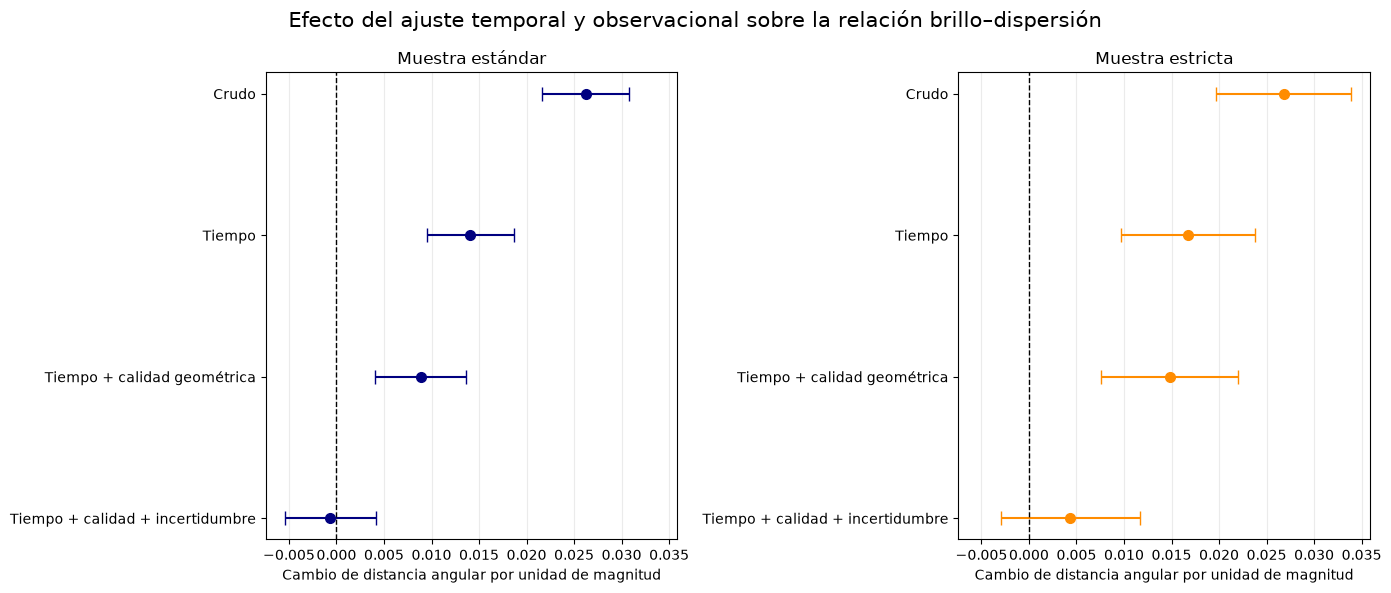

In [199]:
# Graficar la evolución del coeficiente de magnitud al añadir controles

coeficientes_crudos = (
    resumen_modelos_distancia.loc[
        resumen_modelos_distancia["modelo"].eq("Crudo"),
        [
            "muestra",
            "cambio_distancia_por_magnitud",
            "limite_inferior_95",
            "limite_superior_95"
        ]
    ]
    .copy()
)

coeficientes_crudos["modelo_grafica"] = (
    "Crudo"
)

coeficientes_crudos["orden"] = 0


nombres_modelos_grafica = {
    "Temporal 0.5 grados": "Tiempo",
    "Más calidad geométrica": (
        "Tiempo + calidad geométrica"
    ),
    "Más incertidumbre del radiante": (
        "Tiempo + calidad + incertidumbre"
    )
}

coeficientes_ajustados = (
    resumen_sensibilidad_calidad.loc[
        resumen_sensibilidad_calidad["modelo"].isin(
            nombres_modelos_grafica
        ),
        [
            "muestra",
            "modelo",
            "cambio_distancia_por_magnitud",
            "limite_inferior_95",
            "limite_superior_95"
        ]
    ]
    .copy()
)

coeficientes_ajustados["modelo_grafica"] = (
    coeficientes_ajustados["modelo"]
    .map(nombres_modelos_grafica)
)

orden_grafica = {
    "Tiempo": 1,
    "Tiempo + calidad geométrica": 2,
    "Tiempo + calidad + incertidumbre": 3
}

coeficientes_ajustados["orden"] = (
    coeficientes_ajustados["modelo_grafica"]
    .map(orden_grafica)
)


tabla_coeficientes_grafica = pd.concat(
    [
        coeficientes_crudos,
        coeficientes_ajustados
    ],
    ignore_index=True
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    sharex=True
)

colores_muestras = {
    "Estándar": "navy",
    "Estricta": "darkorange"
}


for ax, nombre_muestra in zip(
    axes,
    ["Estándar", "Estricta"]
):
    datos_grafica = (
        tabla_coeficientes_grafica.loc[
            tabla_coeficientes_grafica[
                "muestra"
            ].eq(nombre_muestra)
        ]
        .sort_values("orden")
    )

    posiciones = np.arange(
        len(datos_grafica)
    )

    coeficientes = datos_grafica[
        "cambio_distancia_por_magnitud"
    ].to_numpy()

    errores_inferiores = (
        coeficientes
        - datos_grafica[
            "limite_inferior_95"
        ].to_numpy()
    )

    errores_superiores = (
        datos_grafica[
            "limite_superior_95"
        ].to_numpy()
        - coeficientes
    )

    ax.errorbar(
        coeficientes,
        posiciones,
        xerr=np.vstack([
            errores_inferiores,
            errores_superiores
        ]),
        fmt="o",
        color=colores_muestras[nombre_muestra],
        capsize=5,
        markersize=7
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_yticks(
        posiciones,
        datos_grafica["modelo_grafica"]
    )

    ax.invert_yaxis()

    ax.set_title(
        f"Muestra {nombre_muestra.lower()}"
    )

    ax.set_xlabel(
        "Cambio de distancia angular por unidad de magnitud"
    )

    ax.grid(
        alpha=0.25,
        axis="x"
    )


fig.suptitle(
    "Efecto del ajuste temporal y observacional "
    "sobre la relación brillo–dispersión",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Guardado de la base física

In [200]:
# Inventario de bases candidatas para el guardado final

filas_objetivo = {19079, 7040}

inventario_final = []

for nombre_objeto, objeto in globals().copy().items():

    if not isinstance(objeto, pd.DataFrame):
        continue

    if len(objeto) not in filas_objetivo:
        continue

    columnas_objeto = set(objeto.columns)

    columnas_clave = [
        "source_year",
        "delta_sol",
        "lambda_sce_esperada_deg",
        "beta_esperada_deg",
        "vgeo_esperada_km_s",
        "delta_lambda_tangente_deg",
        "delta_beta_tangente_deg",
        "distancia_angular_deg",
        "residuo_vgeo_km_s",
        "Peak (AbsMag)",
        "Peak Ht (km)"
    ]

    inventario_final.append({
        "nombre_objeto": nombre_objeto,
        "filas": len(objeto),
        "columnas": objeto.shape[1],
        "columnas_clave_presentes": sum(
            columna in columnas_objeto
            for columna in columnas_clave
        ),
        "columnas_clave_esperadas": len(columnas_clave)
    })


df_inventario_final = (
    pd.DataFrame(inventario_final)
    .sort_values(
        ["filas", "columnas_clave_presentes", "columnas"],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

display(df_inventario_final)

,nombre_objeto,filas,columnas,columnas_clave_presentes,columnas_clave_esperadas
0,df_estandar_auditoria,19079,138,7,11
1,df_gem_estandar_brillo,19079,135,7,11
2,df_comparacion_extremos,19079,132,7,11
3,df_gem_estandar_residuos,19079,131,7,11
4,df_gem_estandar_tangente,19079,127,7,11
5,df_gem_estandar_centro,19079,118,7,11
6,df_residuos_comun,19079,115,3,11
7,df_beta_anual,19079,111,3,11
8,df_beta_estandar_lineal,19079,110,3,11
9,df_magnitud_anual,19079,109,3,11


In [201]:
# Fijar copias maestras para la etapa 8

df_final_estandar = df_gem_estandar_brillo.copy()
df_final_estricta = df_gem_estricta_brillo.copy()

print("Base estándar: ", df_final_estandar.shape)

print("Base estricta: ", df_final_estricta.shape)

Base estándar:  (19079, 135)
Base estricta:  (7040, 135)


In [202]:
# Comparar las columnas de ambas bases maestras

columnas_estandar = set(df_final_estandar.columns)
columnas_estricta = set(df_final_estricta.columns)

solo_en_estandar = sorted(columnas_estandar - columnas_estricta)
solo_en_estricta = sorted(columnas_estricta - columnas_estandar)

print("Columnas solo en la estándar:")
print(solo_en_estandar)

print("\nColumnas solo en la estricta:")
print(solo_en_estricta)

print( "\n¿Tienen exactamente las mismas columnas?", columnas_estandar == columnas_estricta)

Columnas solo en la estándar:
[]

Columnas solo en la estricta:
[]

¿Tienen exactamente las mismas columnas? True


In [203]:
# Localizar las columnas procesadas importantes

palabras_clave = [
    "esper",
    "tangent",
    "angular",
    "resid",
    "magn",
    "sospe",
    "peak",
    "incertid",
    "sigma",
    "source_year",
    "delta_sol"
]

columnas_relevantes = []

for columna in df_final_estandar.columns:
    nombre_minusculas = columna.lower()

    if any(palabra in nombre_minusculas for palabra in palabras_clave):
        columnas_relevantes.append(columna)


print("Número de columnas relevantes encontradas:", len(columnas_relevantes))

for columna in columnas_relevantes:
    print(columna)

Número de columnas relevantes encontradas: 55
RAgeo_sigma
DECgeo_sigma
LAMgeo_sigma
BETgeo_sigma
Vgeo_sigma
LAMhel_sigma
BEThel_sigma
Vhel_sigma
a_sigma
e_sigma
i_sigma
peri_sigma
node_sigma
Pi_sigma
b_sigma
q_sigma
f_sigma
M_sigma
Q_sigma
n_sigma
T_sigma
TisserandJ_sigma
RAapp_sigma
DECapp_sigma
Azim_sigma
Elev_sigma
Vinit_sigma
Vavg_sigma
LatBeg_sigma
LonBeg_sigma
HtBeg_sigma
LatEnd_sigma
LonEnd_sigma
HtEnd_sigma
Peak (AbsMag)
Peak Ht (km)
source_year
RAgeo_sigma_cielo
sigma_radiante_aprox
flag_vgeo_sigma_cero
flag_vavg_sigma_cero
cumple_vavg_sigma_1
cumple_sigma_radiante_025
delta_sol_lon_deg
lambda_sce_esperada_deg
beta_esperada_deg
vgeo_esperada_km_s
residuo_lambda_coordenada_deg
residuo_beta_coordenada_deg
residuo_vgeo_km_s
distancia_angular_centro_deg
flag_fotometria_sospechosa
magnitud_analisis
grupo_magnitud
intervalo_delta_sol_brillo


In [204]:
# Comprobar los índices y la relación entre ambas muestras

indices_estandar = set(df_final_estandar.index)
indices_estricta = set(df_final_estricta.index)

resumen_indices = pd.DataFrame([
    {
        "comprobacion": "Índice estándar único",
        "resultado": df_final_estandar.index.is_unique
    },
    {
        "comprobacion": "Índice estricto único",
        "resultado": df_final_estricta.index.is_unique
    },
    {
        "comprobacion": "Estricta contenida en estándar",
        "resultado": indices_estricta.issubset(indices_estandar)
    },
    {
        "comprobacion": "Filas estándar",
        "resultado": len(df_final_estandar)
    },
    {
        "comprobacion": "Filas estrictas",
        "resultado": len(df_final_estricta)
    }
])

display(resumen_indices)

,comprobacion,resultado
0,Índice estándar único,True
1,Índice estricto único,True
2,Estricta contenida en estándar,True
3,Filas estándar,19079
4,Filas estrictas,7040


In [205]:
# Verificar que las variables procesadas compartidas sean idénticas

import numpy as np

columnas_procesadas = [
    "delta_sol_lon_deg",
    "lambda_sce_esperada_deg",
    "beta_esperada_deg",
    "vgeo_esperada_km_s",
    "residuo_lambda_coordenada_deg",
    "residuo_beta_coordenada_deg",
    "residuo_vgeo_km_s",
    "distancia_angular_centro_deg",
    "Peak (AbsMag)",
    "Peak Ht (km)",
    "flag_fotometria_sospechosa",
    "magnitud_analisis"
]

comparacion_filas = []

for columna in columnas_procesadas:
    valores_estandar = (
        df_final_estandar
        .loc[df_final_estricta.index, columna]
        .to_numpy()
    )

    valores_estricta = (
        df_final_estricta[columna]
        .to_numpy()
    )

    if pd.api.types.is_numeric_dtype(
        df_final_estricta[columna]
    ):
        coincide = np.allclose(
            valores_estandar,
            valores_estricta,
            equal_nan=True
        )
    else:
        coincide = (
            pd.Series(valores_estandar)
            .fillna("__FALTANTE__")
            .equals(
                pd.Series(valores_estricta)
                .fillna("__FALTANTE__")
            )
        )

    comparacion_filas.append({
        "variable": columna,
        "coincide": coincide
    })


df_comparacion_filas = pd.DataFrame(
    comparacion_filas
)

display(df_comparacion_filas)

,variable,coincide
0,delta_sol_lon_deg,True
1,lambda_sce_esperada_deg,True
2,beta_esperada_deg,True
3,vgeo_esperada_km_s,True
4,residuo_lambda_coordenada_deg,True
5,residuo_beta_coordenada_deg,True
6,residuo_vgeo_km_s,True
7,distancia_angular_centro_deg,True
8,Peak (AbsMag),True
9,Peak Ht (km),True


In [206]:
# Auditar la exclusión fotométrica

resumen_fotometria_final = []

for nombre_muestra, df_muestra_final in [
    ("Estándar", df_final_estandar),
    ("Estricta", df_final_estricta)
]:

    flag_sospechoso = (
        df_muestra_final[
            "flag_fotometria_sospechosa"
        ].astype(bool)
    )

    magnitud_no_disponible = (
        df_muestra_final[
            "magnitud_analisis"
        ].isna()
    )

    resumen_fotometria_final.append({
        "muestra": nombre_muestra,
        "trayectorias": len(df_muestra_final),
        "fotometrias_sospechosas": int(
            flag_sospechoso.sum()
        ),
        "magnitudes_analisis_faltantes": int(
            magnitud_no_disponible.sum()
        ),
        "sospechosas_convertidas_a_nan": bool(
            magnitud_no_disponible[
                flag_sospechoso
            ].all()
        ),
        "validas_con_magnitud_disponible": bool(
            df_muestra_final.loc[
                ~flag_sospechoso,
                "magnitud_analisis"
            ].notna().all()
        )
    })


df_resumen_fotometria_final = pd.DataFrame(
    resumen_fotometria_final
)

display(df_resumen_fotometria_final)

,muestra,trayectorias,fotometrias_sospechosas,magnitudes_analisis_faltantes,sospechosas_convertidas_a_nan,validas_con_magnitud_disponible
0,Estándar,19079,25,25,True,True
1,Estricta,7040,21,21,True,True


In [207]:
# Construir la base maestra del proyecto

df_base_maestra = df_final_estandar.copy()

df_base_maestra.insert(0, "id_fila_origen", df_base_maestra.index)

df_base_maestra.insert(1, "pertenece_muestra_estandar", True)

df_base_maestra.insert(2, "pertenece_muestra_estricta", df_base_maestra.index.isin(df_final_estricta.index))

df_base_maestra.insert(3, "nivel_seleccion", np.where(df_base_maestra["pertenece_muestra_estricta"], "Estricta", "Estándar no estricta"))

df_base_maestra.insert(4, "fotometria_utilizable", df_base_maestra["magnitud_analisis"].notna())

df_base_maestra = (df_base_maestra.reset_index(drop=True))

In [208]:
# Crear vistas reproducibles de las muestras

df_base_estandar_final = df_base_maestra.loc[df_base_maestra["pertenece_muestra_estandar"]].copy()

df_base_estricta_final = df_base_maestra.loc[df_base_maestra["pertenece_muestra_estricta" ]].copy()

In [209]:
# Resumen de la estructura final

resumen_base_maestra = pd.DataFrame([
    {
        "objeto": "Base maestra",
        "filas": len(df_base_maestra),
        "columnas": df_base_maestra.shape[1],
        "fotometrias_utilizables": int(
            df_base_maestra[
                "fotometria_utilizable"
            ].sum()
        )
    },
    {
        "objeto": "Vista estándar",
        "filas": len(df_base_estandar_final),
        "columnas": df_base_estandar_final.shape[1],
        "fotometrias_utilizables": int(
            df_base_estandar_final[
                "fotometria_utilizable"
            ].sum()
        )
    },
    {
        "objeto": "Vista estricta",
        "filas": len(df_base_estricta_final),
        "columnas": df_base_estricta_final.shape[1],
        "fotometrias_utilizables": int(
            df_base_estricta_final[
                "fotometria_utilizable"
            ].sum()
        )
    }
])

display(resumen_base_maestra)

,objeto,filas,columnas,fotometrias_utilizables
0,Base maestra,19079,140,19054
1,Vista estándar,19079,140,19054
2,Vista estricta,7040,140,7019


In [ ]:
# Localizar las columnas candidatas para la base reducida

patrones_columnas_finales = [
    "time",
    "date",
    "utc",
    "jd",
    "sol",
    "year",
    "shower",
    "iau",
    "station",
    "qc",
    "fit",
    "conv",
    "rageo",
    "decgeo",
    "lamgeo",
    "betgeo",
    "vgeo",
    "peak",
    "magnitud",
    "esperada",
    "residuo",
    "distancia",
    "fotometria",
    "grupo_magnitud",
    "intervalo_delta"
]

filas_catalogo = []

for posicion, columna in enumerate(df_base_maestra.columns):

    nombre_minusculas = columna.lower()

    if any(patron in nombre_minusculas for patron in patrones_columnas_finales):

        filas_catalogo.append({
            "posicion": posicion,
            "variable": columna,
            "tipo": str(
                df_base_maestra[
                    columna
                ].dtype
            ),
            "faltantes": int(
                df_base_maestra[
                    columna
                ].isna().sum()
            ),
            "valores_unicos": int(
                df_base_maestra[
                    columna
                ].nunique(dropna=True)
            )
        })


df_catalogo_candidatas = pd.DataFrame(filas_catalogo)

print(df_catalogo_candidatas.to_string(index=False))

' posicion                      variable                tipo  faltantes  valores_unicos\n        4         fotometria_utilizable                bool          0               2\n        6       Beginning (Julian date)             float64          0           19079\n        7          Beginning (UTC Time) datetime64[us, UTC]          0           19079\n        8                      IAU (No)               int64          0               1\n        9                    IAU (code)              string          0               1\n       10                 Sol lon (deg)             float64          0           18946\n       12                   RAgeo (deg)             float64          0           18560\n       13                   RAgeo_sigma             float64          0            2655\n       14                  DECgeo (deg)             float64          0           17769\n       15                  DECgeo_sigma             float64          0            2276\n       16                  LAMg

 posicion                      variable                tipo  faltantes  valores_unicos
        4         fotometria_utilizable                bool          0               2
        6       Beginning (Julian date)             float64          0           19079
        7          Beginning (UTC Time) datetime64[us, UTC]          0           19079
        8                      IAU (No)               int64          0               1
        9                    IAU (code)              string          0               1
       10                 Sol lon (deg)             float64          0           18946
       12                   RAgeo (deg)             float64          0           18560
       13                   RAgeo_sigma             float64          0            2655
       14                  DECgeo (deg)             float64          0           17769
       15                  DECgeo_sigma             float64          0            2276
       16                  LAMgeo (deg)    

In [214]:
# Columnas principales de la base reducida

columnas_base_reducida = [
    # Trazabilidad y pertenencia
    "id_fila_origen",
    "pertenece_muestra_estandar",
    "pertenece_muestra_estricta",
    "nivel_seleccion",
    "fotometria_utilizable",

    # Fecha y clasificación
    "Beginning (Julian date)",
    "Beginning (UTC Time)",
    "source_year",
    "IAU (No)",
    "IAU (code)",
    "Sol lon (deg)",
    "delta_sol_lon_deg",

    # Radiante y velocidad observados
    "RAgeo (deg)",
    "RAgeo_sigma",
    "DECgeo (deg)",
    "DECgeo_sigma",
    "LAMgeo (deg)",
    "LAMgeo_sigma",
    "BETgeo (deg)",
    "BETgeo_sigma",
    "Vgeo (km/s)",
    "Vgeo_sigma",

    # Calidad observacional
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Participating (stations)",
    "RAgeo_sigma_cielo",
    "sigma_radiante_aprox",

    # Centro esperado
    "lambda_sce_esperada_deg",
    "beta_esperada_deg",
    "vgeo_esperada_km_s",

    # Residuos físicos
    "residuo_lambda_coordenada_deg",
    "residuo_beta_coordenada_deg",
    "residuo_vgeo_km_s",
    "distancia_angular_centro_deg",

    # Fotometría
    "Peak (AbsMag)",
    "magnitud_analisis",
    "flag_fotometria_sospechosa",
    "Peak Ht (km)",
    "grupo_magnitud",
    "intervalo_delta_sol_brillo"
]

In [216]:
# Localizar variables auxiliares relevantes

columnas_auxiliares = []

for columna in df_base_maestra.columns:

    nombre = columna.lower()

    es_flag_calidad = nombre.startswith("cumple_") or nombre.startswith("flag_")

    es_numero_estaciones = (
        "numero_estaciones" in nombre
        or "n_estaciones" in nombre
    )

    es_lambda_sce_observada = (
        "lambda_sce" in nombre
        and "esperada" not in nombre
        and "intercepto" not in nombre
        and "residuo" not in nombre
    )

    if (
        es_flag_calidad
        or es_numero_estaciones
        or es_lambda_sce_observada
    ):
        columnas_auxiliares.append(columna)


for columna in columnas_auxiliares:

    if columna not in columnas_base_reducida:
        columnas_base_reducida.append(columna)

In [217]:
# Comprobar disponibilidad de las columnas seleccionadas

columnas_ausentes = [columna for columna in columnas_base_reducida if columna not in df_base_maestra.columns]

print("Columnas solicitadas:", len(columnas_base_reducida))
print("Columnas ausentes:", columnas_ausentes)

Columnas solicitadas: 48
Columnas ausentes: []


In [218]:
# Construir las bases reducidas

df_analisis_maestra = df_base_maestra[columnas_base_reducida].copy()

df_analisis_estandar = df_analisis_maestra.loc[df_analisis_maestra["pertenece_muestra_estandar"]].copy()

df_analisis_estricta = df_analisis_maestra.loc[df_analisis_maestra["pertenece_muestra_estricta"]].copy()

In [219]:
resumen_bases_reducidas = pd.DataFrame([
    {
        "base": "Maestra completa",
        "filas": len(df_base_maestra),
        "columnas": df_base_maestra.shape[1]
    },
    {
        "base": "Maestra reducida",
        "filas": len(df_analisis_maestra),
        "columnas": df_analisis_maestra.shape[1]
    },
    {
        "base": "Estándar reducida",
        "filas": len(df_analisis_estandar),
        "columnas": df_analisis_estandar.shape[1]
    },
    {
        "base": "Estricta reducida",
        "filas": len(df_analisis_estricta),
        "columnas": df_analisis_estricta.shape[1]
    }
])

display(resumen_bases_reducidas)

print("\nColumnas de la base reducida:")

for numero, columna in enumerate(df_analisis_maestra.columns, start = 1):
    print(f"{numero:02d}. {columna}")

,base,filas,columnas
0,Maestra completa,19079,140
1,Maestra reducida,19079,48
2,Estándar reducida,19079,48
3,Estricta reducida,7040,48



Columnas de la base reducida:
01. id_fila_origen
02. pertenece_muestra_estandar
03. pertenece_muestra_estricta
04. nivel_seleccion
05. fotometria_utilizable
06. Beginning (Julian date)
07. Beginning (UTC Time)
08. source_year
09. IAU (No)
10. IAU (code)
11. Sol lon (deg)
12. delta_sol_lon_deg
13. RAgeo (deg)
14. RAgeo_sigma
15. DECgeo (deg)
16. DECgeo_sigma
17. LAMgeo (deg)
18. LAMgeo_sigma
19. BETgeo (deg)
20. BETgeo_sigma
21. Vgeo (km/s)
22. Vgeo_sigma
23. Qc (deg)
24. MedianFitErr (arcsec)
25. Participating (stations)
26. RAgeo_sigma_cielo
27. sigma_radiante_aprox
28. lambda_sce_esperada_deg
29. beta_esperada_deg
30. vgeo_esperada_km_s
31. residuo_lambda_coordenada_deg
32. residuo_beta_coordenada_deg
33. residuo_vgeo_km_s
34. distancia_angular_centro_deg
35. Peak (AbsMag)
36. magnitud_analisis
37. flag_fotometria_sospechosa
38. Peak Ht (km)
39. grupo_magnitud
40. intervalo_delta_sol_brillo
41. flag_vgeo_sigma_cero
42. flag_vavg_sigma_cero
43. cumple_qc_15
44. cumple_error_ajuste_60

In [220]:
# Documentación de las variables de análisis

documentacion_variables = {
    "id_fila_origen": (
        "Trazabilidad", "sin unidad",
        "Índice de la trayectoria en la base procesada de origen."
    ),
    "pertenece_muestra_estandar": (
        "Selección", "booleano",
        "Indica si la trayectoria pertenece a la muestra estándar."
    ),
    "pertenece_muestra_estricta": (
        "Selección", "booleano",
        "Indica si también satisface los criterios de la muestra estricta."
    ),
    "nivel_seleccion": (
        "Selección", "categoría",
        "Nivel máximo de selección satisfecho por la trayectoria."
    ),
    "fotometria_utilizable": (
        "Fotometría", "booleano",
        "Indica si la magnitud puede utilizarse en el análisis fotométrico."
    ),
    "Beginning (Julian date)": (
        "Tiempo", "día juliano",
        "Instante inicial de la trayectoria expresado como fecha juliana."
    ),
    "Beginning (UTC Time)": (
        "Tiempo", "UTC",
        "Instante inicial de la trayectoria en tiempo universal coordinado."
    ),
    "source_year": (
        "Tiempo", "año",
        "Año calendario utilizado para los ajustes e interceptos anuales."
    ),
    "IAU (No)": (
        "Clasificación", "sin unidad",
        "Número IAU asignado a la lluvia de meteoros."
    ),
    "IAU (code)": (
        "Clasificación", "código",
        "Código IAU de la lluvia; GEM para las Gemínidas."
    ),
    "Sol lon (deg)": (
        "Tiempo", "grados",
        "Longitud solar observada."
    ),
    "delta_sol_lon_deg": (
        "Tiempo", "grados",
        "Longitud solar relativa a la referencia de 262.2 grados."
    ),
    "RAgeo (deg)": (
        "Radiante observado", "grados",
        "Ascensión recta geocéntrica observada."
    ),
    "RAgeo_sigma": (
        "Incertidumbre", "grados",
        "Incertidumbre reportada de la ascensión recta geocéntrica."
    ),
    "DECgeo (deg)": (
        "Radiante observado", "grados",
        "Declinación geocéntrica observada."
    ),
    "DECgeo_sigma": (
        "Incertidumbre", "grados",
        "Incertidumbre reportada de la declinación geocéntrica."
    ),
    "LAMgeo (deg)": (
        "Radiante observado", "grados",
        "Longitud eclíptica geocéntrica observada."
    ),
    "LAMgeo_sigma": (
        "Incertidumbre", "grados",
        "Incertidumbre reportada de la longitud eclíptica geocéntrica."
    ),
    "BETgeo (deg)": (
        "Radiante observado", "grados",
        "Latitud eclíptica geocéntrica observada."
    ),
    "BETgeo_sigma": (
        "Incertidumbre", "grados",
        "Incertidumbre reportada de la latitud eclíptica geocéntrica."
    ),
    "Vgeo (km/s)": (
        "Velocidad observada", "km/s",
        "Velocidad geocéntrica observada."
    ),
    "Vgeo_sigma": (
        "Incertidumbre", "km/s",
        "Incertidumbre reportada de la velocidad geocéntrica."
    ),
    "Qc (deg)": (
        "Calidad", "grados",
        "Ángulo de convergencia geométrica de la trayectoria."
    ),
    "MedianFitErr (arcsec)": (
        "Calidad", "segundos de arco",
        "Error angular mediano del ajuste de la trayectoria."
    ),
    "Participating (stations)": (
        "Calidad", "texto",
        "Estaciones participantes en la observación."
    ),
    "RAgeo_sigma_cielo": (
        "Incertidumbre", "grados",
        "Incertidumbre de ascensión recta expresada como desplazamiento sobre el cielo."
    ),
    "sigma_radiante_aprox": (
        "Incertidumbre", "grados",
        "Incertidumbre angular aproximada del radiante."
    ),
    "lambda_sce_esperada_deg": (
        "Centro esperado", "grados",
        "Longitud eclíptica centrada en el Sol esperada para la fecha y el año."
    ),
    "beta_esperada_deg": (
        "Centro esperado", "grados",
        "Latitud eclíptica geocéntrica esperada para la fecha y el año."
    ),
    "vgeo_esperada_km_s": (
        "Centro esperado", "km/s",
        "Velocidad geocéntrica esperada para la fecha y el año."
    ),
    "residuo_lambda_coordenada_deg": (
        "Residuo físico", "grados",
        "Diferencia longitudinal con signo respecto del centro esperado."
    ),
    "residuo_beta_coordenada_deg": (
        "Residuo físico", "grados",
        "Diferencia latitudinal con signo respecto del centro esperado."
    ),
    "residuo_vgeo_km_s": (
        "Residuo físico", "km/s",
        "Velocidad observada menos velocidad geocéntrica esperada."
    ),
    "distancia_angular_centro_deg": (
        "Residuo físico", "grados",
        "Separación angular esférica entre el radiante observado y el esperado."
    ),
    "Peak (AbsMag)": (
        "Fotometría", "magnitudes",
        "Magnitud absoluta original del máximo de brillo."
    ),
    "magnitud_analisis": (
        "Fotometría", "magnitudes",
        "Magnitud utilizada en los análisis; es NaN cuando la fotometría es sospechosa."
    ),
    "flag_fotometria_sospechosa": (
        "Fotometría", "booleano",
        "Marca magnitudes extremadamente negativas consideradas no confiables."
    ),
    "Peak Ht (km)": (
        "Fotometría", "km",
        "Altura atmosférica del máximo de brillo."
    ),
    "grupo_magnitud": (
        "Fotometría", "categoría",
        "Intervalo de magnitud utilizado para comparaciones descriptivas."
    ),
    "intervalo_delta_sol_brillo": (
        "Tiempo", "categoría",
        "Intervalo de 0.5 grados de longitud solar relativa."
    ),
    "flag_vgeo_sigma_cero": (
        "Calidad", "booleano",
        "Marca incertidumbres de velocidad geocéntrica reportadas como cero."
    ),
    "flag_vavg_sigma_cero": (
        "Calidad", "booleano",
        "Marca incertidumbres de velocidad media reportadas como cero."
    ),
    "cumple_qc_15": (
        "Calidad", "booleano",
        "Indica si el ángulo de convergencia es de al menos 15 grados."
    ),
    "cumple_error_ajuste_60": (
        "Calidad", "booleano",
        "Indica si el error angular mediano del ajuste no supera 60 segundos de arco."
    ),
    "cumple_vavg_sigma_1": (
        "Calidad", "booleano",
        "Indica si la incertidumbre de velocidad media no supera 1 km/s."
    ),
    "cumple_sigma_radiante_025": (
        "Calidad", "booleano",
        "Indica si la incertidumbre aproximada del radiante no supera 0.25 grados."
    ),
    "flag_calidad_incompleta": (
        "Calidad", "booleano",
        "Marca trayectorias con información o criterios de calidad incompletos."
    ),
    "lambda_sce_deg": (
        "Radiante observado", "grados",
        "Longitud eclíptica geocéntrica observada en el sistema centrado en el Sol."
    )
}

In [221]:
# Convertir la documentación en un DataFrame

filas_diccionario = []

for columna in df_analisis_maestra.columns:

    categoria, unidad, descripcion = (
        documentacion_variables.get(
            columna,
            (
                "No documentada",
                "No especificada",
                ""
            )
        )
    )

    filas_diccionario.append({
        "variable": columna,
        "categoria": categoria,
        "tipo_dato": str(
            df_analisis_maestra[
                columna
            ].dtype
        ),
        "unidad": unidad,
        "descripcion": descripcion,
        "valores_faltantes": int(
            df_analisis_maestra[
                columna
            ].isna().sum()
        ),
        "valores_unicos": int(
            df_analisis_maestra[
                columna
            ].nunique(dropna=True)
        )
    })


df_diccionario_variables = pd.DataFrame(filas_diccionario)

In [222]:
# Inventario de las 140 columnas de la base maestra

filas_inventario_tecnico = []

for posicion, columna in enumerate(df_base_maestra.columns):

    filas_inventario_tecnico.append({
        "posicion": posicion,
        "variable": columna,
        "tipo_dato": str(
            df_base_maestra[
                columna
            ].dtype
        ),
        "valores_faltantes": int(
            df_base_maestra[
                columna
            ].isna().sum()
        ),
        "valores_unicos": int(
            df_base_maestra[
                columna
            ].nunique(dropna=True)
        )
    })


df_inventario_tecnico = pd.DataFrame(filas_inventario_tecnico)

In [223]:
resumen_documentacion = pd.DataFrame([
    {
        "comprobacion": "Variables de análisis",
        "resultado": len(
            df_analisis_maestra.columns
        )
    },
    {
        "comprobacion": "Variables documentadas",
        "resultado": len(
            df_diccionario_variables
        )
    },
    {
        "comprobacion": "Descripciones faltantes",
        "resultado": int(
            (
                df_diccionario_variables[
                    "descripcion"
                ] == ""
            ).sum()
        )
    },
    {
        "comprobacion": "Categorías no documentadas",
        "resultado": int(
            (
                df_diccionario_variables[
                    "categoria"
                ] == "No documentada"
            ).sum()
        )
    },
    {
        "comprobacion": "Columnas inventariadas",
        "resultado": len(
            df_inventario_tecnico
        )
    }
])

display(resumen_documentacion)

,comprobacion,resultado
0,Variables de análisis,48
1,Variables documentadas,48
2,Descripciones faltantes,0
3,Categorías no documentadas,0
4,Columnas inventariadas,140


In [ ]:
directorio_actual = Path.cwd().resolve()

carpetas_requeridas = ["data", "notebooks", "src", "reports", "references"]
archivos_requeridos = ["README.md", "pyproject.toml", "uv.lock"]

raiz_proyecto = None

for posible_raiz in [directorio_actual, *directorio_actual.parents]:
    tiene_carpetas = all((posible_raiz / nombre).is_dir() for nombre in carpetas_requeridas)
    tiene_archivos = all((posible_raiz / nombre).is_file() for nombre in archivos_requeridos)

    if tiene_carpetas and tiene_archivos:
        raiz_proyecto = posible_raiz
        break

if raiz_proyecto is None:
    raise FileNotFoundError("No se encontró la carpeta raíz del proyecto Investigacion.")

print("Directorio actual:", directorio_actual)
print("Raíz del proyecto:", raiz_proyecto)

In [227]:
carpeta_datos_procesados = raiz_proyecto / "data" / "processed" / "geminidas_v1"
carpeta_metadatos = carpeta_datos_procesados / "metadata"
carpeta_figuras = raiz_proyecto / "reports" / "figures" / "geminidas_v1"
carpeta_tablas = raiz_proyecto / "reports" / "tables" / "geminidas_v1"

for carpeta in [carpeta_datos_procesados, carpeta_metadatos, carpeta_figuras, carpeta_tablas]:
    carpeta.mkdir(parents=True, exist_ok=True)

print("Datos procesados:", carpeta_datos_procesados)
print("Metadatos:", carpeta_metadatos)
print("Figuras:", carpeta_figuras)
print("Tablas:", carpeta_tablas)

Datos procesados: /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/data/processed/geminidas_v1
Metadatos: /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/data/processed/geminidas_v1/metadata
Figuras: /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/reports/figures/geminidas_v1
Tablas: /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/reports/tables/geminidas_v1


In [228]:
ruta_completa_parquet = carpeta_datos_procesados / "geminidas_base_maestra_completa_v1.parquet"
ruta_estandar_parquet = carpeta_datos_procesados / "geminidas_estandar_analisis_v1.parquet"
ruta_estricta_parquet = carpeta_datos_procesados / "geminidas_estricta_analisis_v1.parquet"

ruta_estandar_csv = carpeta_datos_procesados / "geminidas_estandar_analisis_v1.csv"
ruta_estricta_csv = carpeta_datos_procesados / "geminidas_estricta_analisis_v1.csv"

ruta_diccionario = carpeta_metadatos / "diccionario_variables_geminidas_v1.csv"
ruta_inventario = carpeta_metadatos / "inventario_tecnico_geminidas_v1.csv"
ruta_resumen = carpeta_metadatos / "resumen_bases_geminidas_v1.csv"
ruta_verificacion = carpeta_metadatos / "verificacion_guardado_v1.csv"
ruta_manifiesto = carpeta_metadatos / "manifiesto_integridad_v1.csv"

In [230]:
filas_categorias = []

for columna in df_base_maestra.columns:
    serie = df_base_maestra[columna]

    if isinstance(serie.dtype, pd.CategoricalDtype):
        categorias = serie.cat.categories
        tipo_valores = type(categorias[0]).__name__ if len(categorias) > 0 else "sin categorías"

        filas_categorias.append({
            "variable": columna,
            "tipo_dato": str(serie.dtype),
            "ordenada": serie.cat.ordered,
            "tipo_valores": tipo_valores,
            "numero_categorias": len(categorias),
            "categorias": list(categorias)
        })

    elif isinstance(serie.dtype, pd.IntervalDtype):
        filas_categorias.append({
            "variable": columna,
            "tipo_dato": str(serie.dtype),
            "ordenada": True,
            "tipo_valores": "Interval",
            "numero_categorias": serie.nunique(dropna=True),
            "categorias": list(serie.dropna().unique())
        })

df_auditoria_categorias = pd.DataFrame(filas_categorias)

display(df_auditoria_categorias)

,variable,tipo_dato,ordenada,tipo_valores,numero_categorias,categorias
0,grupo_magnitud,category,True,str,4,"[M ≤ -1, -1 < M ≤ 0, 0 < M ≤ 1, M > 1]"
1,intervalo_delta_sol_brillo,category,True,Interval,14,"[[-5.0, -4.5), [-4.5, -4.0), [-4.0, -3.5), [-3..."


In [231]:
orden_grupos_magnitud = {
    "M ≤ -1": 0,
    "-1 < M ≤ 0": 1,
    "0 < M ≤ 1": 2,
    "M > 1": 3
}

def preparar_base_portable(df):
    df_portable = df.copy()

    grupos_texto = df_portable["grupo_magnitud"].astype("string")
    codigos_grupo = grupos_texto.map(orden_grupos_magnitud).astype("Int64")

    etiquetas_desconocidas = grupos_texto.notna() & codigos_grupo.isna()

    if etiquetas_desconocidas.any():
        raise ValueError("Se encontraron grupos de magnitud no reconocidos.")

    posicion_grupo = df_portable.columns.get_loc("grupo_magnitud") + 1
    df_portable["grupo_magnitud"] = grupos_texto
    df_portable.insert(posicion_grupo, "grupo_magnitud_orden", codigos_grupo)

    intervalos = df_portable["intervalo_delta_sol_brillo"].astype(object)
    limites_inferiores = intervalos.map(lambda valor: float(valor.left) if isinstance(valor, pd.Interval) else np.nan)
    limites_superiores = intervalos.map(lambda valor: float(valor.right) if isinstance(valor, pd.Interval) else np.nan)
    etiquetas_intervalos = intervalos.map(lambda valor: str(valor) if isinstance(valor, pd.Interval) else pd.NA).astype("string")

    posicion_intervalo = df_portable.columns.get_loc("intervalo_delta_sol_brillo") + 1
    df_portable["intervalo_delta_sol_brillo"] = etiquetas_intervalos
    df_portable.insert(posicion_intervalo, "intervalo_delta_sol_inferior_deg", limites_inferiores)
    df_portable.insert(posicion_intervalo + 1, "intervalo_delta_sol_superior_deg", limites_superiores)

    return df_portable

In [232]:
df_export_completa = preparar_base_portable(df_base_maestra)
df_export_estandar = preparar_base_portable(df_analisis_estandar)
df_export_estricta = preparar_base_portable(df_analisis_estricta)

In [233]:
documentacion_variables["grupo_magnitud"] = (
    "Fotometría",
    "texto",
    "Etiqueta textual del intervalo de magnitud utilizado para comparaciones descriptivas."
)

documentacion_variables["grupo_magnitud_orden"] = (
    "Fotometría",
    "código entero",
    "Orden numérico de los grupos de magnitud, desde los meteoros más brillantes hasta los más tenues."
)

documentacion_variables["intervalo_delta_sol_brillo"] = (
    "Tiempo",
    "texto",
    "Etiqueta textual del intervalo de longitud solar relativa; los intervalos son cerrados a la izquierda y abiertos a la derecha."
)

documentacion_variables["intervalo_delta_sol_inferior_deg"] = (
    "Tiempo",
    "grados",
    "Límite inferior incluido del intervalo de longitud solar relativa."
)

documentacion_variables["intervalo_delta_sol_superior_deg"] = (
    "Tiempo",
    "grados",
    "Límite superior excluido del intervalo de longitud solar relativa."
)

In [234]:
filas_diccionario = []

for columna in df_export_estandar.columns:
    categoria, unidad, descripcion = documentacion_variables.get(columna, ("No documentada", "No especificada", ""))

    filas_diccionario.append({
        "variable": columna,
        "categoria": categoria,
        "tipo_dato": str(df_export_estandar[columna].dtype),
        "unidad": unidad,
        "descripcion": descripcion,
        "valores_faltantes": int(df_export_estandar[columna].isna().sum()),
        "valores_unicos": int(df_export_estandar[columna].nunique(dropna=True))
    })

df_diccionario_variables = pd.DataFrame(filas_diccionario)

In [235]:
filas_inventario_tecnico = []

for posicion, columna in enumerate(df_export_completa.columns):
    filas_inventario_tecnico.append({
        "posicion": posicion,
        "variable": columna,
        "tipo_dato": str(df_export_completa[columna].dtype),
        "valores_faltantes": int(df_export_completa[columna].isna().sum()),
        "valores_unicos": int(df_export_completa[columna].nunique(dropna=True))
    })

df_inventario_tecnico = pd.DataFrame(filas_inventario_tecnico)

In [236]:
resumen_bases_reducidas = pd.DataFrame([
    {
        "base": "Maestra completa portable",
        "filas": len(df_export_completa),
        "columnas": df_export_completa.shape[1]
    },
    {
        "base": "Estándar de análisis portable",
        "filas": len(df_export_estandar),
        "columnas": df_export_estandar.shape[1]
    },
    {
        "base": "Estricta de análisis portable",
        "filas": len(df_export_estricta),
        "columnas": df_export_estricta.shape[1]
    }
])

display(resumen_bases_reducidas)

,base,filas,columnas
0,Maestra completa portable,19079,143
1,Estándar de análisis portable,19079,51
2,Estricta de análisis portable,7040,51


In [237]:
pares_portables = [
    ("Completa", df_base_maestra, df_export_completa),
    ("Estándar", df_analisis_estandar, df_export_estandar),
    ("Estricta", df_analisis_estricta, df_export_estricta)
]

filas_auditoria_portable = []

for nombre, original, portable in pares_portables:
    intervalos_originales = original["intervalo_delta_sol_brillo"].astype(object)
    inferiores_originales = intervalos_originales.map(lambda valor: float(valor.left) if isinstance(valor, pd.Interval) else np.nan)
    superiores_originales = intervalos_originales.map(lambda valor: float(valor.right) if isinstance(valor, pd.Interval) else np.nan)

    grupos_originales = original["grupo_magnitud"].astype("string")
    codigos_esperados = grupos_originales.map(orden_grupos_magnitud).astype("Int64")

    filas_auditoria_portable.append({
        "base": nombre,
        "filas_conservadas": len(original) == len(portable),
        "columnas_agregadas": portable.shape[1] - original.shape[1],
        "etiquetas_grupo_conservadas": grupos_originales.equals(portable["grupo_magnitud"]),
        "orden_grupo_correcto": codigos_esperados.equals(portable["grupo_magnitud_orden"]),
        "limites_inferiores_correctos": np.allclose(inferiores_originales, portable["intervalo_delta_sol_inferior_deg"], equal_nan=True),
        "limites_superiores_correctos": np.allclose(superiores_originales, portable["intervalo_delta_sol_superior_deg"], equal_nan=True)
    })

df_auditoria_portable = pd.DataFrame(filas_auditoria_portable)

display(df_auditoria_portable)

,base,filas_conservadas,columnas_agregadas,etiquetas_grupo_conservadas,orden_grupo_correcto,limites_inferiores_correctos,limites_superiores_correctos
0,Completa,True,3,True,True,True,True
1,Estándar,True,3,True,True,True,True
2,Estricta,True,3,True,True,True,True


In [238]:
ruta_auditoria_portable = carpeta_metadatos / "auditoria_conversion_portable_v1.csv"

In [239]:
descripciones_faltantes = (df_diccionario_variables["descripcion"] == "").sum()
categorias_no_documentadas = (df_diccionario_variables["categoria"] == "No documentada").sum()

if len(df_diccionario_variables) != 51:
    raise ValueError("El diccionario no contiene las 51 variables exportables.")

if descripciones_faltantes != 0 or categorias_no_documentadas != 0:
    raise ValueError("Existen variables exportables sin documentar.")

print("Variables documentadas:", len(df_diccionario_variables))
print("Descripciones faltantes:", descripciones_faltantes)
print("Categorías no documentadas:", categorias_no_documentadas)

Variables documentadas: 51
Descripciones faltantes: 0
Categorías no documentadas: 0


In [240]:
df_export_completa.to_parquet(ruta_completa_parquet, index=False, compression="snappy")
df_export_estandar.to_parquet(ruta_estandar_parquet, index=False, compression="snappy")
df_export_estricta.to_parquet(ruta_estricta_parquet, index=False, compression="snappy")

df_export_estandar.to_csv(ruta_estandar_csv, index=False, encoding="utf-8-sig")
df_export_estricta.to_csv(ruta_estricta_csv, index=False, encoding="utf-8-sig")

print("Las bases portables fueron guardadas.")

Las bases portables fueron guardadas.


In [241]:
df_diccionario_variables.to_csv(ruta_diccionario, index=False, encoding="utf-8-sig")
df_inventario_tecnico.to_csv(ruta_inventario, index=False, encoding="utf-8-sig")
resumen_bases_reducidas.to_csv(ruta_resumen, index=False, encoding="utf-8-sig")
df_auditoria_portable.to_csv(ruta_auditoria_portable, index=False, encoding="utf-8-sig")

print("Los metadatos fueron guardados.")

Los metadatos fueron guardados.


In [242]:
df_leida_completa = pd.read_parquet(ruta_completa_parquet)
df_leida_estandar_parquet = pd.read_parquet(ruta_estandar_parquet)
df_leida_estricta_parquet = pd.read_parquet(ruta_estricta_parquet)

df_leida_estandar_csv = pd.read_csv(ruta_estandar_csv)
df_leida_estricta_csv = pd.read_csv(ruta_estricta_csv)

In [243]:
pares_verificacion = [
    ("Maestra completa Parquet", df_export_completa, df_leida_completa),
    ("Estándar Parquet", df_export_estandar, df_leida_estandar_parquet),
    ("Estricta Parquet", df_export_estricta, df_leida_estricta_parquet),
    ("Estándar CSV", df_export_estandar, df_leida_estandar_csv),
    ("Estricta CSV", df_export_estricta, df_leida_estricta_csv)
]

filas_verificacion = []

for nombre_archivo, original, recuperada in pares_verificacion:
    distancia_original = original["distancia_angular_centro_deg"].to_numpy(dtype=float)
    distancia_recuperada = recuperada["distancia_angular_centro_deg"].to_numpy(dtype=float)
    codigos_originales = pd.to_numeric(original["grupo_magnitud_orden"], errors="coerce").to_numpy(dtype=float)
    codigos_recuperados = pd.to_numeric(recuperada["grupo_magnitud_orden"], errors="coerce").to_numpy(dtype=float)

    grupos_originales = original["grupo_magnitud"].astype("string").fillna("__FALTANTE__")
    grupos_recuperados = recuperada["grupo_magnitud"].astype("string").fillna("__FALTANTE__")
    intervalos_originales = original["intervalo_delta_sol_brillo"].astype("string").fillna("__FALTANTE__")
    intervalos_recuperados = recuperada["intervalo_delta_sol_brillo"].astype("string").fillna("__FALTANTE__")

    filas_verificacion.append({
        "archivo": nombre_archivo,
        "filas_correctas": len(original) == len(recuperada),
        "columnas_correctas": list(original.columns) == list(recuperada.columns),
        "identificadores_correctos": original["id_fila_origen"].tolist() == recuperada["id_fila_origen"].tolist(),
        "grupos_magnitud_correctos": grupos_originales.tolist() == grupos_recuperados.tolist(),
        "intervalos_solares_correctos": intervalos_originales.tolist() == intervalos_recuperados.tolist(),
        "codigos_grupo_correctos": np.allclose(codigos_originales, codigos_recuperados, equal_nan=True),
        "error_maximo_distancia": np.nanmax(np.abs(distancia_original - distancia_recuperada))
    })

df_verificacion_guardado = pd.DataFrame(filas_verificacion)

display(df_verificacion_guardado)

,archivo,filas_correctas,columnas_correctas,identificadores_correctos,grupos_magnitud_correctos,intervalos_solares_correctos,codigos_grupo_correctos,error_maximo_distancia
0,Maestra completa Parquet,True,True,True,True,True,True,0.0
1,Estándar Parquet,True,True,True,True,True,True,0.0
2,Estricta Parquet,True,True,True,True,True,True,0.0
3,Estándar CSV,True,True,True,True,True,True,0.0
4,Estricta CSV,True,True,True,True,True,True,0.0


In [244]:
df_verificacion_guardado.to_csv(ruta_verificacion, index=False, encoding="utf-8-sig")

In [245]:
def calcular_sha256(ruta_archivo):
    generador_hash = hashlib.sha256()

    with open(ruta_archivo, "rb") as archivo:
        while True:
            bloque = archivo.read(1024 * 1024)

            if not bloque:
                break

            generador_hash.update(bloque)

    return generador_hash.hexdigest()

In [246]:
rutas_entregables = [
    ruta_completa_parquet,
    ruta_estandar_parquet,
    ruta_estricta_parquet,
    ruta_estandar_csv,
    ruta_estricta_csv,
    ruta_diccionario,
    ruta_inventario,
    ruta_resumen,
    ruta_auditoria_portable,
    ruta_verificacion
]

filas_manifiesto = []

for ruta_archivo in rutas_entregables:
    filas_manifiesto.append({
        "archivo": str(ruta_archivo.relative_to(carpeta_datos_procesados)),
        "tamano_bytes": ruta_archivo.stat().st_size,
        "sha256": calcular_sha256(ruta_archivo)
    })

df_manifiesto_integridad = pd.DataFrame(filas_manifiesto)
df_manifiesto_integridad.to_csv(ruta_manifiesto, index=False, encoding="utf-8-sig")

display(df_manifiesto_integridad)

,archivo,tamano_bytes,sha256
0,geminidas_base_maestra_completa_v1.parquet,13685355,00d2042cf523b31b4f11d790c7c221a08a5f5f4de4d804...
1,geminidas_estandar_analisis_v1.parquet,4306866,1917ea6659700e0751f1c80f159e7ca3810bc83350cbbb...
2,geminidas_estricta_analisis_v1.parquet,1667226,d0f46521c99b6bb1ad11843ecd2fb74c815ff8563c70eb...
3,geminidas_estandar_analisis_v1.csv,10357493,833ed5c3c6afbd8448a75c1c1aa2c26bf4419f09f46840...
4,geminidas_estricta_analisis_v1.csv,3882173,209f453ce1da9022c76c59942eef2f05e5335ed496106a...
5,metadata/diccionario_variables_geminidas_v1.csv,5947,82fd6aad78a0bc42b670529ab41c56a448afb663c8263b...
6,metadata/inventario_tecnico_geminidas_v1.csv,4696,f1246b6ce7f383aa0bd2c50fdceba4d2f78d9be3fc0f35...
7,metadata/resumen_bases_geminidas_v1.csv,139,6a50477967b6e68184bdb907be38e339798f3a3053023c...
8,metadata/auditoria_conversion_portable_v1.csv,261,07780f70df6d50b753b6932684a0ed34d0f17cbad2e671...
9,metadata/verificacion_guardado_v1.csv,431,509735402e45dab70708b6ea42d7c675f466e532d62c9b...


In [247]:
print("Archivos generados:\n")

for ruta_archivo in sorted(carpeta_datos_procesados.rglob("*")):
    if ruta_archivo.is_file():
        print(ruta_archivo.relative_to(raiz_proyecto))

Archivos generados:

data/processed/geminidas_v1/geminidas_base_maestra_completa_v1.parquet
data/processed/geminidas_v1/geminidas_estandar_analisis_v1.csv
data/processed/geminidas_v1/geminidas_estandar_analisis_v1.parquet
data/processed/geminidas_v1/geminidas_estricta_analisis_v1.csv
data/processed/geminidas_v1/geminidas_estricta_analisis_v1.parquet
data/processed/geminidas_v1/metadata/auditoria_conversion_portable_v1.csv
data/processed/geminidas_v1/metadata/diccionario_variables_geminidas_v1.csv
data/processed/geminidas_v1/metadata/inventario_tecnico_geminidas_v1.csv
data/processed/geminidas_v1/metadata/manifiesto_integridad_v1.csv
data/processed/geminidas_v1/metadata/resumen_bases_geminidas_v1.csv
data/processed/geminidas_v1/metadata/verificacion_guardado_v1.csv
